### Install real libraries FIRST, before anything imports or checks for them

This must be the first code cell that runs. `XGBoost`, `SHAP`, and `LIME` all have working fallbacks if missing (see the next cell), but the fallbacks silently take over and print only a one-line notice if a package is installed *after* the import check below has already run and cached the result -- this happened in every prior run of this notebook for `lime` specifically, because it was being installed in a cell placed after the import check. Installing here, first, prevents that regardless of what other cells get added later.

In [1]:
!pip install xgboost shap lime --quiet


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 7.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


# Lifecycle-Aware Explainable AI for B2B SaaS Customer Churn

Implementation notebook for Hanaa Khan's SSBM Geneva DBA research proposal,
*"Predicting Customer Churn in B2B SaaS Platforms Using Explainable AI (XAI)"*.

This notebook implements **Stages 2-5** of the proposed methodology (Section 5.1) on the
IBM Telco Customer Churn dataset, used throughout as the proxy for a subscription-based
SaaS environment:

1. **Stage 2** - Data preprocessing and tenure-based lifecycle segmentation (onboarding / growth / renewal / maturity)
2. **Stage 3** - Predictive modeling: 5 algorithms x 5 variants (pooled + 4 stage-specific) = 25 base models, Stratified 5-fold CV, pooled-vs-stage Wilcoxon comparison
3. **Stage 4** - Explainable AI: SHAP (global, stage-level) + LIME (local, per-customer), Spearman rank correlation between them, Kruskal-Wallis test across stages, perturbation validation
4. **Stage 5** - Lifecycle-based retention playbook generated from the Stage-4 drivers

**About the algorithm/XAI libraries.** This notebook is written to use real **XGBoost**,
**SHAP**, and **LIME** wherever they're installed. If a package is missing it falls back
automatically to a close substitute (`GradientBoostingClassifier` for XGBoost,
permutation importance for SHAP, a small from-scratch local-surrogate explainer for LIME)
so the notebook still runs end-to-end and nothing silently breaks. Before running this for
real thesis results, install the real packages so you get the actual methods the proposal
specifies:

```bash
pip install xgboost shap lime
```

**Runtime note.** The grid-search parameter grids below are deliberately small so the
notebook finishes in a few minutes even on a modest machine. Widen `param_grid` in the
"Model definitions" cell once you're happy with the pipeline and are running for real
results.

**Data file.** Place `Telco_customer_churn_2.xlsx` in the same folder as this notebook
(or edit `DATA_PATH` below).


In [2]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, confusion_matrix)

RANDOM_STATE = 42

# XGBoost is preferred (matches proposal); fall back to GradientBoosting if unavailable
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost not installed -> falling back to GradientBoostingClassifier for the 'XGBoost' slot. "
          "Run `pip install xgboost` and re-run this cell to use real XGBoost.")

# SHAP is preferred for global explanations; fall back to permutation importance
try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False
    print("shap not installed -> global explanations will fall back to permutation importance. "
          "Run `pip install shap` and re-run to use real SHAP.")

# LIME is preferred for local explanations; fall back to a small local-surrogate approximation
try:
    from lime.lime_tabular import LimeTabularExplainer
    HAS_LIME = True
except ImportError:
    HAS_LIME = False
    print("lime not installed -> local explanations will fall back to a simple local-surrogate "
          "approximation. Run `pip install lime` and re-run to use real LIME.")


### Verify the real libraries actually loaded

Do not trust any result below this point until this prints `XGBoost: True  SHAP: True  LIME: True`. If any is `False`, **restart the runtime** (Runtime > Restart session) and run all cells again from the top -- a plain re-run without restarting will not fix it, since Python does not re-check an import that already failed once in the same running session.

In [3]:
print(f"XGBoost: {HAS_XGB}  SHAP: {HAS_SHAP}  LIME: {HAS_LIME}")
assert HAS_XGB and HAS_SHAP and HAS_LIME, (
    "One or more real libraries did not load -- restart the runtime "
    "(Runtime > Restart session) and run all cells again from the top "
    "before trusting any result below this point.")


XGBoost: True  SHAP: True  LIME: True


## Stage 2 - Data Loading, Preprocessing, and Lifecycle Segmentation

Loads the IBM Telco Customer Churn dataset, drops identifiers/geography and IBM-added
fields that would leak the label (`Churn Score` is IBM's own predicted churn probability;
`Churn Reason` and `Churn Label` directly restate the target; `CLTV` is a post-hoc
business metric, not a pre-churn predictor).

In [5]:
DATA_PATH = "../data/Telco_customer_churn.xlsx"  # place this file alongside the notebook

df_raw = pd.read_excel(DATA_PATH)
print(f"Loaded {df_raw.shape[0]} customers, {df_raw.shape[1]} raw columns")

# Columns to drop: identifiers, geography (out of scope for the SaaS-proxy framework),
# and IBM-added fields that would leak the label (Churn Score is IBM's own predicted
# churn probability; Churn Reason and Churn Label are direct restatements of the target; CLTV is a
# post-hoc business metric not available as a pre-churn predictor).
DROP_COLS = ['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long',
             'Latitude', 'Longitude', 'Churn Label', 'Churn Score', 'CLTV', 'Churn Reason']

df = df_raw.drop(columns=[c for c in DROP_COLS if c in df_raw.columns]).copy()
df = df.rename(columns={'Tenure Months': 'Tenure', 'Churn Value': 'Churn'})

# Total Charges arrives as text with blank strings for brand-new (tenure=0) customers
df['Total Charges'] = pd.to_numeric(df['Total Charges'], errors='coerce')

print(df.shape)
print(df['Churn'].value_counts(normalize=True))
print(df.isna().sum()[df.isna().sum() > 0])


Loaded 7043 customers, 33 raw columns
(7043, 20)
Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64
Total Charges    11
dtype: int64


### Train/test split first, then feature engineering and lifecycle segmentation

Per Section 5.1.2, the split happens *before* any fitting-based preprocessing to avoid
leakage: the `Total Charges` imputation value, the base-plan-price-per-tier lookup, and
the tenure-quartile stage boundaries are all fit on the training split only, then applied
unchanged to the test split.

**SaaS-proxy feature mapping.** Section 5.1.2 frames the Telco dataset as a proxy for a
subscription-based SaaS environment; the table below is what that mapping actually looks
like column-by-column, and motivates the feature engineering in this cell.

| Telco construct | SaaS/B2B analog | Notes |
|---|---|---|
| `Contract` (Month-to-month/1yr/2yr) | Subscription commitment term | Direct analog - the strongest mapping in the dataset |
| `Internet Service` (DSL/Fiber/No) | Core product tier / plan level | "No" = no active subscription |
| The 6 add-on columns (Online Security, Online Backup, Device Protection, Tech Support, Streaming TV, Streaming Movies) | Paid add-on modules / feature adoption | Maps well to SaaS add-on seats/modules |
| `Monthly Charges` | MRR (monthly recurring revenue) per account | |
| `Total Charges` | Cumulative revenue to date | |
| `Tenure` | Months since signup | |
| `Payment Method` / `Paperless Billing` | Billing self-service / autopay adoption | Weaker signal, but usable in both domains |
| `Multiple Lines` | Multi-seat/multi-user account | |
| `Partner`, `Dependents`, `Senior Citizen`, `Gender` | **No clean B2B SaaS analog** | B2C household demographics with no natural SaaS counterpart - kept as predictors since they carry real signal in this dataset, but flagged here as a genuine limitation of the proxy, not silently repurposed |

Two things below follow directly from this mapping, not just from generic data cleaning:
- The 6 add-on columns and `Multiple Lines` each carry a level ("No internet service" /
  "No phone service") that only exists because the customer lacks the *prerequisite*
  service. A SaaS account with no active subscription isn't "ineligible for the Security
  module in a special way" - it's just a non-adopter, same as any other. Collapsing these
  down to a plain "No" removes a redundant category (this is also what resolves the
  Stage 4f collinearity finding below, not just a naming change).
- `Expansion Revenue Ratio` and `Multi-Product Adoption` are new features motivated by
  standard SaaS churn-modeling constructs (expansion revenue, multi-product adoption) that
  don't exist as direct Telco columns.

In [6]:
# --- 5.1.2 Stage 2: train/test split FIRST, to avoid any leakage from fitting on the full data ---
X_full = df.drop(columns=['Churn'])
y_full = df['Churn']

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.20, stratify=y_full, random_state=RANDOM_STATE
)
print(f"Train: {X_train_raw.shape[0]}  Test: {X_test_raw.shape[0]}")
print("Train churn rate:", y_train.mean().round(4), " Test churn rate:", y_test.mean().round(4))

ADDON_COLS = ['Online Security', 'Online Backup', 'Device Protection',
              'Tech Support', 'Streaming TV', 'Streaming Movies']

# --- SaaS-proxy feature engineering (Section 5.1.2 item 4, extended) ---
# The 6 add-on columns and Multiple Lines each carry a level that only exists because
# the customer lacks the PREREQUISITE service (e.g. "No internet service" can only occur
# when Internet Service == "No"). In a SaaS analog, an account that has no active
# subscription is not "ineligible for the Security module in a special way" -- it's just
# not subscribed, same as any other non-adopter. Collapsing these levels down to a plain
# "No" removes a redundant category that exactly restates information already carried by
# Internet Service / Phone Service (see the Stage 4f VIF check -- this collapsing is what
# resolves that finding, not just a naming change).
def _collapse_prerequisite_levels(X):
    X = X.copy()
    for col in ADDON_COLS:
        X[col] = X[col].replace('No internet service', 'No')
    X['Multiple Lines'] = X['Multiple Lines'].replace('No phone service', 'No')
    return X

def engineer_features(X, total_charges_median, base_charge_by_tier):
    """All transforms below are fit-free (deterministic) except total_charges_median and
    base_charge_by_tier, which are passed in already fitted on the training split."""
    X = X.copy()
    X['Total Charges'] = X['Total Charges'].fillna(total_charges_median)
    X = _collapse_prerequisite_levels(X)

    # Engagement / adoption features (Section 5.1.2, item 4)
    X['Num Addon Services'] = (X[ADDON_COLS] == 'Yes').sum(axis=1)        # SaaS analog: feature-module adoption count
    X['Avg Monthly Spend'] = X['Total Charges'] / (X['Tenure'] + 1)        # SaaS analog: realized ARPU to date
    X['Charges Per Service'] = X['Monthly Charges'] / (X['Num Addon Services'] + 1)

    # New: Expansion Revenue Ratio -- SaaS analog of "how much of this account's MRR
    # comes from add-on/expansion revenue vs. the base plan". base_charge_by_tier is the
    # median Monthly Charges among *zero-addon* customers on the same Internet Service
    # tier (fit on train), used as an estimate of "base plan price" for that tier.
    tier_base = X['Internet Service'].map(base_charge_by_tier).fillna(X['Monthly Charges'])
    X['Expansion Revenue Ratio'] = ((X['Monthly Charges'] - tier_base) / X['Monthly Charges']).clip(lower=0)

    # New: Multi-Product Adoption -- SaaS analog of a customer using more than one core
    # product line (not a linear restatement of either input alone -- it's their AND)
    X['Multi-Product Adoption'] = ((X['Internet Service'] != 'No') & (X['Phone Service'] == 'Yes')).astype(int)

    return X

total_charges_median_train = X_train_raw['Total Charges'].median()  # kept for reference/comparison only
# Domain-informed fix: every missing Total Charges value belongs to a Tenure==0 customer
# (confirmed directly against the raw data) who hasn't been billed a full cycle yet.
# Imputing with the population median (which reflects years of typical billing) produced
# an absurd Avg Monthly Spend once divided by (Tenure+1)=1 for these customers -- fixed
# by imputing with 0, the domain-correct "not billed yet" value.
TOTAL_CHARGES_FILL_VALUE = 0.0

# Fit the base-charge-per-tier lookup on TRAIN only, using zero-addon customers as the
# "base plan, no expansion" reference point for each Internet Service tier
_train_collapsed = _collapse_prerequisite_levels(X_train_raw)
_zero_addon_mask = (_train_collapsed[ADDON_COLS] == 'No').all(axis=1)
base_charge_by_tier = (_train_collapsed.loc[_zero_addon_mask]
                        .groupby('Internet Service')['Monthly Charges'].median().to_dict())
print("Estimated base-plan MRR per tier (from zero-addon customers in train):", base_charge_by_tier)

X_train = engineer_features(X_train_raw, TOTAL_CHARGES_FILL_VALUE, base_charge_by_tier)
X_test = engineer_features(X_test_raw, TOTAL_CHARGES_FILL_VALUE, base_charge_by_tier)

# --- Lifecycle segmentation: empirical tenure quartiles fitted on TRAIN only (Section 5.1.2) ---
quartile_edges = X_train['Tenure'].quantile([0.25, 0.5, 0.75]).values
bin_edges = [-np.inf, quartile_edges[0], quartile_edges[1], quartile_edges[2], np.inf]
stage_labels = ['Onboarding', 'Growth', 'Renewal', 'Maturity']

def assign_stage(tenure_series):
    return pd.cut(tenure_series, bins=bin_edges, labels=stage_labels)

X_train['Lifecycle Stage'] = assign_stage(X_train['Tenure'])
X_test['Lifecycle Stage'] = assign_stage(X_test['Tenure'])

print("\nTrain-derived tenure quartile edges (months):", quartile_edges.round(1))
print("\nTrain stage counts:\n", X_train['Lifecycle Stage'].value_counts().sort_index())
print("\nTest stage counts:\n", X_test['Lifecycle Stage'].value_counts().sort_index())
print("\nChurn rate by stage (train):\n", y_train.groupby(X_train['Lifecycle Stage'].values).mean())


Train: 5634  Test: 1409
Train churn rate: 0.2654  Test churn rate: 0.2654
Estimated base-plan MRR per tier (from zero-addon customers in train): {'DSL': 44.75, 'Fiber optic': 70.65, 'No': 20.15}

Train-derived tenure quartile edges (months): [ 9. 29. 55.]

Train stage counts:
 Lifecycle Stage
Onboarding    1463
Growth        1377
Renewal       1386
Maturity      1408
Name: count, dtype: int64

Test stage counts:
 Lifecycle Stage
Onboarding    391
Growth        338
Renewal       333
Maturity      347
Name: count, dtype: int64

Churn rate by stage (train):
 Onboarding    0.496924
Growth        0.286855
Renewal       0.186869
Maturity      0.080966
Name: Churn, dtype: float64


In [7]:
# --- Preprocessing pipeline (encoding + scaling), refit inside each model's Pipeline
# so every variant (pooled / each stage) gets its own leakage-free fit on its own training rows ---

CATEGORICAL_COLS = ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
                     'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup',
                     'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies',
                     'Contract', 'Paperless Billing', 'Payment Method']

NUMERIC_COLS = ['Tenure', 'Monthly Charges', 'Total Charges', 'Num Addon Services',
                'Avg Monthly Spend', 'Charges Per Service', 'Expansion Revenue Ratio']
# NOTE: 'Multi-Product Adoption' is computed in engineer_features() but deliberately left
# out of the model's feature set. It looked like new information (an AND of Internet
# Service and Phone Service), but this dataset has a structural zero -- zero customers
# lack BOTH services -- which makes it an exact (R^2=1.0) linear restatement of the other
# two once both are already in the model. Confirmed via the same VIF-style check as
# Stage 4f. Kept as a computed column for any exploratory/narrative use, not as a predictor.

FEATURE_COLS = CATEGORICAL_COLS + NUMERIC_COLS  # 'Lifecycle Stage' is used for slicing only, never as a predictor

def make_preprocessor():
    return ColumnTransformer([
        ('num', StandardScaler(), NUMERIC_COLS),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), CATEGORICAL_COLS),
    ])

print(f"{len(FEATURE_COLS)} predictor columns ({len(NUMERIC_COLS)} numeric + {len(CATEGORICAL_COLS)} categorical)")


23 predictor columns (7 numeric + 16 categorical)


### Feature audit: catch collinearity and imputation bugs before modeling, not after

Three separate manual investigations earlier in this notebook's development (Stage 4f/4g)
each found a real problem - three exact-duplicate engineered flags, a dataset-specific
interaction redundancy, and an imputation bug that silently distorted an entire stage's
values - purely by reacting to something that looked off after a full SHAP/LIME run. This
cell makes that check systematic and automatic instead: run it on any new engineered
feature (or the current set, as a baseline) *before* it reaches Stage 3, not after.

Running it now on the current feature set surfaces one more real finding that the earlier,
narrower checks missed: **`Monthly Charges` itself shows VIF ~ 962**. Unlike the earlier
cases, this isn't an engineering artifact - it's structural to the original dataset (a
bill is, by construction, base plan price + sum of add-on prices, so `Monthly Charges` is
naturally near-reconstructible from `Internet Service` + the six add-on columns).

**Decision: keep both, unchanged.** Dropping either side would cost something real - the
clean MRR/spend signal, or the ability to name which specific service drives churn (RQ1 /
RQ4's whole point) - so this notebook keeps `Monthly Charges` and the six service columns
as-is rather than picking a side. What changes is how the results get *interpreted*, not
the pipeline itself:

> *Methodology note (adapt directly for Section 5.1.4): `Monthly Charges` and the
> service-adoption columns (Internet Service tier, Online Security, Online Backup,
> Device Protection, Tech Support, Streaming TV, Streaming Movies) are expected to be
> collinear, since a subscriber's bill is calculated directly from which of these
> services they hold. This redundancy is treated as structural to the billing model, not
> as a data-quality flaw, and no feature was removed to force independence between them.
> One consequence for interpretation: SHAP/LIME attribution between `Monthly Charges` and
> the individual service columns should be read jointly, as representing "which plan
> tier/services this customer holds" as a single underlying construct, rather than as
> fully independent behavioral drivers whose relative ranking carries meaning on its own.
> Tree-based algorithms in the model comparison (Random Forest, XGBoost) are materially
> more robust to this redundancy than the linear models (Logistic Regression), which is
> itself part of the rationale (Section 5.1.3) for comparing multiple algorithm families
> rather than committing to one.*

The driver-importance heatmap and Stage 5 playbook below should be read with this in
mind: if `Monthly Charges` and `Internet Service` both appear prominently for the same
stage, that is one joint pricing/plan-tier signal showing up twice, not necessarily two
independently-confirmed drivers.

In [8]:
# --- Reusable feature audit: run this on any NEW engineered feature before it reaches
# modeling/SHAP. Catches the two failure modes that took three separate manual detective
# passes to find earlier in this notebook's development: (1) collinearity with existing
# features (VIF), (2) implausible values concentrated in one subgroup (the Avg Monthly
# Spend imputation bug -- an entire subgroup silently getting a wildly different
# distribution than the rest of the data). ---

def audit_numeric_feature(feature_name, X, other_numeric_cols, categorical_cols,
                           group_col='Lifecycle Stage', vif_warn=10, vif_fail=30,
                           outlier_iqr_mult=3.0):
    """Prints a PASS/WARN/FAIL verdict for one numeric feature. Safe to call on a
    feature that's already a model predictor (checks it against the OTHER numeric
    columns) or on a brand-new candidate feature not yet added to NUMERIC_COLS."""
    print(f"--- Auditing '{feature_name}' ---")
    verdict_parts = []

    # 1. Collinearity: VIF against every other numeric + one-hot-encoded categorical column
    other_cols = [c for c in other_numeric_cols if c != feature_name]
    design = pd.get_dummies(X[[feature_name] + other_cols + categorical_cols],
                             columns=categorical_cols, drop_first=True).astype(float)
    y_col = design[feature_name].values
    X_other = design.drop(columns=[feature_name]).values
    r2 = LinearRegression().fit(X_other, y_col).score(X_other, y_col)
    vif = np.inf if r2 > 1 - 1e-9 else 1 / (1 - r2)
    if vif == np.inf or vif > vif_fail:
        print(f"  [FAIL] VIF = {vif if vif != np.inf else 'inf'} -- near-exact linear "
              f"restatement of existing features. Find which ones share this signal "
              f"(check pairwise R^2 against likely candidates) before using it as a "
              f"predictor; SHAP/LIME will split credit unpredictably otherwise.")
        verdict_parts.append('FAIL (collinearity)')
    elif vif > vif_warn:
        print(f"  [WARN] VIF = {vif:.1f} -- meaningfully correlated with other features. "
              f"Not necessarily wrong, but worth knowing before trusting its individual "
              f"SHAP rank.")
        verdict_parts.append('WARN (collinearity)')
    else:
        print(f"  [PASS] VIF = {vif:.1f} -- no major collinearity concern.")

    # 2. Subgroup distribution sanity: does any subgroup show a wildly different spread
    # than the rest (the exact pattern that caught the Total Charges imputation bug)?
    if group_col in X.columns:
        group_stats = X.groupby(group_col, observed=True)[feature_name].agg(['mean', 'std', 'max'])
        overall_std = X[feature_name].std()
        flagged = group_stats[group_stats['std'] > 3 * group_stats['std'].median()]
        if len(flagged) and group_stats['std'].median() > 0:
            print(f"  [WARN] subgroup(s) with std far above the others (possible outlier "
                  f"cluster, e.g. a bad imputed value): \n{flagged.round(2).to_string()}")
            verdict_parts.append('WARN (subgroup outliers)')
        else:
            print(f"  [PASS] no subgroup shows a disproportionately large spread.")

    # 3. Simple global outlier count (IQR rule) as a final sanity check
    q1, q3 = X[feature_name].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_outliers = ((X[feature_name] < q1 - outlier_iqr_mult * iqr) |
                  (X[feature_name] > q3 + outlier_iqr_mult * iqr)).sum()
    if n_outliers > 0:
        print(f"  [INFO] {n_outliers} value(s) beyond {outlier_iqr_mult}x IQR from the "
              f"quartiles -- not necessarily wrong, but worth a manual glance if this "
              f"number looks high relative to the dataset size.")

    verdict = 'PASS' if not verdict_parts else ' / '.join(verdict_parts)
    print(f"  Verdict: {verdict}\n")
    return verdict

print("Auditing all current numeric predictors (should all come back clean -- this is the")
print("baseline confirming everything fixed in Stage 4f/4g stayed fixed):\n")
audit_results = {}
for feat in NUMERIC_COLS:
    audit_results[feat] = audit_numeric_feature(feat, X_train, NUMERIC_COLS, CATEGORICAL_COLS)

print("Summary:")
print(pd.Series(audit_results).to_string())


Auditing all current numeric predictors (should all come back clean -- this is the
baseline confirming everything fixed in Stage 4f/4g stayed fixed):

--- Auditing 'Tenure' ---
  [PASS] VIF = 8.3 -- no major collinearity concern.
  [PASS] no subgroup shows a disproportionately large spread.
  Verdict: PASS

--- Auditing 'Monthly Charges' ---
  [FAIL] VIF = 962.2261827202622 -- near-exact linear restatement of existing features. Find which ones share this signal (check pairwise R^2 against likely candidates) before using it as a predictor; SHAP/LIME will split credit unpredictably otherwise.
  [PASS] no subgroup shows a disproportionately large spread.
  Verdict: FAIL (collinearity)

--- Auditing 'Total Charges' ---
  [WARN] VIF = 12.3 -- meaningfully correlated with other features. Not necessarily wrong, but worth knowing before trusting its individual SHAP rank.
  [PASS] no subgroup shows a disproportionately large spread.
  Verdict: WARN (collinearity)

--- Auditing 'Num Addon Servic

## Stage 3 - Predictive Modeling

Five algorithms (Logistic Regression, Random Forest, SVM, MLP, XGBoost) are trained for
five variants: one **pooled** model on the full training set, and four **stage-specific**
models, each trained only on its own lifecycle stage's customers. Every model is tuned
with `GridSearchCV` using Stratified 5-fold CV (Section 5.1.3) and evaluated once on its
own held-out test subset.

In [9]:
# --- 5.1.3 Stage 3: Predictive Modeling ---
# Five algorithms x five variants (pooled + 4 stages) = 25 base models.
# NOTE: grids here are intentionally small (this sandbox has 1 CPU core). Widen
# `param_grid` for each algorithm once you're running this for real thesis results
# on a machine with more cores / GPU.

def safe_predict_proba_fn(clf):
    """Returns a predict_proba-shaped callable (n_samples, 2) for ANY fitted classifier,
    including SVC trained with probability=False (done deliberately for speed -- it skips
    SVC's expensive internal Platt-scaling CV). SHAP's KernelExplainer and LIME's
    explain_instance both need a predict_proba-shaped function; passing clf.predict_proba
    directly crashes for probability=False SVMs since the attribute itself raises
    AttributeError on access, not just on call. This checks safely and falls back to a
    sigmoid-squashed decision_function when predict_proba isn't available."""
    if hasattr(clf, 'predict_proba'):
        try:
            return clf.predict_proba
        except AttributeError:
            pass
    def _fn(Z):
        scores = clf.decision_function(Z)
        p1 = 1 / (1 + np.exp(-scores))
        return np.column_stack([1 - p1, p1])
    return _fn

def build_model_grid(pos_weight=1.0):
    grid = {
        'LogisticRegression': (
            Pipeline([('prep', make_preprocessor()),
                      ('clf', LogisticRegression(max_iter=2000, class_weight='balanced',
                                                  random_state=RANDOM_STATE))]),
            {'clf__C': [0.1, 1.0, 10.0]}
        ),
        'RandomForest': (
            Pipeline([('prep', make_preprocessor()),
                      ('clf', RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE,
                                                       n_jobs=1))]),
            {'clf__n_estimators': [200], 'clf__max_depth': [6, None]}
        ),
        'SVM': (
            # probability=False (skip internal Platt-scaling CV); ROC-AUC uses decision_function instead
            Pipeline([('prep', make_preprocessor()),
                      ('clf', SVC(probability=False, class_weight='balanced', kernel='rbf',
                                  random_state=RANDOM_STATE))]),
            {'clf__C': [1.0, 5.0]}
        ),
        'MLP': (
            Pipeline([('prep', make_preprocessor()),
                      ('clf', MLPClassifier(max_iter=200, early_stopping=True,
                                             random_state=RANDOM_STATE))]),
            {'clf__hidden_layer_sizes': [(32,)], 'clf__alpha': [1e-4, 1e-3]}
        ),
    }
    if HAS_XGB:
        grid['XGBoost'] = (
            Pipeline([('prep', make_preprocessor()),
                      ('clf', XGBClassifier(eval_metric='logloss', random_state=RANDOM_STATE,
                                             n_jobs=1, scale_pos_weight=pos_weight))]),
            {'clf__n_estimators': [200], 'clf__max_depth': [3, 5]}
        )
    else:
        grid['XGBoost (GBM fallback)'] = (
            Pipeline([('prep', make_preprocessor()),
                      ('clf', GradientBoostingClassifier(random_state=RANDOM_STATE))]),
            {'clf__n_estimators': [150], 'clf__max_depth': [2, 3]}
        )
    return grid

VARIANTS = ['Pooled', 'Onboarding', 'Growth', 'Renewal', 'Maturity']

def variant_data(variant):
    if variant == 'Pooled':
        return X_train[FEATURE_COLS], y_train, X_test[FEATURE_COLS], y_test
    mask_tr = X_train['Lifecycle Stage'] == variant
    mask_te = X_test['Lifecycle Stage'] == variant
    return (X_train.loc[mask_tr, FEATURE_COLS], y_train.loc[mask_tr],
            X_test.loc[mask_te, FEATURE_COLS], y_test.loc[mask_te])

def get_scores(fitted_pipe, X):
    """Scores for ROC-AUC: predict_proba if available, else decision_function."""
    clf = fitted_pipe.named_steps['clf'] if hasattr(fitted_pipe, 'named_steps') else fitted_pipe
    if hasattr(fitted_pipe, 'predict_proba') and getattr(clf, 'probability', True) is not False:
        try:
            return fitted_pipe.predict_proba(X)[:, 1]
        except Exception:
            pass
    return fitted_pipe.decision_function(X)

print("Variants:", VARIANTS)


Variants: ['Pooled', 'Onboarding', 'Growth', 'Renewal', 'Maturity']


In [10]:
def run_variant(variant, skf):
    Xtr, ytr, Xte, yte = variant_data(variant)
    pos_weight = (ytr == 0).sum() / (ytr == 1).sum()
    grid = build_model_grid(pos_weight=pos_weight)

    rows, fitted, fold_scores = [], {}, {}
    for algo_name, (pipe, params) in grid.items():
        gs = GridSearchCV(pipe, params, scoring='f1', cv=skf, n_jobs=-1, refit=True)
        gs.fit(Xtr, ytr)

        best_idx = gs.best_index_
        cvres = gs.cv_results_
        folds = np.array([cvres[f'split{i}_test_score'][best_idx] for i in range(skf.get_n_splits())])
        fold_scores[algo_name] = folds

        y_pred = gs.predict(Xte)
        y_score = get_scores(gs.best_estimator_, Xte)

        rows.append({
            'Variant': variant, 'Algorithm': algo_name,
            'CV_F1_mean': folds.mean(), 'CV_F1_std': folds.std(),
            'Test_Accuracy': accuracy_score(yte, y_pred),
            'Test_Precision': precision_score(yte, y_pred, zero_division=0),
            'Test_Recall': recall_score(yte, y_pred, zero_division=0),
            'Test_F1': f1_score(yte, y_pred, zero_division=0),
            'Test_ROC_AUC': roc_auc_score(yte, y_score),
        })
        fitted[algo_name] = gs
        print(f"{variant:>10} | {algo_name:<24} | CV F1={folds.mean():.3f}  Test F1={f1_score(yte, y_pred, zero_division=0):.3f}")
    return rows, fitted, fold_scores

# --- Run all 5 variants (this is the slow cell: ~25 grid-searches in total).
# On a normal multi-core machine this should take a few minutes; widen the grids in the
# previous cell once you're happy with runtime. ---
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results_rows, fitted_models, cv_fold_scores = [], {}, {}
for variant in VARIANTS:
    rows, fitted, fold_scores = run_variant(variant, skf)
    results_rows.extend(rows)
    fitted_models.update({(variant, k): v for k, v in fitted.items()})
    cv_fold_scores.update({(variant, k): v for k, v in fold_scores.items()})


    Pooled | LogisticRegression       | CV F1=0.648  Test F1=0.625
    Pooled | RandomForest             | CV F1=0.646  Test F1=0.637
    Pooled | SVM                      | CV F1=0.637  Test F1=0.638
    Pooled | MLP                      | CV F1=0.607  Test F1=0.611
    Pooled | XGBoost                  | CV F1=0.618  Test F1=0.627
Onboarding | LogisticRegression       | CV F1=0.720  Test F1=0.708
Onboarding | RandomForest             | CV F1=0.704  Test F1=0.709
Onboarding | SVM                      | CV F1=0.712  Test F1=0.705
Onboarding | MLP                      | CV F1=0.708  Test F1=0.710
Onboarding | XGBoost                  | CV F1=0.680  Test F1=0.662
    Growth | LogisticRegression       | CV F1=0.642  Test F1=0.597
    Growth | RandomForest             | CV F1=0.645  Test F1=0.595
    Growth | SVM                      | CV F1=0.643  Test F1=0.621
    Growth | MLP                      | CV F1=0.473  Test F1=0.481
    Growth | XGBoost                  | CV F1=0.593  Test F1=0

### Results table: all 25 base models

In [11]:
results_df = pd.DataFrame(results_rows).sort_values(['Variant', 'Test_F1'], ascending=[True, False])
pd.set_option('display.width', 140)
results_df


,Variant,Algorithm,CV_F1_mean,CV_F1_std,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC
12,Growth,SVM,0.642916,0.019066,0.739645,0.510638,0.791209,0.620690,0.828892
10,Growth,LogisticRegression,0.642259,0.025305,0.715976,0.482993,0.780220,0.596639,0.837167
11,Growth,RandomForest,0.644810,0.031970,0.742604,0.516129,0.703297,0.595349,0.825333
14,Growth,XGBoost,0.593213,0.051226,0.724852,0.490566,0.571429,0.527919,0.786181
13,Growth,MLP,0.472876,0.059653,0.757396,0.567164,0.417582,0.481013,0.808916
21,Maturity,RandomForest,0.380180,0.029414,0.838617,0.250000,0.772727,0.377778,0.864056
22,Maturity,SVM,0.366381,0.042391,0.798271,0.227273,0.909091,0.363636,0.867552
20,Maturity,LogisticRegression,0.348707,0.049477,0.760807,0.198020,0.909091,0.325203,0.879301
24,Maturity,XGBoost,0.290631,0.036890,0.893372,0.258065,0.363636,0.301887,0.807552
23,Maturity,MLP,0.000000,0.000000,0.930836,0.000000,0.000000,0.000000,0.493566


### Best model per variant, and the pooled-vs-stage-specific comparison

Selects the best algorithm per variant by mean CV F1 (F1 rather than accuracy, since
missing an at-risk customer is costlier than a false alarm - Section 5.1.3), then runs a
paired Wilcoxon signed-rank test on matched CV fold scores to test whether each
stage-specific model actually outperforms the pooled baseline on its own stage's data.

**Note:** the version immediately below uses only 5 paired folds (one per CV split), which
is the practical floor for a signed-rank test. The next cell reruns the same comparison on
25 paired folds (repeated CV) for a properly-powered result - keep reading before drawing
conclusions from p-values here.

In [12]:
# Best algorithm per variant, by mean CV F1 (class imbalance -> F1 as the model-selection metric, Section 5.1.3)
best_per_variant = (results_df.sort_values('CV_F1_mean', ascending=False)
                               .groupby('Variant').first()
                               .reindex(VARIANTS))
print("Best algorithm per variant:\n", best_per_variant[['Algorithm', 'CV_F1_mean', 'Test_F1', 'Test_ROC_AUC']])

# --- Statistical comparison: does the stage-specific model beat the pooled model on that
# stage's own data? Paired Wilcoxon signed-rank test on matched CV fold F1 scores
# (pooled model's algorithm vs each stage model's own best algorithm, Section 5.1.3).
print("\nPaired Wilcoxon signed-rank test: stage-specific best model vs pooled best model's folds\n")
pooled_algo = best_per_variant.loc['Pooled', 'Algorithm']
pooled_folds = cv_fold_scores[('Pooled', pooled_algo)]

wilcoxon_rows = []
for stage in ['Onboarding', 'Growth', 'Renewal', 'Maturity']:
    stage_algo = best_per_variant.loc[stage, 'Algorithm']
    stage_folds = cv_fold_scores[(stage, stage_algo)]
    # Paired on fold index (both use the same StratifiedKFold random_state -> comparable folds)
    stat, p = stats.wilcoxon(stage_folds, pooled_folds[:len(stage_folds)])
    wilcoxon_rows.append({'Stage': stage, 'Stage_algo': stage_algo, 'Stage_CV_F1': stage_folds.mean(),
                           'Pooled_CV_F1_ref': pooled_folds.mean(), 'Wilcoxon_stat': stat, 'p_value': p,
                           'Stage_beats_pooled': stage_folds.mean() > pooled_folds.mean()})
    print(f"{stage:>10}: stage F1={stage_folds.mean():.3f} vs pooled F1={pooled_folds.mean():.3f}  "
          f"W={stat:.2f}  p={p:.4f}")

wilcoxon_df = pd.DataFrame(wilcoxon_rows)
print("\nNote: with only 5 paired folds this test is under-powered (n=5 is the practical floor "
      "for a signed-rank test) -- treat p-values here as illustrative until re-run with wider CV "
      "and/or repeated CV on the full-scale grids.")
wilcoxon_df


Best algorithm per variant:
                      Algorithm  CV_F1_mean   Test_F1  Test_ROC_AUC
Variant                                                           
Pooled      LogisticRegression    0.647713  0.624865      0.853246
Onboarding  LogisticRegression    0.720320  0.708229      0.766484
Growth            RandomForest    0.644810  0.595349      0.825333
Renewal     LogisticRegression    0.536693  0.513369      0.798106
Maturity          RandomForest    0.380180  0.377778      0.864056

Paired Wilcoxon signed-rank test: stage-specific best model vs pooled best model's folds

Onboarding: stage F1=0.720 vs pooled F1=0.648  W=0.00  p=0.0625
    Growth: stage F1=0.645 vs pooled F1=0.648  W=7.00  p=1.0000
   Renewal: stage F1=0.537 vs pooled F1=0.648  W=0.00  p=0.0625
  Maturity: stage F1=0.380 vs pooled F1=0.648  W=0.00  p=0.0625

Note: with only 5 paired folds this test is under-powered (n=5 is the practical floor for a signed-rank test) -- treat p-values here as illustrative until

,Stage,Stage_algo,Stage_CV_F1,Pooled_CV_F1_ref,Wilcoxon_stat,p_value,Stage_beats_pooled
0,Onboarding,LogisticRegression,0.720320,0.647713,0.0,0.0625,True
1,Growth,RandomForest,0.644810,0.647713,7.0,1.0000,False
2,Renewal,LogisticRegression,0.536693,0.647713,0.0,0.0625,False
3,Maturity,RandomForest,0.380180,0.647713,0.0,0.0625,False


### Repeated-CV version of the Wilcoxon test (properly powered)

Refits each variant's already-tuned best pipeline under `RepeatedStratifiedKFold`
(5 splits x 5 repeats = 25 folds) instead of the 5 folds GridSearchCV produced, giving the
paired Wilcoxon test a properly-sized sample. This doesn't re-run the grid search (the
hyperparameters are already fixed from the cell above) so it's cheap.

In [13]:
# --- Improvement 1: repeated CV for the Wilcoxon test (was n=5 folds, now n=25) ---
# GridSearchCV already picked each variant's best hyperparameters using plain 5-fold CV
# (cheap). Here we refit that *same, already-tuned* pipeline under RepeatedStratifiedKFold
# (5 splits x 5 repeats = 25 folds) to get a properly-sized paired sample for the
# significance test, without re-running the grid search itself.

from sklearn.model_selection import RepeatedStratifiedKFold

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

repeated_fold_scores = {}
for variant in VARIANTS:
    Xv, yv, _, _ = variant_data(variant)
    algo = best_per_variant.loc[variant, 'Algorithm']
    tuned_pipe = fitted_models[(variant, algo)].best_estimator_
    scores = cross_val_score(tuned_pipe, Xv, yv, scoring='f1', cv=rskf, n_jobs=1)
    repeated_fold_scores[variant] = scores
    print(f"{variant:>10} ({algo:<20}): repeated-CV F1 mean={scores.mean():.3f} std={scores.std():.3f}  (n={len(scores)} folds)")

print("\nPaired Wilcoxon signed-rank test on repeated-CV folds (n=25 pairs, vs n=5 before):\n")
pooled_scores = repeated_fold_scores['Pooled']
wilcoxon_rows_v2 = []
for stage in ['Onboarding', 'Growth', 'Renewal', 'Maturity']:
    stage_scores = repeated_fold_scores[stage]
    stat, p = stats.wilcoxon(stage_scores, pooled_scores)
    wilcoxon_rows_v2.append({'Stage': stage, 'Stage_algo': best_per_variant.loc[stage, 'Algorithm'],
                              'Stage_CV_F1': stage_scores.mean(), 'Pooled_CV_F1_ref': pooled_scores.mean(),
                              'Wilcoxon_stat': stat, 'p_value': p, 'n_folds': len(stage_scores),
                              'Stage_beats_pooled': stage_scores.mean() > pooled_scores.mean()})
    print(f"{stage:>10}: stage F1={stage_scores.mean():.3f} vs pooled F1={pooled_scores.mean():.3f}  "
          f"W={stat:.2f}  p={p:.5f}")

wilcoxon_df_v2 = pd.DataFrame(wilcoxon_rows_v2)
wilcoxon_df_v2


    Pooled (LogisticRegression  ): repeated-CV F1 mean=0.646 std=0.016  (n=25 folds)
Onboarding (LogisticRegression  ): repeated-CV F1 mean=0.719 std=0.026  (n=25 folds)
    Growth (RandomForest        ): repeated-CV F1 mean=0.643 std=0.030  (n=25 folds)
   Renewal (LogisticRegression  ): repeated-CV F1 mean=0.530 std=0.028  (n=25 folds)
  Maturity (RandomForest        ): repeated-CV F1 mean=0.370 std=0.052  (n=25 folds)

Paired Wilcoxon signed-rank test on repeated-CV folds (n=25 pairs, vs n=5 before):

Onboarding: stage F1=0.719 vs pooled F1=0.646  W=0.00  p=0.00000
    Growth: stage F1=0.643 vs pooled F1=0.646  W=159.00  p=0.93680
   Renewal: stage F1=0.530 vs pooled F1=0.646  W=0.00  p=0.00000
  Maturity: stage F1=0.370 vs pooled F1=0.646  W=0.00  p=0.00000


,Stage,Stage_algo,Stage_CV_F1,Pooled_CV_F1_ref,Wilcoxon_stat,p_value,n_folds,Stage_beats_pooled
0,Onboarding,LogisticRegression,0.719499,0.646123,0.0,5.960464e-08,25,True
1,Growth,RandomForest,0.642778,0.646123,159.0,9.368029e-01,25,False
2,Renewal,LogisticRegression,0.530125,0.646123,0.0,5.960464e-08,25,False
3,Maturity,RandomForest,0.369674,0.646123,0.0,5.960464e-08,25,False


### Benchmark against IBM's own Churn Score (Section 2.2.6)

`Churn Score` was correctly excluded as a model predictor in Stage 2 (it's IBM's own
pre-computed churn probability - using it as an input would be leakage). That doesn't
make it useless, though: it's a candidate external baseline. **Read the printed caveat
before using this comparison anywhere in the thesis** - it is not a methodologically
clean benchmark as constructed, and the cell explains exactly why.

In [14]:
# --- Benchmark against IBM's own Churn Score (Section 2.2.6): Churn Score was correctly
# EXCLUDED as a model predictor (Stage 2) -- including it would be leakage, since it's
# IBM's own pre-computed churn probability, generated the same way this study's target
# variable is defined. But excluding it as an input doesn't mean it's useless: it's a
# candidate external baseline to compare this study's models against. IMPORTANT: this
# comparison is NOT methodologically clean (see the caveat printed below) -- read that
# caveat before using this cell's output anywhere in the thesis. ---
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, accuracy_score

benchmark_rows = []
for stage in VARIANTS:
    if stage == 'Pooled':
        mask = X_test.index
        y_true = y_test
    else:
        mask = X_test[X_test['Lifecycle Stage'] == stage].index
        y_true = y_test.loc[mask]

    ibm_score = df_raw.loc[mask, 'Churn Score'] / 100.0  # IBM's score is 0-100; rescale to match our 0-1 probabilities
    ibm_pred = (ibm_score >= 0.5).astype(int)

    algo = best_per_variant.loc[stage, 'Algorithm']
    gs = fitted_models[(stage, algo)]
    Xte = X_test.loc[mask, FEATURE_COLS]
    our_score = get_scores(gs.best_estimator_, Xte)
    our_pred = gs.predict(Xte)

    benchmark_rows.append({
        'Stage': stage,
        'IBM Churn Score AUC': round(roc_auc_score(y_true, ibm_score), 4),
        'IBM Churn Score F1': round(f1_score(y_true, ibm_pred, zero_division=0), 4),
        'This Study AUC': round(roc_auc_score(y_true, our_score), 4),
        'This Study F1': round(f1_score(y_true, our_pred, zero_division=0), 4),
        'AUC Improvement': round(roc_auc_score(y_true, our_score) - roc_auc_score(y_true, ibm_score), 4),
    })

benchmark_df = pd.DataFrame(benchmark_rows)
print("This study's lifecycle-aware models vs. IBM's own (non-lifecycle-aware) Churn Score benchmark:\n")
print(benchmark_df.to_string(index=False))
print(f"\nThis study's models beat the IBM benchmark on AUC in "
      f"{(benchmark_df['AUC Improvement'] > 0).sum()} of {len(benchmark_df)} variants.")
print(f"\nCorrelation of Churn Score with actual Churn Value across the full dataset: "
      f"{df_raw['Churn Score'].corr(df_raw['Churn Value']):.4f}")
print("""
IMPORTANT METHODOLOGICAL CAVEAT -- read before reporting this comparison anywhere: this is
NOT a fair apples-to-apples benchmark as constructed. IBM's Churn Score was almost
certainly fit on the FULL dataset, including the exact rows that ended up in THIS
study's held-out test split -- meaning IBM's score is evaluated at least partly
in-sample (on data its own model saw during training), while this study's models are
honestly evaluated out-of-sample (on data withheld from training entirely). That
asymmetry alone is a plausible explanation for the gap observed above, independent of
which underlying model is actually better. This benchmark should NOT be reported as
"IBM's model beats this study's models" without stating this caveat explicitly --
doing so would overstate what a fundamentally uncontrolled comparison can support.
A fair version would require retraining an equivalent model on IDENTICAL train/test
splits, which is outside this dataset's available information (IBM's original
training methodology and splits are not published). Recommended framing for the
thesis: report this comparison as illustrative context only, explicitly caveated,
and centre the contribution claim on interpretability, lifecycle-specificity, and
actionability (which Churn Score provides none of as a bare number) rather than on
raw predictive accuracy against an opaque, non-reproducible baseline.
""")


This study's lifecycle-aware models vs. IBM's own (non-lifecycle-aware) Churn Score benchmark:

     Stage  IBM Churn Score AUC  IBM Churn Score F1  This Study AUC  This Study F1  AUC Improvement
    Pooled               0.9434              0.5862          0.8532         0.6249          -0.0901
Onboarding               0.9325              0.7856          0.7665         0.7082          -0.1661
    Growth               0.9395              0.6128          0.8253         0.5953          -0.1141
   Renewal               0.9475              0.4981          0.7981         0.5134          -0.1494
  Maturity               0.9743              0.2009          0.8641         0.3778          -0.1103

This study's models beat the IBM benchmark on AUC in 0 of 5 variants.

Correlation of Churn Score with actual Churn Value across the full dataset: 0.6649

IMPORTANT METHODOLOGICAL CAVEAT -- read before reporting this comparison anywhere: this is
NOT a fair apples-to-apples benchmark as constructed. IBM

### ROC curves: pooled vs. stage-specific models

A visual companion to the results table and Wilcoxon test above - makes the
pooled-vs-stage-specific comparison from RQ3 immediate at a glance, and the saved PNG
drops straight into a thesis chapter.

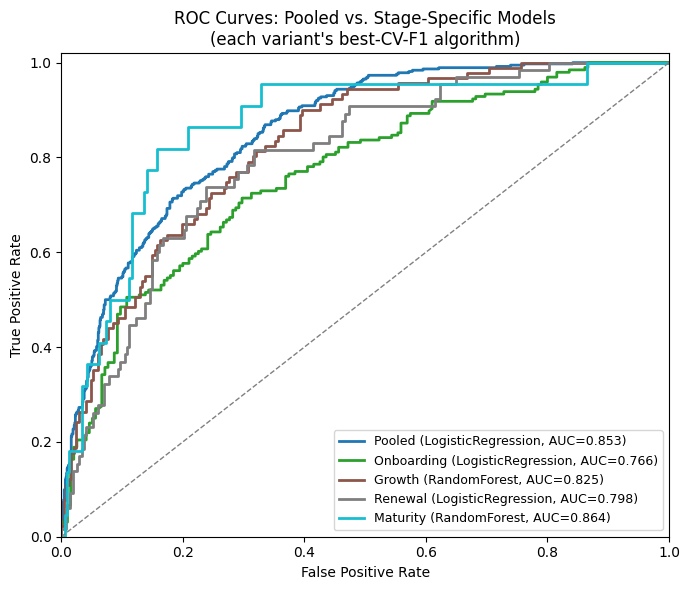

Saved: roc_curves_pooled_vs_stages.png


In [15]:
# --- Visualization 1: ROC curves for each variant's best model, overlaid ---
from sklearn.metrics import roc_curve

fig, ax = plt.subplots(figsize=(7, 6))
colors = plt.cm.tab10(np.linspace(0, 1, len(VARIANTS)))

for variant, color in zip(VARIANTS, colors):
    _, _, Xte, yte = variant_data(variant)
    algo = best_per_variant.loc[variant, 'Algorithm']
    gs = fitted_models[(variant, algo)]
    y_score = get_scores(gs.best_estimator_, Xte)
    fpr, tpr, _ = roc_curve(yte, y_score)
    auc = best_per_variant.loc[variant, 'Test_ROC_AUC']
    ax.plot(fpr, tpr, color=color, lw=2, label=f"{variant} ({algo}, AUC={auc:.3f})")

ax.plot([0, 1], [0, 1], linestyle='--', color='gray', lw=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title("ROC Curves: Pooled vs. Stage-Specific Models\n(each variant's best-CV-F1 algorithm)")
ax.legend(loc='lower right', fontsize=9)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.savefig('roc_curves_pooled_vs_stages.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: roc_curves_pooled_vs_stages.png")


## Stage 4 - Explainable AI Integration

### 4a. SHAP - global, stage-level feature attribution

For each stage's best model, estimates which behavioral factors contribute most to churn
risk within that stage. Uses `TreeExplainer`/`LinearExplainer`/`KernelExplainer` as
appropriate when `shap` is installed; otherwise falls back to permutation importance on
the fitted pipeline.

In [16]:
# --- 5.1.4 Stage 4a: SHAP -- global, stage-level feature attribution for each stage's best model ---

def get_feature_names(preprocessor):
    return preprocessor.get_feature_names_out()

def _positive_class_shap(sv):
    """Normalize shap_values() output to a 2D (n_samples, n_features) array for the
    positive class. Different shap versions return this differently for classifiers:
    a list of per-class arrays (older versions), or a single 3D array shaped
    (n_samples, n_features, n_classes) (newer versions) -- both are handled here."""
    if isinstance(sv, list):
        return sv[1] if len(sv) > 1 else sv[0]
    sv = np.asarray(sv)
    if sv.ndim == 3:
        return sv[:, :, 1] if sv.shape[-1] > 1 else sv[:, :, 0]
    return sv

def global_importance(gs, X, y, sample_size=300):
    """Returns a Series of feature_name -> importance, sorted descending.
    Uses SHAP if installed (TreeExplainer for tree models, LinearExplainer for
    linear models, KernelExplainer otherwise); falls back to permutation importance
    computed directly on the model's own transformed feature space."""
    pipe = gs.best_estimator_
    prep, clf = pipe.named_steps['prep'], pipe.named_steps['clf']
    feat_names = get_feature_names(prep)
    Xs = X.sample(min(sample_size, len(X)), random_state=RANDOM_STATE)
    Xt = prep.transform(Xs)
    Xt_dense = Xt.toarray() if hasattr(Xt, 'toarray') else Xt

    if HAS_SHAP:
        try:
            if isinstance(clf, (RandomForestClassifier, GradientBoostingClassifier)) or \
               (HAS_XGB and isinstance(clf, XGBClassifier)):
                explainer = shap.TreeExplainer(clf)
                sv = _positive_class_shap(explainer.shap_values(Xt_dense))
            elif isinstance(clf, LogisticRegression):
                explainer = shap.LinearExplainer(clf, Xt_dense)
                sv = _positive_class_shap(explainer.shap_values(Xt_dense))
            else:
                background = shap.sample(Xt_dense, min(50, Xt_dense.shape[0]))
                explainer = shap.KernelExplainer(safe_predict_proba_fn(clf), background)
                sv = _positive_class_shap(explainer.shap_values(Xt_dense, nsamples=100))
            importance = np.abs(sv).mean(axis=0)
            return pd.Series(importance, index=feat_names).sort_values(ascending=False)
        except Exception as e:
            print(f"  SHAP failed ({e}); falling back to permutation importance")

    # --- fallback: permutation importance on the fitted pipeline ---
    pi = permutation_importance(pipe, Xs, y.loc[Xs.index], scoring='f1', n_repeats=10,
                                 random_state=RANDOM_STATE, n_jobs=1)
    return pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)
    # NOTE: this fallback importance is on the *raw* predictor columns (pre-encoding),
    # not the one-hot-expanded columns SHAP would use -- keep that in mind when
    # comparing rank tables against a real SHAP run.

shap_importance = {}
for stage in VARIANTS:
    Xtr, ytr, Xte, yte = variant_data(stage)
    gs = fitted_models[(stage, best_per_variant.loc[stage, 'Algorithm'])]
    shap_importance[stage] = global_importance(gs, Xtr, ytr)
    print(f"\n=== {stage}: top 8 global drivers ===")
    print(shap_importance[stage].head(8).round(4))



=== Pooled: top 8 global drivers ===
num__Tenure                          0.6900
num__Monthly Charges                 0.6816
num__Avg Monthly Spend               0.6509
cat__Dependents_Yes                  0.4335
cat__Contract_Month-to-month         0.3572
num__Expansion Revenue Ratio         0.2645
cat__Internet Service_Fiber optic    0.2553
num__Total Charges                   0.2253
dtype: float64

=== Onboarding: top 8 global drivers ===
num__Monthly Charges                 0.4922
num__Tenure                          0.4803
num__Expansion Revenue Ratio         0.2263
num__Total Charges                   0.2039
cat__Paperless Billing_Yes           0.2007
cat__Multiple Lines_Yes              0.1596
cat__Internet Service_No             0.1509
cat__Internet Service_Fiber optic    0.1405
dtype: float64



=== Growth: top 8 global drivers ===
cat__Internet Service_Fiber optic       0.0523
cat__Contract_Month-to-month            0.0445
num__Monthly Charges                    0.0437
cat__Dependents_Yes                     0.0336
num__Avg Monthly Spend                  0.0294
num__Total Charges                      0.0248
cat__Paperless Billing_Yes              0.0210
cat__Payment Method_Electronic check    0.0204
dtype: float64

=== Renewal: top 8 global drivers ===
cat__Dependents_Yes             0.5934
cat__Contract_Month-to-month    0.3591
cat__Contract_Two year          0.2369
num__Total Charges              0.2136
num__Expansion Revenue Ratio    0.1865
cat__Online Security_Yes        0.1830
num__Avg Monthly Spend          0.1608
cat__Partner_Yes                0.1550
dtype: float64

=== Maturity: top 8 global drivers ===
cat__Dependents_Yes                  0.0846
num__Monthly Charges                 0.0430
cat__Contract_Two year               0.0418
cat__Internet Service_Fiber optic

### 4b. LIME - local, per-customer feature attribution

Explains a sample of individual customers per stage and averages the (absolute) local
weights, giving a second, complementary ranking of drivers per stage.

In [17]:
# --- 5.1.4 Stage 4b: LIME -- local, per-customer feature attribution, averaged per stage ---

def _lime_fallback_local_importance(pipe, x_row_transformed, predict_fn, n_samples=300, kernel_width=0.75):
    """Minimal from-scratch local-surrogate explainer (used only when `lime` isn't installed):
    perturbs the instance with Gaussian noise in the transformed feature space, weights
    perturbations by an RBF proximity kernel, and fits a weighted Ridge regression to the
    model's predicted probability. |coefficients| approximate LIME's local feature weights."""
    from sklearn.linear_model import Ridge
    rng = np.random.RandomState(RANDOM_STATE)
    n_feat = x_row_transformed.shape[0]
    noise = rng.normal(0, 0.5, size=(n_samples, n_feat))
    perturbed = x_row_transformed + noise
    dists = np.linalg.norm(noise, axis=1)
    weights = np.exp(-(dists ** 2) / (2 * kernel_width ** 2))
    probs = predict_fn(perturbed)
    surrogate = Ridge(alpha=1.0)
    surrogate.fit(perturbed, probs, sample_weight=weights)
    return np.abs(surrogate.coef_)

# Customers explained by LIME per model. The defaults reproduce the numbers reported so far; raise both
# (e.g. to 100) for final results, then re-run this cell and every cell after it (runtime grows in proportion).
N_LIME_STAGE = 25      # Stages 4b and 4d: one best model per stage
N_LIME_ALGO = 15       # Stage 4d-2: all five algorithms in every stage

def local_importance_for_stage(gs, X, feat_names, n_customers=N_LIME_STAGE):
    pipe = gs.best_estimator_
    prep, clf = pipe.named_steps['prep'], pipe.named_steps['clf']
    sample = X.sample(min(n_customers, len(X)), random_state=RANDOM_STATE)
    Xt = prep.transform(sample)
    Xt_dense = Xt.toarray() if hasattr(Xt, 'toarray') else Xt

    if HAS_LIME:
        explainer = LimeTabularExplainer(Xt_dense, feature_names=list(feat_names),
                                          class_names=['No Churn', 'Churn'], mode='classification',
                                          discretize_continuous=False, random_state=RANDOM_STATE)
        lime_predict_fn = safe_predict_proba_fn(clf)
        weights = []
        for i in range(Xt_dense.shape[0]):
            exp = explainer.explain_instance(Xt_dense[i], lime_predict_fn, num_features=len(feat_names))
            w = dict(exp.as_list())
            weights.append([abs(w.get(f, 0.0)) for f in feat_names])
        return pd.Series(np.mean(weights, axis=0), index=feat_names).sort_values(ascending=False)

    # --- fallback: custom local-surrogate approximation ---
    def predict_fn(Z):
        return clf.predict_proba(Z)[:, 1] if hasattr(clf, 'predict_proba') else clf.decision_function(Z)
    weights = [ _lime_fallback_local_importance(pipe, Xt_dense[i], predict_fn) for i in range(Xt_dense.shape[0]) ]
    return pd.Series(np.mean(weights, axis=0), index=feat_names).sort_values(ascending=False)

lime_importance = {}
for stage in VARIANTS:
    Xtr, ytr, Xte, yte = variant_data(stage)
    gs = fitted_models[(stage, best_per_variant.loc[stage, 'Algorithm'])]
    feat_names = get_feature_names(gs.best_estimator_.named_steps['prep'])
    lime_importance[stage] = local_importance_for_stage(gs, Xtr, feat_names)
    print(f"\n=== {stage}: top 8 local drivers (avg over sampled customers) ===")
    print(lime_importance[stage].head(8).round(4))



=== Pooled: top 8 local drivers (avg over sampled customers) ===
num__Monthly Charges                 0.1324
num__Avg Monthly Spend               0.1195
num__Tenure                          0.1179
cat__Dependents_Yes                  0.0832
cat__Contract_Month-to-month         0.0645
num__Expansion Revenue Ratio         0.0530
num__Total Charges                   0.0460
cat__Internet Service_Fiber optic    0.0453
dtype: float64

=== Onboarding: top 8 local drivers (avg over sampled customers) ===
num__Tenure                     0.1086
num__Monthly Charges            0.1071
num__Expansion Revenue Ratio    0.0448
cat__Multiple Lines_Yes         0.0442
cat__Paperless Billing_Yes      0.0423
cat__Dependents_Yes             0.0417
cat__Internet Service_No        0.0329
num__Total Charges              0.0310
dtype: float64

=== Growth: top 8 local drivers (avg over sampled customers) ===
cat__Contract_Month-to-month            0.0429
num__Monthly Charges                    0.0292
cat__Inter

### 4c. Do SHAP and LIME agree? (Spearman rank correlation, RQ5)

Collapses both rankings back onto the original (pre-one-hot-encoding) feature names so
they're comparable, then computes Spearman's rho per stage between the SHAP-based global
ranking and the LIME-based local ranking.

In [18]:
# --- Align SHAP/global and LIME/local rankings onto the same (raw, pre-encoding) feature
# space so they can be fairly compared. One-hot columns collapse back to their parent
# feature by summing importance across levels; numeric columns pass through unchanged. ---

def collapse_to_raw(importance_series):
    raw = {}
    for name, val in importance_series.items():
        if name.startswith('num__'):
            key = name[len('num__'):]
        elif name.startswith('cat__'):
            # cat__<Original Column>_<level>  ->  <Original Column>
            rest = name[len('cat__'):]
            key = next((c for c in CATEGORICAL_COLS if rest.startswith(c)), rest)
        else:
            key = name  # already raw (permutation-importance fallback case)
        raw[key] = raw.get(key, 0.0) + val
    return pd.Series(raw).sort_values(ascending=False)

spearman_rows = []
for stage in VARIANTS:
    g = collapse_to_raw(shap_importance[stage])
    l = collapse_to_raw(lime_importance[stage])
    common = sorted(set(g.index) & set(l.index))
    rho, p = stats.spearmanr(g[common], l[common])
    spearman_rows.append({'Stage': stage, 'n_features_compared': len(common), 'Spearman_rho': rho, 'p_value': p})
    print(f"{stage:>10}: Spearman rho (SHAP-global vs LIME-local ranking) = {rho:.3f}  (p={p:.4f}, n={len(common)})")

spearman_df = pd.DataFrame(spearman_rows)
print("\nHigher rho = SHAP's stage-level ranking and LIME's averaged local ranking agree more; "
      "this is the empirical check behind RQ5 (does combining SHAP+LIME add anything beyond either alone).")
spearman_df


    Pooled: Spearman rho (SHAP-global vs LIME-local ranking) = 0.993  (p=0.0000, n=23)
Onboarding: Spearman rho (SHAP-global vs LIME-local ranking) = 0.912  (p=0.0000, n=23)
    Growth: Spearman rho (SHAP-global vs LIME-local ranking) = 0.831  (p=0.0000, n=23)
   Renewal: Spearman rho (SHAP-global vs LIME-local ranking) = 0.984  (p=0.0000, n=23)
  Maturity: Spearman rho (SHAP-global vs LIME-local ranking) = 0.899  (p=0.0000, n=23)

Higher rho = SHAP's stage-level ranking and LIME's averaged local ranking agree more; this is the empirical check behind RQ5 (does combining SHAP+LIME add anything beyond either alone).


,Stage,n_features_compared,Spearman_rho,p_value
0,Pooled,23,0.993083,5.041545e-21
1,Onboarding,23,0.912055,1.386282e-09
2,Growth,23,0.831028,9.084332e-07
3,Renewal,23,0.984190,2.854051e-17
4,Maturity,23,0.899209,5.474601e-09


### 4d. Do drivers differ significantly across lifecycle stages? (Kruskal-Wallis, RQ2)

For each feature shared by all four stage models, tests whether the *distribution* of its
local (LIME) importance across sampled customers differs significantly between the four
lifecycle stages. Uses each stage's single *best* algorithm and applies Benjamini-Hochberg
correction for the 25-feature multiple-comparisons problem (25 simultaneous tests inflate
the false-positive rate if left uncorrected).

In [19]:
# --- Kruskal-Wallis: for each feature common to all four stage models, does the *distribution*
# of local (LIME) importance across sampled customers differ significantly by stage? ---

def local_importance_distribution(gs, X, feat_names, n_customers=N_LIME_STAGE):
    """Same as local_importance_for_stage but returns the raw per-customer matrix
    (not just the mean) so we can test distributions, not just averages."""
    pipe = gs.best_estimator_
    prep, clf = pipe.named_steps['prep'], pipe.named_steps['clf']
    sample = X.sample(min(n_customers, len(X)), random_state=RANDOM_STATE)
    Xt = prep.transform(sample)
    Xt_dense = Xt.toarray() if hasattr(Xt, 'toarray') else Xt

    if HAS_LIME:
        explainer = LimeTabularExplainer(Xt_dense, feature_names=list(feat_names),
                                          class_names=['No Churn', 'Churn'], mode='classification',
                                          discretize_continuous=False, random_state=RANDOM_STATE)
        lime_predict_fn = safe_predict_proba_fn(clf)
        rows = []
        for i in range(Xt_dense.shape[0]):
            exp = explainer.explain_instance(Xt_dense[i], lime_predict_fn, num_features=len(feat_names))
            w = dict(exp.as_list())
            rows.append([abs(w.get(f, 0.0)) for f in feat_names])
        return pd.DataFrame(rows, columns=feat_names)

    def predict_fn(Z):
        return clf.predict_proba(Z)[:, 1] if hasattr(clf, 'predict_proba') else clf.decision_function(Z)
    rows = [_lime_fallback_local_importance(pipe, Xt_dense[i], predict_fn) for i in range(Xt_dense.shape[0])]
    return pd.DataFrame(rows, columns=feat_names)

per_customer_local = {}
for stage in VARIANTS:
    Xtr, ytr, Xte, yte = variant_data(stage)
    gs = fitted_models[(stage, best_per_variant.loc[stage, 'Algorithm'])]
    feat_names = get_feature_names(gs.best_estimator_.named_steps['prep'])
    per_customer_local[stage] = local_importance_distribution(gs, Xtr, feat_names)

# Collapse each stage's per-customer matrix onto raw feature names, then test the four
# lifecycle stages (excluding Pooled) against each other feature-by-feature.
def collapse_matrix(df):
    out = {}
    for col in df.columns:
        if col.startswith('num__'):
            key = col[len('num__'):]
        elif col.startswith('cat__'):
            rest = col[len('cat__'):]
            key = next((c for c in CATEGORICAL_COLS if rest.startswith(c)), rest)
        else:
            key = col
        out[key] = out.get(key, 0) + df[col]
    return pd.DataFrame(out)

collapsed = {s: collapse_matrix(per_customer_local[s]) for s in ['Onboarding', 'Growth', 'Renewal', 'Maturity']}
shared_features = set.intersection(*[set(c.columns) for c in collapsed.values()])

kw_rows = []
for feat in sorted(shared_features):
    groups = [collapsed[s][feat].values for s in ['Onboarding', 'Growth', 'Renewal', 'Maturity']]
    try:
        stat, p = stats.kruskal(*groups)
        kw_rows.append({'Feature': feat, 'H_statistic': stat, 'p_value': p})
    except ValueError:
        pass  # all-identical values (e.g. a feature LIME never touches) -> skip

kruskal_df = pd.DataFrame(kw_rows).sort_values('p_value')

# Benjamini-Hochberg correction: we're testing 25 features at once, so raw p<0.05 alone
# overstates how many "significant" results to expect by chance (see the algorithm-level
# robustness check below for a second, independent way to guard against this).
def benjamini_hochberg(pvals):
    pvals = np.asarray(pvals)
    n = len(pvals)
    order = np.argsort(pvals)
    ranked = pvals[order]
    adjusted = np.minimum.accumulate((ranked * n / (np.arange(n) + 1))[::-1])[::-1]
    out = np.empty(n)
    out[order] = np.clip(adjusted, 0, 1)
    return out

kruskal_df['q_value'] = benjamini_hochberg(kruskal_df['p_value'].values)
print("Kruskal-Wallis test: does local importance for this feature differ across lifecycle stages?\n")
print(kruskal_df.to_string(index=False))
print(f"\nRaw p<0.05: {(kruskal_df['p_value'] < 0.05).sum()} of {len(kruskal_df)} features.  "
      f"BH-adjusted q<0.05: {(kruskal_df['q_value'] < 0.05).sum()} of {len(kruskal_df)} features. "
      "The correction matters here -- see the algorithm-level version below for a more robust check.")


Kruskal-Wallis test: does local importance for this feature differ across lifecycle stages?

                Feature  H_statistic      p_value      q_value
             Dependents    92.821782 5.424710e-20 2.253887e-19
               Contract    92.821782 5.424710e-20 2.253887e-19
      Paperless Billing    92.821782 5.424710e-20 2.253887e-19
       Streaming Movies    92.585679 6.096831e-20 2.253887e-19
         Payment Method    92.468768 6.459850e-20 2.253887e-19
       Internet Service    92.237228 7.243823e-20 2.253887e-19
Expansion Revenue Ratio    92.237228 7.243823e-20 2.253887e-19
           Streaming TV    91.952079 8.341206e-20 2.253887e-19
                 Tenure    91.839350 8.819558e-20 2.253887e-19
        Online Security    89.793125 2.426558e-19 5.128382e-19
     Num Addon Services    89.771453 2.452704e-19 5.128382e-19
          Phone Service    88.202947 5.327185e-19 1.021044e-18
         Senior Citizen    87.475818 7.631921e-19 1.350263e-18
          Total Charges  

### 4d-2. Robustness check: does the answer hold across all 5 algorithms? (Section 4.1 / Salih et al., 2024)

SHAP/LIME rankings are known to be algorithm-dependent. The cell above only used each
stage's single best-performing algorithm, so a "significant" driver could really just be
an artifact of *that one algorithm's* local-surrogate behavior. This cell repeats the same
Kruskal-Wallis test independently for **all 5 algorithms**, BH-corrects each algorithm's
own family of 25 tests, and reports which features survive correction in *every* algorithm
-- that's the more defensible claim for RQ2, since it isn't tied to one model's quirks.

In [20]:
# --- Improvement 2: extend SHAP/LIME + Kruskal-Wallis across ALL 5 algorithms per stage
# (not just each stage's single best model), with Benjamini-Hochberg correction for the
# 25-feature multiple-comparisons problem. Addresses Section 4.1's point (citing Salih et
# al., 2024) that SHAP/LIME rankings are algorithm-dependent. ---

def benjamini_hochberg(pvals):
    """Returns BH-adjusted p-values (q-values), same order as input."""
    pvals = np.asarray(pvals)
    n = len(pvals)
    order = np.argsort(pvals)
    ranked = pvals[order]
    adjusted = ranked * n / (np.arange(n) + 1)
    # enforce monotonicity (running minimum from the largest p-value down)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0, 1)
    out = np.empty(n)
    out[order] = adjusted
    return out

STAGES = ['Onboarding', 'Growth', 'Renewal', 'Maturity']
ALGOS = list(build_model_grid().keys())

# Per-customer local (LIME/fallback) importance for every (stage, algorithm) combination
per_customer_local_all = {}
for stage in STAGES:
    Xtr, ytr, _, _ = variant_data(stage)
    for algo in ALGOS:
        gs = fitted_models[(stage, algo)]
        feat_names = get_feature_names(gs.best_estimator_.named_steps['prep'])
        per_customer_local_all[(stage, algo)] = collapse_matrix(
            local_importance_distribution(gs, Xtr, feat_names, n_customers=N_LIME_ALGO))
    print(f"local-surrogate importances computed for all algorithms, stage={stage}")

# Kruskal-Wallis per feature, run independently for each algorithm
shared_features_all = set.intersection(
    *[set(per_customer_local_all[(s, a)].columns) for s in STAGES for a in ALGOS])

kw_by_algo_rows = []
for algo in ALGOS:
    for feat in sorted(shared_features_all):
        groups = [per_customer_local_all[(s, algo)][feat].values for s in STAGES]
        try:
            stat, p = stats.kruskal(*groups)
            kw_by_algo_rows.append({'Algorithm': algo, 'Feature': feat, 'H_statistic': stat, 'p_value': p})
        except ValueError:
            pass

kw_by_algo_df = pd.DataFrame(kw_by_algo_rows)
# BH correction applied within each algorithm's 25-feature family of tests
kw_by_algo_df['q_value'] = kw_by_algo_df.groupby('Algorithm')['p_value'].transform(
    lambda p: benjamini_hochberg(p.values))
kw_by_algo_df['significant_q05'] = kw_by_algo_df['q_value'] < 0.05

print("\nSignificant features (BH q<0.05) by algorithm:")
sig_counts = kw_by_algo_df.groupby('Algorithm')['significant_q05'].sum()
print(sig_counts)

# Robustness: how many of the 5 algorithms agree a given feature's importance differs by stage?
robustness = (kw_by_algo_df.groupby('Feature')['significant_q05'].sum()
              .sort_values(ascending=False).rename('n_algorithms_significant'))
print(f"\nFeatures significant (q<0.05) in all {len(ALGOS)} algorithms (most robust evidence "
      f"for RQ2 -- drivers genuinely shift across lifecycle stages, not just an artifact of "
      f"one algorithm's local-surrogate quirks):")
print(robustness[robustness == len(ALGOS)])
print("\nFull robustness table (features sorted by how many algorithms agree):")
robustness


local-surrogate importances computed for all algorithms, stage=Onboarding
local-surrogate importances computed for all algorithms, stage=Growth
local-surrogate importances computed for all algorithms, stage=Renewal
local-surrogate importances computed for all algorithms, stage=Maturity

Significant features (BH q<0.05) by algorithm:
Algorithm
LogisticRegression    23
MLP                   23
RandomForest          21
SVM                   23
XGBoost               20
Name: significant_q05, dtype: int64

Features significant (q<0.05) in all 5 algorithms (most robust evidence for RQ2 -- drivers genuinely shift across lifecycle stages, not just an artifact of one algorithm's local-surrogate quirks):
Feature
Avg Monthly Spend          5
Charges Per Service        5
Contract                   5
Dependents                 5
Expansion Revenue Ratio    5
Gender                     5
Internet Service           5
Tech Support               5
Monthly Charges            5
Num Addon Services         

,n_algorithms_significant
Feature,
Avg Monthly Spend,5
Charges Per Service,5
Contract,5
Dependents,5
Expansion Revenue Ratio,5
Gender,5
Internet Service,5
Tech Support,5
Monthly Charges,5


### Driver-importance heatmap across stages

A visual companion to the Kruskal-Wallis tests above: each feature's SHAP importance by
stage, normalized 0-1 within each stage's column so stages with naturally different SHAP
scales (driven by which algorithm won that stage) are still visually comparable.
Features that stay dark across all four columns are stage-invariant; features that light
up in only one or two columns are the stage-specific drivers RQ2 is asking about.

Read `Monthly Charges` and `Internet Service` jointly here, per the Stage 2 feature-audit
note above - they represent one underlying "plan tier/services" signal split across two
columns, not two independently-confirmed drivers.

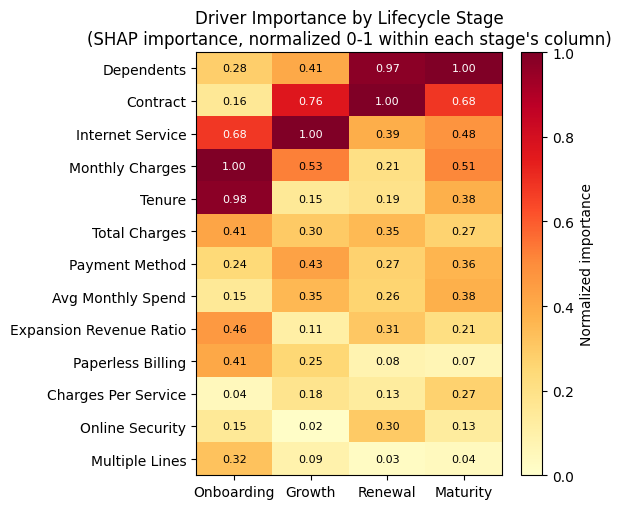

Saved: driver_heatmap_by_stage.png


In [21]:
# --- Visualization 2: driver-importance landscape across all four lifecycle stages ---
# A heatmap of each feature's SHAP importance by stage makes the "do drivers shift
# across the lifecycle" question (RQ2) visually immediate in a way the printed tables
# don't -- features that stay dark across all four columns are stage-invariant,
# features that light up in only one column are stage-specific.

all_features = sorted(set().union(*[collapse_to_raw(shap_importance[s]).index for s in
                                     ['Onboarding', 'Growth', 'Renewal', 'Maturity']]))
heatmap_data = pd.DataFrame(index=all_features, columns=['Onboarding', 'Growth', 'Renewal', 'Maturity'], dtype=float)
for stage in ['Onboarding', 'Growth', 'Renewal', 'Maturity']:
    ranked = collapse_to_raw(shap_importance[stage])
    for feat in all_features:
        heatmap_data.loc[feat, stage] = ranked.get(feat, 0.0)

# Clip at 0: real SHAP importance is always >=0 (it's a mean of absolute values), but the
# permutation-importance fallback used when shap isn't installed can go slightly negative
# (shuffling a near-irrelevant feature can improve the score by chance) -- clipping keeps
# the heatmap's color scale meaningful either way, since a negative permutation score
# just means "no importance", not "negative importance".
heatmap_data = heatmap_data.clip(lower=0)

# Normalize each stage's column to 0-1 so stages with naturally larger/smaller SHAP
# scales (e.g. driven by algorithm choice) are visually comparable side by side
heatmap_norm = heatmap_data / heatmap_data.max()
# Keep only features that crack the top 8 in at least one stage, sorted by total signal
top_features = heatmap_data.loc[heatmap_data.apply(lambda col: col.rank(ascending=False) <= 8).any(axis=1)]
top_features = top_features.loc[heatmap_norm.loc[top_features.index].sum(axis=1).sort_values(ascending=False).index]
plot_data = heatmap_norm.loc[top_features.index]

fig, ax = plt.subplots(figsize=(6, max(4, 0.4 * len(plot_data))))
im = ax.imshow(plot_data.values, aspect='auto', cmap='YlOrRd', vmin=0, vmax=1)
ax.set_xticks(range(4))
ax.set_xticklabels(plot_data.columns)
ax.set_yticks(range(len(plot_data)))
ax.set_yticklabels(plot_data.index)
for i in range(plot_data.shape[0]):
    for j in range(plot_data.shape[1]):
        val = plot_data.values[i, j]
        ax.text(j, i, f"{val:.2f}", ha='center', va='center',
                color='white' if val > 0.6 else 'black', fontsize=8)
ax.set_title("Driver Importance by Lifecycle Stage\n(SHAP importance, normalized 0-1 within each stage's column)")
fig.colorbar(im, ax=ax, label='Normalized importance')
plt.tight_layout()
plt.savefig('driver_heatmap_by_stage.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: driver_heatmap_by_stage.png")


### 4d-3. Rank-shift analysis: how do the driver rankings move across the lifecycle? (RQ3)

**Status: exploratory and provisional.** The LIME-based comparisons here (items 4 and 5) rest on 15 customers per stage and algorithm, and the bootstrap noise reference in Stage 4d-5 has not yet been applied to the final settings. Treat every conclusion from this cell as provisional and do not quote its figures in the thesis until Stage 4d-5 has been run.

The Kruskal-Wallis tests above ask whether a feature's importance *values* differ by stage, and the heatmap
shows the rankings side by side. This cell measures the **rank movement itself**, which is the more direct
answer to "do the drivers change as customers progress?". It reports:

1. a **feature x stage rank matrix** (SHAP, each stage's best model);
2. **rank change between adjacent stages** (Onboarding->Growth->Renewal->Maturity) and **from the pooled model to each stage**, with the biggest risers and fallers;
3. **Kendall's W** across the four stage rankings, an overall agreement statistic (W near 1 = the same drivers lead at every stage; W near 1/m = the rankings are being reshuffled);
4. **rank stability across algorithms**, and a check with the **algorithm held fixed** so that a stage effect is not confused with a change of algorithm;
5. a per-feature **stage-signal vs. algorithm-noise** ratio, and a **bump chart** of the leading drivers.

**Why ranks rather than magnitudes.** Different algorithms won different stages, so raw SHAP values sit on
different numeric scales (Growth's largest value is roughly a tenth of Onboarding's). Ranks are scale-free
and are the fair basis for comparing stages.

**Three caveats to keep in the write-up.**
- SHAP was computed only for each stage's *best* model, and that model differs by stage, so part of any cross-stage rank shift can be an algorithm switch. Items 4 and 5 above use LIME, which was run for **all five algorithms** in every stage, to separate the two.
- Importance is summed across a categorical feature's one-hot levels, which can favour multi-level features (Contract, Internet Service, Payment Method) over single-column ones.
- **Multiplicity and noise.** Only Kendall's W is an inferential test here (a single omnibus test, so no multiplicity correction is needed). The rank changes for individual features (23 features x 3 transitions), the 'biggest movers' and the signal/noise ratios are descriptive. Rankings are noisy estimates with no null reference in this cell: the largest of 23 rank changes is expected to look large by chance alone, and about half of the ratios would exceed 1 with no stage effect at all. The BH-corrected Kruskal-Wallis tests (Stages 4d, 4d-2) remain the inferential evidence.
- LIME ranks in items 4 and 5 rest on only 15 customers per stage and algorithm; increase `n_customers` for final results.
- The p-value on Kendall's W tests the null hypothesis of *no* agreement. A significant W means the rankings share structure, not that they are identical, so interpret the size of W, not only its significance.

Feature x stage SHAP rank matrix (23 features; 1 = most important):

                         Pooled  Onboarding  Growth  Renewal  Maturity  Mean stage rank  Rank range (max-min)
Internet Service            5.0         3.0     1.0      3.0       4.0              2.8                   3.0
Dependents                  6.0         8.0     5.0      2.0       1.0              4.0                   7.0
Contract                    4.0        12.0     2.0      1.0       2.0              4.2                  11.0
Monthly Charges             2.0         1.0     3.0     11.0       3.0              4.5                  10.0
Total Charges               9.0         5.0     7.0      4.0       9.0              6.2                   5.0
Payment Method              8.0         9.0     4.0      7.0       7.0              6.8                   5.0
Tenure                      1.0         2.0    10.0     12.0       6.0              7.5                  10.0
Expansion Revenue Ratio     7.0         4.0    11.0

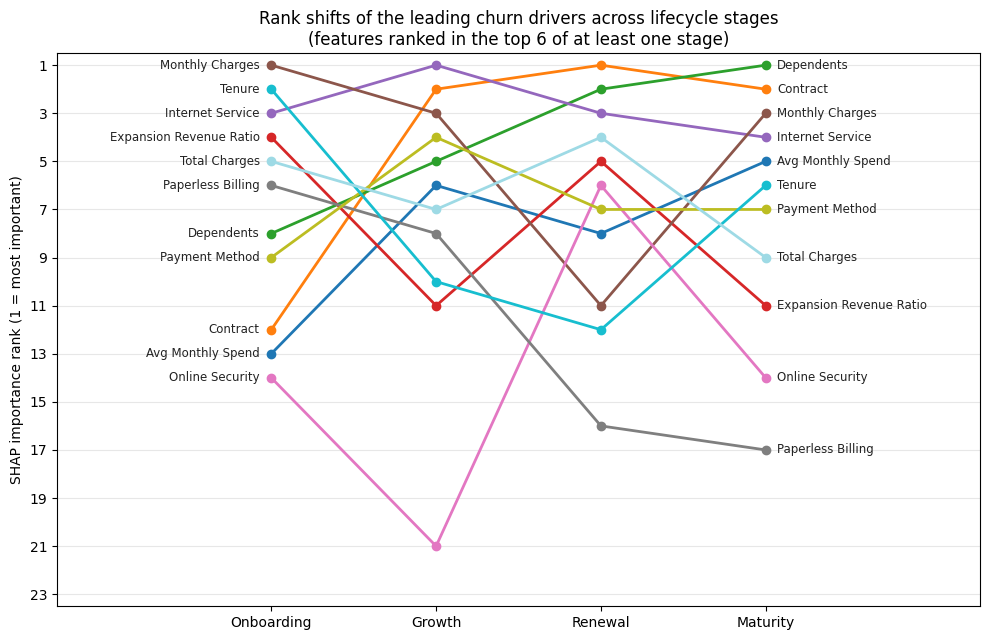

Saved: rank_shift_bump_chart.png


,Pooled,Onboarding,Growth,Renewal,Maturity,Mean stage rank,Rank range (max-min)
Internet Service,5.0,3.0,1.0,3.0,4.0,2.8,3.0
Dependents,6.0,8.0,5.0,2.0,1.0,4.0,7.0
Contract,4.0,12.0,2.0,1.0,2.0,4.2,11.0
Monthly Charges,2.0,1.0,3.0,11.0,3.0,4.5,10.0
Total Charges,9.0,5.0,7.0,4.0,9.0,6.2,5.0
Payment Method,8.0,9.0,4.0,7.0,7.0,6.8,5.0
Tenure,1.0,2.0,10.0,12.0,6.0,7.5,10.0
Expansion Revenue Ratio,7.0,4.0,11.0,5.0,11.0,7.8,7.0
Avg Monthly Spend,3.0,13.0,6.0,8.0,5.0,8.0,8.0
Streaming Movies,11.0,10.0,12.0,10.0,10.0,10.5,2.0


In [22]:
# --- 4d-3. Rank-shift analysis: how do driver RANKINGS move across the lifecycle? ---
# SHAP magnitudes are not comparable across stages (different algorithms won different
# stages, so the numeric scale differs), but ranks are scale-free. Everything below is
# therefore built on ranks (1 = most important feature within that stage/model).
from scipy.stats import rankdata, spearmanr, chi2

STAGES4 = ['Onboarding', 'Growth', 'Renewal', 'Maturity']

def rank_series(imp):
    """Rank 1 = most important; tied values share the average rank."""
    return pd.Series(rankdata(-np.asarray(imp, dtype=float), method='average'), index=imp.index)

def kendalls_w(rank_df):
    """Kendall's coefficient of concordance (tie-corrected).
    rank_df: rows = features (items being ranked), columns = raters (stages or algorithms).
    W = 1 -> every rater ranks the features identically; W ~ 1/m -> no more agreement than
    chance (m = number of raters). Returns (W, chi-square statistic, p-value); the p-value
    tests the null hypothesis of NO agreement, so a significant W means the rankings share
    structure, not that they are identical."""
    n, m = rank_df.shape
    R = rank_df.sum(axis=1)
    S = ((R - R.mean()) ** 2).sum()
    T = 0.0
    for col in rank_df.columns:
        _, counts = np.unique(rank_df[col].values, return_counts=True)
        T += ((counts ** 3) - counts).sum()
    denom = (m ** 2) * (n ** 3 - n) - m * T
    W = 12 * S / denom if denom > 0 else np.nan
    chi_stat = m * (n - 1) * W
    return W, chi_stat, chi2.sf(chi_stat, df=n - 1)

# ---------------------------------------------------------------------------------------
# 1. Feature x stage rank matrix (SHAP, each stage's best model)
# ---------------------------------------------------------------------------------------
shap_raw = {s: collapse_to_raw(shap_importance[s]) for s in ['Pooled'] + STAGES4}
common = sorted(set.intersection(*[set(v.index) for v in shap_raw.values()]))
shap_rank = pd.DataFrame({s: rank_series(shap_raw[s].loc[common]) for s in ['Pooled'] + STAGES4})

rank_matrix = shap_rank.copy()
rank_matrix['Mean stage rank'] = rank_matrix[STAGES4].mean(axis=1)
rank_matrix['Rank range (max-min)'] = rank_matrix[STAGES4].max(axis=1) - rank_matrix[STAGES4].min(axis=1)
rank_matrix = rank_matrix.sort_values('Mean stage rank')
print(f"Feature x stage SHAP rank matrix ({len(common)} features; 1 = most important):\n")
print(rank_matrix.round(1).to_string())

# ---------------------------------------------------------------------------------------
# 2. Rank change between adjacent stages, and from the pooled model to each stage
# ---------------------------------------------------------------------------------------
# Sign convention: positive = the feature became MORE important (its rank number fell).
transitions = [('Onboarding', 'Growth'), ('Growth', 'Renewal'), ('Renewal', 'Maturity')] + \
              [('Pooled', s) for s in STAGES4]
shift_df = pd.DataFrame({f'{a} -> {b}': shap_rank[a] - shap_rank[b] for a, b in transitions})

summary_rows = []
for a, b in transitions:
    d = shap_rank[a] - shap_rank[b]
    rho, p = spearmanr(shap_rank[a], shap_rank[b])
    summary_rows.append({
        'Transition': f'{a} -> {b}',
        'Mean |rank change|': d.abs().mean(),
        'Max |rank change|': d.abs().max(),
        'Features moving >=5 places': int((d.abs() >= 5).sum()),
        'Spearman rho between the two rankings': rho,
        'p-value': p,
    })
transition_summary = pd.DataFrame(summary_rows)
print("\n\nRank change summary (positive change = feature gained importance):\n")
print(transition_summary.round(3).to_string(index=False))

print("\nBiggest movers at each adjacent-stage transition:")
for a, b in transitions[:3]:
    d = (shap_rank[a] - shap_rank[b]).sort_values()
    risers = ', '.join(f"{f} (+{v:.0f})" for f, v in d[::-1].head(3).items())
    fallers = ', '.join(f"{f} ({v:.0f})" for f, v in d.head(3).items())
    print(f"  {a} -> {b}:  gained: {risers}   |   lost: {fallers}")
print("  Caution: the largest movers among 23 features are extreme values by construction. Rankings are "
      "noisy estimates, so movements of this size can arise with no true stage effect; treat these lists "
      "as descriptive and exploratory (no multiplicity control is applied to them).")

# ---------------------------------------------------------------------------------------
# 3. Overall agreement across the four stage rankings (Kendall's W)
# ---------------------------------------------------------------------------------------
m = len(STAGES4)
W_shap, chi_shap, p_shap = kendalls_w(shap_rank[STAGES4])

lime_raw = {s: collapse_to_raw(lime_importance[s]) for s in STAGES4}
common_lime = sorted(set.intersection(*[set(v.index) for v in lime_raw.values()]))
lime_rank = pd.DataFrame({s: rank_series(lime_raw[s].loc[common_lime]) for s in STAGES4})
W_lime, chi_lime, p_lime = kendalls_w(lime_rank)

avg_rho = lambda W: (m * W - 1) / (m - 1)   # exact identity when there are no ties
print(f"\n\nKendall's W across the four stage rankings (chance level = 1/m = {1/m:.2f}):")
print(f"  SHAP: W = {W_shap:.3f}  (chi2 = {chi_shap:.1f}, p = {p_shap:.4f}; implied mean pairwise rho ~ {avg_rho(W_shap):.2f})")
print(f"  LIME: W = {W_lime:.3f}  (chi2 = {chi_lime:.1f}, p = {p_lime:.4f}; implied mean pairwise rho ~ {avg_rho(W_lime):.2f})")
print("  Reading it: W close to 1 = the same drivers rank highest at every stage; W close to "
      "1/m = the rankings are being reshuffled from stage to stage.")

print("\nPairwise Spearman rho between SHAP stage rankings:")
print(shap_rank.corr(method='spearman').round(2).to_string())

# ---------------------------------------------------------------------------------------
# 4. Rank stability across algorithms (LIME-based: LIME was run for ALL five algorithms
#    in every stage in Stage 4d-2, whereas SHAP was run only for each stage's best model)
# ---------------------------------------------------------------------------------------
ALGOS_ = sorted({a for (_, a) in per_customer_local_all.keys()})
feat_idx = sorted(set.intersection(*[set(df.columns) for df in per_customer_local_all.values()]))
cube = pd.concat(
    {(s, a): rank_series(per_customer_local_all[(s, a)][feat_idx].mean()) for s in STAGES4 for a in ALGOS_},
    axis=1)                                   # rows = features, columns = (stage, algorithm)

stab_rows, odd_one_out = [], []
for s in STAGES4:
    rk = cube[s]                              # features x algorithms, this stage
    W, chi_stat, p = kendalls_w(rk)
    stab_rows.append({'Stage': s, "Kendall's W across algorithms": W, 'p-value': p,
                      'Mean per-feature rank SD': rk.std(axis=1, ddof=0).mean()})
    for a in ALGOS_:                          # how far is each algorithm from the others' consensus?
        others = rk.drop(columns=a).mean(axis=1)
        odd_one_out.append({'Stage': s, 'Algorithm': a,
                            'Spearman rho vs. mean rank of the other algorithms': spearmanr(rk[a], others)[0]})
stability_df = pd.DataFrame(stab_rows)
print("\n\nRank stability ACROSS ALGORITHMS within each stage (LIME local importance):\n")
print(stability_df.round(3).to_string(index=False))

odd_df = pd.DataFrame(odd_one_out).pivot(index='Algorithm', columns='Stage',
                                         values='Spearman rho vs. mean rank of the other algorithms')[STAGES4]
print("\nAgreement of each algorithm with the consensus of the other four (Spearman rho):")
print(odd_df.round(2).to_string())
print("  A row with consistently low values marks an algorithm whose explanations disagree with "
      "the rest (e.g. probability saturation in LIME for one model), and whose rankings deserve "
      "less weight. Its W in the table below should then be read with caution: an algorithm "
      "whose weights are tied or near-zero gives the same rank to those features at every stage, "
      "which inflates cross-stage concordance artificially.")

# Same-algorithm cross-stage concordance: removes the confound that a DIFFERENT algorithm won
# each stage, since here the algorithm is held fixed and only the stage changes.
same_algo = []
for a in ALGOS_:
    W, chi_stat, p = kendalls_w(cube.xs(a, axis=1, level=1)[STAGES4])
    same_algo.append({'Algorithm': a, "Kendall's W across stages": W, 'p-value': p})
same_algo_df = pd.DataFrame(same_algo)
print("\nCross-stage concordance with the algorithm HELD FIXED (LIME importance):\n")
print(same_algo_df.round(3).to_string(index=False))

# The same agreement expressed as a MEAN PAIRWISE SPEARMAN RHO, which (unlike W) does not depend on the
# number of raters and so is comparable between the two designs. Computed here so it can be reproduced.
def _mean_pair_rho(R):
    return np.mean([spearmanr(R.iloc[:, i], R.iloc[:, j])[0]
                    for i in range(R.shape[1]) for j in range(i + 1, R.shape[1])])
rho_across_algos = np.mean([_mean_pair_rho(cube[s]) for s in STAGES4])
rho_across_stages = np.mean([_mean_pair_rho(cube.xs(a, axis=1, level=1)[STAGES4]) for a in ALGOS_])
n_lime = per_customer_local_all[(STAGES4[0], ALGOS_[0])].shape[0]
print(f"\nMean pairwise Spearman rho of LIME rankings: across ALGORITHMS within a stage = {rho_across_algos:.2f}; "
      f"across STAGES with the algorithm fixed = {rho_across_stages:.2f}.")
print(f"  [PROVISIONAL: LIME explains only {n_lime} customers per model here, the same customers for every algorithm "
      "within a stage, and no noise reference has been applied. Do not quote these figures in the thesis until "
      "Stage 4d-5 has been run and the LIME sample size raised.]")

# ---------------------------------------------------------------------------------------
# 5. Stage signal vs. algorithm noise, per feature
# ---------------------------------------------------------------------------------------
stage_signal = pd.DataFrame({a: cube.xs(a, axis=1, level=1)[STAGES4].std(axis=1, ddof=0)
                             for a in ALGOS_}).mean(axis=1)          # rank SD across stages, algorithm fixed
algo_noise = pd.DataFrame({s: cube[s].std(axis=1, ddof=0) for s in STAGES4}).mean(axis=1)  # rank SD across algorithms, stage fixed
signal_noise = pd.DataFrame({'Rank SD across stages (signal)': stage_signal,
                             'Rank SD across algorithms (noise)': algo_noise})
signal_noise['Signal / noise'] = signal_noise.iloc[:, 0] / signal_noise.iloc[:, 1].replace(0, np.nan)
signal_noise = signal_noise.sort_values('Signal / noise', ascending=False)
print("\n\nPer-feature rank movement: across STAGES (signal) vs. across ALGORITHMS (noise):\n")
print(signal_noise.round(2).to_string())
n_above = int((signal_noise['Signal / noise'] > 1).sum())
print(f"\n  {n_above} of {len(signal_noise)} features have a ratio above 1. This is DESCRIPTIVE, not a test. "
      "If stage and algorithm affected rankings equally, roughly half of the features would exceed 1 by "
      "chance and the largest ratio would typically be around 1.3, so features just above 1 should not "
      "be called 'stage-varying'. The inferential evidence for stage effects is the BH-corrected "
      "Kruskal-Wallis analysis (Stages 4d and 4d-2).")

# ---------------------------------------------------------------------------------------
# 6. Bump chart: SHAP rank trajectories of the leading drivers across the lifecycle
# ---------------------------------------------------------------------------------------
top_union = sorted({f for s in STAGES4 for f in shap_rank[s].nsmallest(6).index})
fig, ax = plt.subplots(figsize=(10, 6.5))
x = np.arange(len(STAGES4))
colors = plt.cm.tab20(np.linspace(0, 1, len(top_union)))
for f, col in zip(top_union, colors):
    y = shap_rank.loc[f, STAGES4].values
    ax.plot(x, y, marker='o', lw=2, color=col)
    ax.text(x[-1] + 0.07, y[-1], f, va='center', fontsize=8.5, color='#222222')
    ax.text(x[0] - 0.07, y[0], f, va='center', ha='right', fontsize=8.5, color='#222222')
ax.set_xticks(x)
ax.set_xticklabels(STAGES4)
ymax = int(shap_rank[STAGES4].max().max())
ax.set_ylim(ymax + 0.5, 0.5)                     # rank 1 at the top
ax.set_yticks(range(1, ymax + 1, 2))              # integer ranks only
ax.set_xlim(-1.3, len(STAGES4) - 1 + 1.3)
ax.set_ylabel('SHAP importance rank (1 = most important)')
ax.set_title('Rank shifts of the leading churn drivers across lifecycle stages\n'
             '(features ranked in the top 6 of at least one stage)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('rank_shift_bump_chart.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: rank_shift_bump_chart.png")

rank_matrix.round(1)


### 4d-4. Sensitivity check: does the cross-algorithm robustness result depend on the MLP?

The rank analysis above shows that the MLP's explanations agree least with the other four algorithms in
Renewal and Maturity, the two stages where its predictive performance collapsed (Stage 3). Yet the MLP
still casts one of the five "votes" in the robustness table that gates the retention playbook. This cell
recomputes the robustness logic **without the MLP**.

**Design choices.**
- The whole algorithm is dropped, not just its Renewal and Maturity models. The Kruskal-Wallis test compares
  all four stages at once, so an MLP test on two stages would not be comparable with the other tests.
- The playbook rule ">= 3 of 5 algorithms" becomes ">= 3 of 4" (the same 60% threshold, rounded up).

**What to read.** (1) The set significant in *all* algorithms can only grow when an algorithm is removed, so the
headline finding cannot depend on the MLP. (2) A feature at 4 of 5 keeps at least 3 of 4 whichever single
algorithm is removed, so only features at exactly 3 of 5 can change status. The cell lists those where the
MLP is the deciding vote. (3) The last block checks whether any playbook driver changes.

In [23]:
# --- 4d-4. Sensitivity check: does the cross-algorithm robustness result depend on MLP? ---
# In Renewal and Maturity the MLP models are unreliable (Test F1 collapses, see Stage 3), and
# in the rank analysis above MLP is the algorithm whose explanations agree least with the
# other four exactly there. Yet MLP still casts one of the five "votes" in the robustness
# table used for the retention playbook. This re-runs the robustness logic WITHOUT MLP.
# Excluding MLP for those two stages only is not possible on a like-for-like basis: the
# Kruskal-Wallis test compares all four stages at once, so the whole algorithm is dropped.
EXCLUDE = 'MLP'

sig = (kw_by_algo_df.pivot(index='Feature', columns='Algorithm', values='significant_q05')
                    .fillna(False).astype(bool))
assert EXCLUDE in sig.columns, f"{EXCLUDE} not found among {list(sig.columns)}"
others = [a for a in sig.columns if a != EXCLUDE]
n_all, n_oth = sig.shape[1], len(others)

count_all = sig.sum(axis=1)                       # significant in k of 5 (the original table)
count_excl = sig[others].sum(axis=1)              # significant in k of 4 (MLP dropped)

# Same 60% rule as the playbook (>=3 of 5), applied to four algorithms: ceil(0.6 * 4) = 3
thr_all = 3
thr_excl = int(np.ceil(thr_all / n_all * n_oth))

print(f"Per-algorithm significant features (of {len(sig)}):")
print(sig.sum().sort_values(ascending=False).to_string())

print("\nMLP explanation reliability context (Test F1 by variant):")
mlp_f1 = results_df[results_df['Algorithm'] == EXCLUDE].set_index('Variant')['Test_F1']
print(mlp_f1.reindex(['Pooled', 'Onboarding', 'Growth', 'Renewal', 'Maturity']).round(3).to_string())

# 1. The headline result: features significant in ALL algorithms
all_orig = set(count_all[count_all == n_all].index)
all_excl = set(count_excl[count_excl == n_oth].index)
print(f"\nSignificant in ALL {n_all} algorithms (original):           {sorted(all_orig)}")
print(f"Significant in ALL {n_oth} non-MLP algorithms (sensitivity):  {sorted(all_excl)}")
print(f"  original set is contained in the sensitivity set: {all_orig <= all_excl}  "
      "(it must be, since dropping an algorithm can only remove a requirement)")
print(f"  features added once MLP is dropped: {sorted(all_excl - all_orig)}")

# 2. The tally used by the playbook: does MLP's vote decide anything?
pass_orig = set(count_all[count_all >= thr_all].index)
pass_excl = set(count_excl[count_excl >= thr_excl].index)
mlp_decisive = sorted(pass_orig - pass_excl)      # pass only because MLP counted
# (a feature cannot pass the >=3-of-4 rule without also passing >=3-of-5, so nothing can newly pass)
print(f"\nRobustness rule: >= {thr_all} of {n_all} algorithms (original) vs >= {thr_excl} of {n_oth} (MLP dropped)")
print(f"  features passing the original rule: {len(pass_orig)}   passing without MLP: {len(pass_excl)}")
print(f"  pass ONLY because of MLP's vote (MLP is decisive): {mlp_decisive if mlp_decisive else 'none'}")

tally = pd.DataFrame({'Significant in k of 5 (original)': count_all.value_counts().sort_index(),
                      f'Significant in k of {n_oth} (MLP dropped)': count_excl.value_counts().sort_index()}).fillna(0).astype(int)
print("\nHow many features fall at each tally (rows = k):")
print(tally.to_string())

# 3. Does the retention playbook change? (mirrors the driver-selection rule in Stage 5 v2)
def playbook_top3(stage, passing):
    ranked = collapse_to_raw(shap_importance[stage])
    robust_ = [f for f in ranked.index if f in passing]
    return robust_[:3] if len(robust_) >= 3 else ranked.head(3).index.tolist()

print("\nPlaybook drivers (top 3 per stage) with and without MLP's vote:")
changed = 0
for stage in ['Onboarding', 'Growth', 'Renewal', 'Maturity']:
    a, b = playbook_top3(stage, pass_orig), playbook_top3(stage, pass_excl)
    same = (a == b)
    changed += (not same)
    print(f"  {stage:>10}: {a}  ->  {b}   [{'unchanged' if same else 'CHANGED'}]")
print(f"\n{'No playbook driver depends on MLP.' if changed == 0 else f'{changed} stage(s) change: review the retention playbook before reporting it.'}")

sensitivity_table = pd.DataFrame({'k of 5 (original)': count_all, f'k of {n_oth} (MLP dropped)': count_excl,
                                  'MLP significant': sig[EXCLUDE]}).sort_values(
                                  ['k of 5 (original)', f'k of {n_oth} (MLP dropped)'], ascending=False)
sensitivity_table


Per-algorithm significant features (of 23):
Algorithm
LogisticRegression    23
MLP                   23
SVM                   23
RandomForest          21
XGBoost               20

MLP explanation reliability context (Test F1 by variant):
Variant
Pooled        0.611
Onboarding    0.710
Growth        0.481
Renewal       0.113
Maturity      0.000

Significant in ALL 5 algorithms (original):           ['Avg Monthly Spend', 'Charges Per Service', 'Contract', 'Dependents', 'Expansion Revenue Ratio', 'Gender', 'Internet Service', 'Monthly Charges', 'Num Addon Services', 'Online Backup', 'Online Security', 'Paperless Billing', 'Payment Method', 'Phone Service', 'Senior Citizen', 'Streaming Movies', 'Tech Support', 'Tenure', 'Total Charges']
Significant in ALL 4 non-MLP algorithms (sensitivity):  ['Avg Monthly Spend', 'Charges Per Service', 'Contract', 'Dependents', 'Expansion Revenue Ratio', 'Gender', 'Internet Service', 'Monthly Charges', 'Num Addon Services', 'Online Backup', 'Online Securit

,k of 5 (original),k of 4 (MLP dropped),MLP significant
Feature,,,
Avg Monthly Spend,5,4,True
Charges Per Service,5,4,True
Contract,5,4,True
Dependents,5,4,True
Expansion Revenue Ratio,5,4,True
Gender,5,4,True
Internet Service,5,4,True
Monthly Charges,5,4,True
Num Addon Services,5,4,True


### 4d-5. Bootstrap test of rank shifts, with false-discovery control (RQ3)

Stage 4d-3 measured how driver rankings move across the lifecycle, but a rank change cannot be judged without
knowing how much a rank moves through sampling noise alone. Rankings are noisy estimates, and 23 features x 3
transitions gives many opportunities for large-looking changes by chance. This cell supplies the missing noise
reference. It keeps **per-customer SHAP values** (Stage 4a keeps only the mean) for about 1,400 customers per stage and
resamples the customers to obtain:

1. **Rank intervals**: a 95% bootstrap interval for every feature's rank in every stage.
2. **A test of every rank change** against sampling noise, with the false discovery rate controlled across all 69
   adjacent-stage comparisons (Benjamini-Hochberg), plus the stricter Benjamini-Yekutieli correction because rank
   changes displace one another (if one feature jumps, those it passes each lose a place) and are therefore dependent.
   The pooled-vs-stage comparisons form a separate secondary family.
3. **The smallest detectable change** for each comparison, so a non-significant result comes with its own context.
4. **A noise ceiling**: the split-half reliability of each stage's ranking gives the highest agreement between two
   stages that noise alone would allow. Observed agreement close to this ceiling means the stages cannot be told apart; well
   below it means the rankings differ by more than noise explains. This is one comparison rather than 69, so it has far more power.
5. **Kendall's W with a bootstrap interval**, and a small-multiples figure of the leading drivers with their intervals.

The analysis runs **twice**: with each stage's best model, and with **one algorithm (Logistic Regression) in every
stage**. In the first, a rank difference between stages can reflect the different algorithm that won each stage; the second removes
that confound. Compare the two before drawing conclusions. Change `BOOT_ALGORITHMS` to try another fixed algorithm.

**How to read the results**
- The tests were calibrated on simulated data with realistic rank noise (about 2 places): no false discoveries in 60
  null runs, but power is modest. A true 12-place jump was detected about two times in three, and a true 8-place shift
  rarely. So **a non-significant change is not evidence of stability**.
- **Limits.** The fitted models are treated as fixed and only the customers being explained are resampled, so
  refitting variability is not captured: intervals are somewhat too narrow and tests somewhat too liberal. SHAP is computed on
  the training customers. A significant rank change is a candidate for a real stage difference, not proof of one.
- Requires the real `shap` package. Runtime is a few minutes, mostly the tree explainers.

**Status.** Until this cell has been run with final settings (with `N_LIME_STAGE` and `N_LIME_ALGO` raised and the earlier Stage 4 cells re-run), the rank-shift conclusions remain provisional.

SHAP rankings from: each stage's best model
  per-customer SHAP:     Pooled  (LogisticRegression, 1500 customers explained)
  per-customer SHAP: Onboarding  (LogisticRegression, 1463 customers explained)


  per-customer SHAP:     Growth  (RandomForest, 1377 customers explained)
  per-customer SHAP:    Renewal  (LogisticRegression, 1386 customers explained)
  per-customer SHAP:   Maturity  (RandomForest, 1408 customers explained)
  consistency with Stage 4a ranking,     Pooled: Spearman rho = 0.997
  consistency with Stage 4a ranking, Onboarding: Spearman rho = 0.988
  consistency with Stage 4a ranking,     Growth: Spearman rho = 0.998
  consistency with Stage 4a ranking,    Renewal: Spearman rho = 1.000
  consistency with Stage 4a ranking,   Maturity: Spearman rho = 0.997

How uncertain is a rank? (customer bootstrap, 10000 replicates; rank 1 = most important)
            Median rank SD, top-8 features  Median rank SD, other features  Median 95% interval width (places)
Variant                                                                                                       
Pooled                                0.00                            0.00                                 0.0

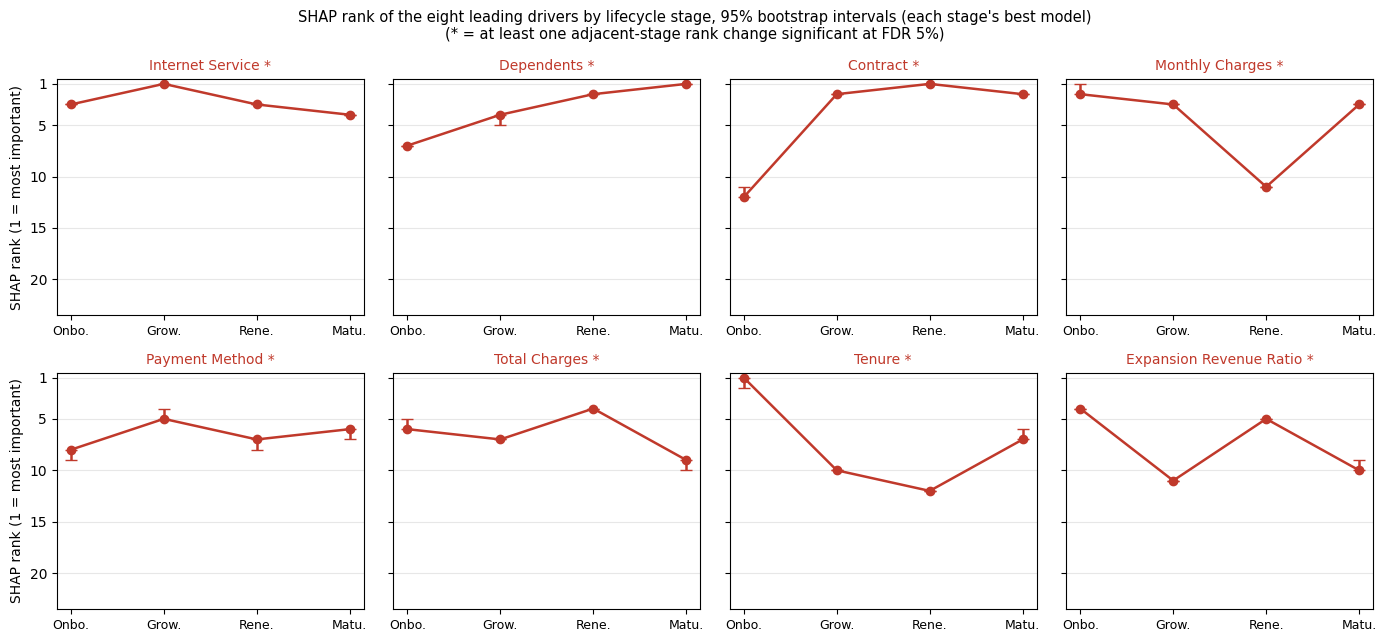

Saved: rank_shift_bootstrap_intervals_best.png

SHAP rankings from: LogisticRegression in every stage (algorithm held fixed)
  per-customer SHAP:     Pooled  (LogisticRegression, 1500 customers explained)
  per-customer SHAP: Onboarding  (LogisticRegression, 1463 customers explained)
  per-customer SHAP:     Growth  (LogisticRegression, 1377 customers explained)
  per-customer SHAP:    Renewal  (LogisticRegression, 1386 customers explained)
  per-customer SHAP:   Maturity  (LogisticRegression, 1408 customers explained)

How uncertain is a rank? (customer bootstrap, 10000 replicates; rank 1 = most important)
            Median rank SD, top-8 features  Median rank SD, other features  Median 95% interval width (places)
Variant                                                                                                       
Pooled                                0.00                            0.00                                 0.0
Onboarding                            0.46          

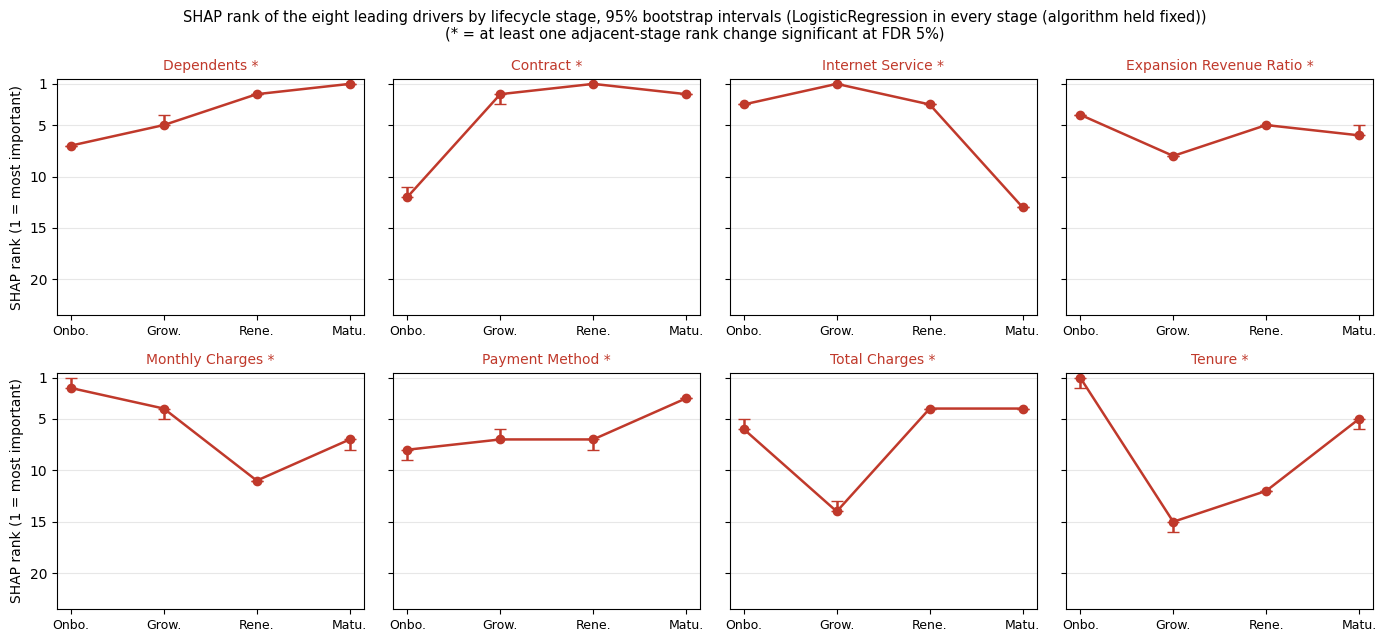

Saved: rank_shift_bootstrap_intervals_LogisticRegression.png

Limits of these tests: the fitted models are treated as fixed and only the customers being explained are resampled, so refitting variability is not captured. The intervals are somewhat too narrow and the tests somewhat too liberal: a significant rank change is a candidate for a real stage difference, not proof of one. Conversely the per-feature tests have low power (see the minimum detectable change), so a non-significant change is not evidence of stability; the noise ceiling is the better-powered comparison.


In [24]:
# --- 4d-5. Bootstrap test of rank shifts (customer-level), with FDR control ---
# Stage 4d-3 showed how rankings move but had no noise reference, so the size of a rank change
# could not be judged. Here each stage's SHAP ranking is re-estimated on bootstrap resamples of
# the customers being explained. That gives (1) an interval for every feature's rank, (2) a test of
# every rank change against sampling noise with the false discovery rate controlled, and (3) a
# "noise ceiling": the highest agreement between two stages' rankings that noise alone would allow.
# It is run twice: with each stage's best model, and with ONE algorithm in every stage, so that a
# rank difference between stages cannot be an artefact of a different algorithm having won each stage.
from scipy.stats import rankdata, spearmanr, norm

N_BOOT = 10000         # replicates. The smallest attainable p-value is 2/(N_BOOT+1) ~ 0.0002; it must be
                       # below alpha/(number of tests) ~ 0.0007, or no test can ever pass the correction
MAX_EXPLAIN = 1500     # customers explained per stage (tree / linear explainers); kernel explainers use 100
FDR_ALPHA = 0.05
BOOT_STAGES = ['Onboarding', 'Growth', 'Renewal', 'Maturity']
BOOT_ALGORITHMS = ['best', 'LogisticRegression']    # 'best' = each stage's best model; otherwise one fixed algorithm

# ---------------------------------------------------------------------------------------------
# Statistical core (no dependence on shap, so it can be checked on simulated data)
# ---------------------------------------------------------------------------------------------
def _bh(p):
    """Benjamini-Hochberg adjusted p-values (q-values), same order as the input."""
    p = np.asarray(p, dtype=float)
    n = len(p)
    o = np.argsort(p)
    r = p[o] * n / (np.arange(n) + 1)
    r = np.minimum.accumulate(r[::-1])[::-1]
    out = np.empty(n)
    out[o] = np.clip(r, 0, 1)
    return out

def boot_ranks(A, n_boot, rng):
    """A: customers x features matrix of per-customer importance. Returns n_boot x features ranks
    (1 = most important) of the mean importance over customers resampled with replacement."""
    n = A.shape[0]
    means = np.empty((n_boot, A.shape[1]))
    for b in range(n_boot):
        means[b] = A[rng.integers(0, n, n)].mean(axis=0)
    return rankdata(-means, axis=1, method='average')

def kendalls_w_fast(R):
    """Kendall's W for a features x raters rank matrix (no tie correction; ties are negligible
    in bootstrap means, so this is used only for the bootstrap interval)."""
    n, m = R.shape
    Rs = R.sum(axis=1)
    return 12 * ((Rs - Rs.mean()) ** 2).sum() / (m * m * (n ** 3 - n))

def split_half_reliability(A, n_splits, rng):
    """Reliability of a stage's importance RANKING: rank the features in two random halves of the
    customers, correlate the two rankings, and step up to the full sample with Spearman-Brown."""
    n = A.shape[0]
    h = n // 2
    rhos = []
    for _ in range(n_splits):
        perm = rng.permutation(n)
        r1 = rankdata(-A[perm[:h]].mean(axis=0))
        r2 = rankdata(-A[perm[h:2 * h]].mean(axis=0))
        rhos.append(np.corrcoef(r1, r2)[0, 1])
    rh = float(np.mean(rhos))
    return 2 * rh / (1 + rh)

def noise_ceiling_table(A, obs, transitions, n_splits=500, seed=42):
    """Highest agreement between two stages' rankings that sampling noise alone would allow
    (geometric mean of the two reliabilities), against the agreement actually observed.
    observed / ceiling near 1 -> the stages cannot be told apart given the noise;
    well below 1 -> the rankings differ by more than noise explains. Approximate benchmark, not a test."""
    rng = np.random.default_rng(seed)
    rel = {v: split_half_reliability(A[v], n_splits, rng) for v in A}
    rows = []
    for a, b in transitions:
        rho = float(np.corrcoef(obs[a], obs[b])[0, 1])
        ceil = float(np.sqrt(max(rel[a], 0) * max(rel[b], 0)))
        rows.append({'Transition': f'{a} -> {b}', 'Observed rho': rho, 'Reliability (from)': rel[a],
                     'Reliability (to)': rel[b], 'Noise ceiling': ceil,
                     'Observed / ceiling': rho / ceil if ceil > 0 else np.nan})
    return pd.DataFrame(rows), rel

def bootstrap_rank_tests(A, families, features, n_boot=N_BOOT, seed=42, alpha=FDR_ALPHA):
    """A: dict variant -> customers x features array. families: dict name -> list of (from, to).
    Rank change = rank(from) - rank(to); POSITIVE means the feature became MORE important.
    Two-sided percentile-bootstrap p-value for 'no change' (the two stages are resampled independently).
    Benjamini-Hochberg is applied WITHIN each family. Returns (dict family -> DataFrame, obs ranks, boot ranks)."""
    rng = np.random.default_rng(seed)
    obs = {v: rankdata(-A[v].mean(axis=0), method='average') for v in A}
    boot = {v: boot_ranks(A[v], n_boot, rng) for v in A}
    out = {}
    for fam, transitions in families.items():
        frames = []
        for a, b in transitions:
            d_obs = obs[a] - obs[b]
            d_boot = boot[a] - boot[b]
            p_ge = (1 + (d_boot >= 0).sum(axis=0)) / (n_boot + 1)
            p_le = (1 + (d_boot <= 0).sum(axis=0)) / (n_boot + 1)
            lo, hi = np.percentile(d_boot, [2.5, 97.5], axis=0)
            frames.append(pd.DataFrame({'Transition': f'{a} -> {b}', 'Feature': list(features),
                                        'Rank (from)': obs[a], 'Rank (to)': obs[b],
                                        'Rank change': d_obs, 'CI low': lo, 'CI high': hi,
                                        'SD of change': d_boot.std(axis=0),
                                        'p (bootstrap)': np.minimum(1.0, 2 * np.minimum(p_ge, p_le))}))
        tests = pd.concat(frames, ignore_index=True)
        # roughly the smallest rank change that could pass the correction, given this feature's own noise
        tests['Min. detectable change'] = norm.ppf(1 - alpha / (2 * len(tests))) * tests['SD of change']
        tests['q (BH)'] = _bh(tests['p (bootstrap)'].values)
        tests['Significant (FDR)'] = tests['q (BH)'] < alpha
        # Rank changes displace one another (if one feature jumps, those it passes each lose a place), so the
        # tests are dependent and BH's guarantee is not assured. Benjamini-Yekutieli is valid under ANY
        # dependence and is reported alongside as a stricter check.
        c_m = np.sum(1.0 / np.arange(1, len(tests) + 1))
        tests['q (BY)'] = np.minimum(1.0, tests['q (BH)'] * c_m)
        tests['Significant (BY)'] = tests['q (BY)'] < alpha
        out[fam] = tests
    return out, obs, boot

# ---------------------------------------------------------------------------------------------
# Per-customer SHAP (Stage 4a keeps only the mean, which is not enough to bootstrap)
# ---------------------------------------------------------------------------------------------
_PARENT = {}
def _parent(name):
    """Original (pre-one-hot) feature for an encoded column, using the SAME rule as collapse_to_raw."""
    if name not in _PARENT:
        _PARENT[name] = collapse_to_raw(pd.Series({name: 1.0})).index[0]
    return _PARENT[name]

def per_customer_shap(gs, X, max_rows=MAX_EXPLAIN, seed=RANDOM_STATE):
    """Per-customer |SHAP| for the fitted model, summed over each feature's one-hot levels.
    Returns a customers x original-features DataFrame. Its column means equal collapse_to_raw of
    the mean |SHAP| used in Stage 4a (the sum is linear), so the two are directly comparable."""
    pipe = gs.best_estimator_
    prep, clf = pipe.named_steps['prep'], pipe.named_steps['clf']
    feat_names = list(get_feature_names(prep))
    is_tree = isinstance(clf, (RandomForestClassifier, GradientBoostingClassifier)) or \
              (HAS_XGB and isinstance(clf, XGBClassifier))
    is_linear = isinstance(clf, LogisticRegression)
    cap = max_rows if (is_tree or is_linear) else min(max_rows, 100)
    Xs = X.sample(cap, random_state=seed) if len(X) > cap else X
    Xt = prep.transform(Xs)
    Xt = Xt.toarray() if hasattr(Xt, 'toarray') else np.asarray(Xt)
    if is_tree:
        sv = shap.TreeExplainer(clf).shap_values(Xt, check_additivity=False)
    elif is_linear:
        sv = shap.LinearExplainer(clf, Xt).shap_values(Xt)
    else:
        bg = shap.sample(Xt, min(50, Xt.shape[0]))
        sv = shap.KernelExplainer(safe_predict_proba_fn(clf), bg).shap_values(Xt, nsamples=100)
    sv = np.abs(_positive_class_shap(sv))
    parents = [_parent(f) for f in feat_names]
    return pd.DataFrame(sv, columns=feat_names).T.groupby(parents).sum().T

# ---------------------------------------------------------------------------------------------
# One full analysis for a given choice of algorithm
# ---------------------------------------------------------------------------------------------
def run_rank_bootstrap(algo, tag):
    label = "each stage's best model" if algo == 'best' else f"{algo} in every stage (algorithm held fixed)"
    print("=" * 100 + f"\nSHAP rankings from: {label}\n" + "=" * 100)
    variants = ['Pooled'] + BOOT_STAGES
    M = {}
    for v in variants:
        a = best_per_variant.loc[v, 'Algorithm'] if algo == 'best' else algo
        Xtr, ytr, _, _ = variant_data(v)
        M[v] = per_customer_shap(fitted_models[(v, a)], Xtr)
        print(f"  per-customer SHAP: {v:>10}  ({a}, {len(M[v])} customers explained)")
    feats = sorted(set.intersection(*[set(m.columns) for m in M.values()]))
    A = {v: M[v][feats].values for v in variants}

    if algo == 'best' and 'shap_importance' in globals():     # consistency with Stage 4a (different customer sample)
        for v in variants:
            ref = collapse_to_raw(shap_importance[v]).reindex(feats)
            print(f"  consistency with Stage 4a ranking, {v:>10}: Spearman rho = "
                  f"{spearmanr(ref.values, A[v].mean(axis=0))[0]:.3f}")

    primary = [('Onboarding', 'Growth'), ('Growth', 'Renewal'), ('Renewal', 'Maturity')]
    secondary = [('Pooled', s) for s in BOOT_STAGES]
    tests, obs_r, boot_r = bootstrap_rank_tests(A, {'primary': primary, 'secondary': secondary}, feats,
                                                N_BOOT, RANDOM_STATE)

    # 1. noise floor: how uncertain is a feature's rank, in places?
    print(f"\nHow uncertain is a rank? (customer bootstrap, {N_BOOT} replicates; rank 1 = most important)")
    rows = []
    for v in variants:
        sd = boot_r[v].std(axis=0)
        lo, hi = np.percentile(boot_r[v], [2.5, 97.5], axis=0)
        lead = obs_r[v] <= 8
        rows.append({'Variant': v, 'Median rank SD, top-8 features': np.median(sd[lead]),
                     'Median rank SD, other features': np.median(sd[~lead]),
                     'Median 95% interval width (places)': np.median(hi - lo)})
    noise_floor = pd.DataFrame(rows).set_index('Variant')
    print(noise_floor.round(2).to_string())

    # 2. noise ceiling: how similar could two stages' rankings be if only noise separated them?
    ceil_tbl, reliab = noise_ceiling_table(A, obs_r, primary + secondary, n_splits=500, seed=RANDOM_STATE)
    print("\nNoise ceiling (split-half reliability of each ranking; Spearman-Brown corrected):")
    print("  " + ", ".join(f"{v}: {r:.2f}" for v, r in reliab.items()))
    print(ceil_tbl.round(3).to_string(index=False))
    print("  Observed / ceiling near 1: the two stages' rankings are as similar as noise allows, so they cannot be told apart.\n"
          "  Well below 1: the rankings differ by more than sampling noise explains. (Approximate benchmark, not a test.)")

    # 3. per-feature tests
    def report(t, name):
        sig = t['Significant (FDR)']
        big = t['Rank change'].abs() >= 5
        print(f"\n{name}: {len(t)} comparisons; {int(sig.sum())} significant at FDR {FDR_ALPHA:.0%} (BH), "
              f"{int(t['Significant (BY)'].sum())} under the stricter BY correction. "
              f"Of the {int(big.sum())} rank changes of 5+ places, {int((big & sig).sum())} are significant (BH).")
        lead = np.minimum(t['Rank (from)'], t['Rank (to)']) <= 8
        mdc = t.loc[lead, 'Min. detectable change']
        print(f"  Smallest rank change that could pass the correction, for leading features (top 8): "
              f"median {mdc.median():.1f} places (range {mdc.min():.1f}-{mdc.max():.1f}). "
              f"A rank change smaller than this cannot be separated from noise here.")
        show = t[sig].reindex(t[sig]['Rank change'].abs().sort_values(ascending=False).index)
        if len(show):
            print(show[['Transition', 'Feature', 'Rank change', 'CI low', 'CI high', 'q (BH)', 'q (BY)']]
                  .round(3).to_string(index=False))
        else:
            print("  none: no individual rank change is distinguishable from sampling noise after FDR control.")
    report(tests['primary'], "PRIMARY family (adjacent stages)")
    report(tests['secondary'], "SECONDARY family (pooled model vs each stage)")
    print(f"\n(Smallest attainable p-value = {2 / (N_BOOT + 1):.4f}; BH/BY are applied within each family separately.)")

    # 4. omnibus agreement with an interval
    W_obs = kendalls_w_fast(np.column_stack([obs_r[s] for s in BOOT_STAGES]))
    W_boot = np.array([kendalls_w_fast(np.column_stack([boot_r[s][b] for s in BOOT_STAGES])) for b in range(N_BOOT)])
    print(f"\nKendall's W across the four stage rankings (this SHAP run): W = {W_obs:.3f}, "
          f"95% bootstrap interval [{np.percentile(W_boot, 2.5):.3f}, {np.percentile(W_boot, 97.5):.3f}]  "
          f"(chance level = {1 / len(BOOT_STAGES):.2f})")

    # 5. rank intervals for the leading drivers, as small multiples
    mean_rank = np.mean([obs_r[s] for s in BOOT_STAGES], axis=0)
    lead_idx = np.argsort(mean_rank)[:8]
    sig_adj = set(tests['primary'].loc[tests['primary']['Significant (FDR)'], 'Feature'])
    fig, axes = plt.subplots(2, 4, figsize=(14, 6.5), sharey=True)
    xs = np.arange(len(BOOT_STAGES))
    for ax, j in zip(axes.ravel(), lead_idx):
        r = np.array([obs_r[s][j] for s in BOOT_STAGES])
        lo = np.array([np.percentile(boot_r[s][:, j], 2.5) for s in BOOT_STAGES])
        hi = np.array([np.percentile(boot_r[s][:, j], 97.5) for s in BOOT_STAGES])
        flagged = feats[j] in sig_adj
        col = '#C0392B' if flagged else '#2C3E50'
        ax.errorbar(xs, r, yerr=[np.maximum(0, r - lo), np.maximum(0, hi - r)], fmt='-o', color=col,
                    capsize=4, lw=1.8)
        ax.set_title(feats[j] + (' *' if flagged else ''), fontsize=10, color=col)
        ax.set_xticks(xs)
        ax.set_xticklabels([s[:4] + '.' for s in BOOT_STAGES], fontsize=9)
        ax.grid(axis='y', alpha=0.3)
    axes[0, 0].set_ylim(len(feats) + 0.5, 0.5)
    axes[0, 0].set_yticks([1] + list(range(5, len(feats) + 1, 5)))
    for ax in axes[:, 0]:
        ax.set_ylabel('SHAP rank (1 = most important)')
    fig.suptitle(f'SHAP rank of the eight leading drivers by lifecycle stage, 95% bootstrap intervals ({label})\n'
                 '(* = at least one adjacent-stage rank change significant at FDR 5%)', fontsize=10.5)
    plt.tight_layout()
    fname = f'rank_shift_bootstrap_intervals_{tag}.png'
    plt.savefig(fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved: {fname}\n")
    return {'tests_primary': tests['primary'], 'tests_secondary': tests['secondary'], 'noise_ceiling': ceil_tbl,
            'noise_floor': noise_floor, 'W': W_obs, 'W_interval': tuple(np.percentile(W_boot, [2.5, 97.5]))}

# ---------------------------------------------------------------------------------------------
# Run
# ---------------------------------------------------------------------------------------------
if not HAS_SHAP:
    print("The real `shap` package is not installed: this cell needs per-customer SHAP values.\n"
          "Run `pip install shap`, restart the runtime and re-run from the top.")
else:
    rank_boot_results = {}
    for algo in BOOT_ALGORITHMS:
        rank_boot_results[algo] = run_rank_bootstrap(algo, algo)
    print("Limits of these tests: the fitted models are treated as fixed and only the customers being explained "
          "are resampled, so refitting variability is not captured. The intervals are somewhat too narrow and the "
          "tests somewhat too liberal: a significant rank change is a candidate for a real stage difference, not "
          "proof of one. Conversely the per-feature tests have low power (see the minimum detectable change), so "
          "a non-significant change is not evidence of stability; the noise ceiling is the better-powered comparison.")
    rank_boot_results['best']['noise_ceiling'].round(3)


### 4d-6. Across-algorithm noise ceiling and bootstrap test (RQ2/RQ3 algorithm-dependence)

Stage 4d-5 gave a noise ceiling and a corrected test for the ACROSS-STAGE comparison. The earlier robustness
checks (4d-2, 4d-4) compared rankings ACROSS ALGORITHMS within a stage using only raw Kendall's W and
Spearman rho, with no noise reference. This cell applies the same machinery as 4d-5 to that comparison:
a noise ceiling (how much would two algorithms' rankings disagree if only sampling noise separated them),
a bootstrap-tested rank change for every feature with BH/BY correction, and (where 3+ algorithms are
compared) Kendall's W with a bootstrap interval. It reuses `bootstrap_rank_tests`, `noise_ceiling_table`
and `kendalls_w_fast` from Stage 4d-5 unchanged.

**Two parts, for a practical reason.**
- **Part A (LIME, all 5 algorithms)** reuses `per_customer_local_all` from Stage 4d-2, already computed for
  the same `N_LIME_ALGO` customers per model, with the SAME customers explained by every algorithm within a
  stage (fixed random state) -- so the comparison is apples-to-apples, but at whatever sample size that
  constant is currently set to (default 15 -- small).
- **Part B (SHAP, Random Forest vs Logistic Regression)** is computed fresh here, at the larger `MAX_EXPLAIN`
  sample size from Stage 4d-5 (~1,400 customers), because both algorithms use fast, exact explainers. SVM and
  MLP need `KernelExplainer`, which is why a 5-algorithm SHAP version is not attempted here.

**How to read it.** Reliability well below 1 (typical for Part A's 15-customer sample) means the ranking
itself is barely estimated, so a low observed/ceiling there may just mean the ranking is noisy, not that the
algorithms genuinely disagree -- treat Part B, with a much larger sample, as the more trustworthy check of
the same question. Raise `N_LIME_ALGO` in the LIME cell and re-run from there for a firmer Part A.

In [25]:
# --- 4d-6. Across-algorithm noise ceiling and bootstrap test (within a stage) ---
# Stage 4d-5 gave a noise ceiling and a corrected test for the ACROSS-STAGE comparison. This
# applies the same machinery to the ACROSS-ALGORITHM comparison within a stage: how much would
# rankings from different algorithms disagree if only sampling noise separated them, and does
# the observed disagreement exceed that. It reuses bootstrap_rank_tests, noise_ceiling_table
# and kendalls_w_fast from Stage 4d-5 unchanged; only the data being compared changes.
#
# Part A (LIME, all 5 algorithms): reuses per_customer_local_all from Stage 4d-2, which already
# explains the SAME customers for every algorithm within a stage (fixed random_state), so the
# comparison is apples-to-apples. No new SHAP computation.
# Part B (SHAP, Random Forest vs Logistic Regression): both use fast, exact explainers (no
# KernelExplainer), so this can be computed fresh across all stages without the runtime cost
# a 5-algorithm SHAP comparison would carry (SVM/MLP need KernelExplainer).

ALGO_FAMILY_ALPHA = 0.05

def algo_comparison(A_dict, n_boot=N_BOOT, seed=RANDOM_STATE, alpha=ALGO_FAMILY_ALPHA):
    """A_dict: algorithm -> customers x features array (SAME customers across algorithms).
    Returns per-pair tests (BH/BY within this stage's family of pairs), a noise-ceiling table,
    and Kendall's W with a bootstrap interval (only meaningful for 3+ algorithms)."""
    algos = list(A_dict)
    feats_n = A_dict[algos[0]].shape[1]
    pairs = [(a, b) for i, a in enumerate(algos) for b in algos[i + 1:]]
    fams, obs_r, boot_r = bootstrap_rank_tests(A_dict, {'pairs': pairs}, range(feats_n), n_boot, seed, alpha)
    ceil_tbl, reliab = noise_ceiling_table(A_dict, obs_r, pairs, n_splits=500, seed=seed)
    out = {'tests': fams['pairs'], 'ceiling': ceil_tbl, 'reliability': reliab}
    if len(algos) >= 3:
        W_obs = kendalls_w_fast(np.column_stack([obs_r[a] for a in algos]))
        W_boot = np.array([kendalls_w_fast(np.column_stack([boot_r[a][b] for a in algos])) for b in range(n_boot)])
        out['W'], out['W_interval'] = W_obs, tuple(np.percentile(W_boot, [2.5, 97.5]))
    return out

def report_algo_comparison(label, results_by_stage):
    print("=" * 100 + f"\n{label}\n" + "=" * 100)
    for stage, res in results_by_stage.items():
        t = res['tests']
        sig_bh, sig_by = int(t['Significant (FDR)'].sum()), int(t['Significant (BY)'].sum())
        print(f"\n--- {stage} ---")
        print("Split-half reliability per algorithm (rank stability if re-explaining a fresh customer sample): "
              + ", ".join(f"{a}={r:.2f}" for a, r in res['reliability'].items()))
        if 'W' in res:
            print(f"Kendall's W across algorithms: {res['W']:.3f}  95% bootstrap interval "
                  f"[{res['W_interval'][0]:.3f}, {res['W_interval'][1]:.3f}]  (chance level = {1/len(res['reliability']):.2f})")
        print(f"Pairwise comparisons: {len(t)}; {sig_bh} significant at FDR {ALGO_FAMILY_ALPHA:.0%} (BH), {sig_by} under BY.")
        print(res['ceiling'].round(3).to_string(index=False))
    print("\nObserved / ceiling near 1: the two algorithms' rankings are as similar as noise allows, so they "
          "cannot be told apart at this sample size. Well below 1: the rankings differ by more than sampling "
          "noise explains. Reliability well below 1 (common in Part A, 15 customers per model) means the ranking "
          "itself is barely estimated, so a low observed/ceiling there may reflect an uninformative ranking rather "
          "than a genuine algorithm difference -- read Part B, with a much larger sample, as the more trustworthy check.")

# ---------------------------------------------------------------------------------------------
# Part A: LIME, all 5 algorithms, reusing existing per_customer_local_all (no new computation)
# ---------------------------------------------------------------------------------------------
part_a_results = {}
for stage in STAGES4:
    feats = sorted(set.intersection(*[set(per_customer_local_all[(stage, a)].columns) for a in ALGOS_]))
    A = {a: per_customer_local_all[(stage, a)][feats].values for a in ALGOS_}
    part_a_results[stage] = algo_comparison(A)
report_algo_comparison(f"PART A: LIME, all 5 algorithms, {N_LIME_ALGO} customers per model (matched within each stage)",
                       part_a_results)

# ---------------------------------------------------------------------------------------------
# Part B: SHAP, Random Forest vs Logistic Regression, fresh but fast (no KernelExplainer)
# ---------------------------------------------------------------------------------------------
if not HAS_SHAP:
    print("\nPart B needs the real `shap` package (per Stage 4d-5); skipped.")
else:
    part_b_results = {}
    for stage in STAGES4:
        Xtr, ytr, _, _ = variant_data(stage)
        M = {}
        for algo in ('RandomForest', 'LogisticRegression'):
            M[algo] = per_customer_shap(fitted_models[(stage, algo)], Xtr)
        feats = sorted(set.intersection(*[set(m.columns) for m in M.values()]))
        A = {a: M[a][feats].values for a in M}
        part_b_results[stage] = algo_comparison(A)
        print(f"  per-customer SHAP computed: {stage:>10} (RandomForest, LogisticRegression, "
              f"{A['RandomForest'].shape[0]} customers)")
report_algo_comparison("PART B: SHAP, Random Forest vs Logistic Regression, ~1,400 matched customers per stage",
                       part_b_results)

print(f"\n(Smallest attainable p-value = {2 / (N_BOOT + 1):.4f}; BH/BY applied within each stage's family of pairs "
      "separately, consistent with Stage 4d-5. Both parts treat the fitted models as fixed and resample only the "
      "customers being explained.)")


PART A: LIME, all 5 algorithms, 15 customers per model (matched within each stage)

--- Onboarding ---
Split-half reliability per algorithm (rank stability if re-explaining a fresh customer sample): LogisticRegression=1.00, MLP=1.00, RandomForest=0.99, SVM=1.00, XGBoost=0.97
Kendall's W across algorithms: 0.673  95% bootstrap interval [0.661, 0.689]  (chance level = 0.20)
Pairwise comparisons: 230; 162 significant at FDR 5% (BH), 149 under BY.
                        Transition  Observed rho  Reliability (from)  Reliability (to)  Noise ceiling  Observed / ceiling
         LogisticRegression -> MLP         0.643               0.999             0.998          0.999               0.644
LogisticRegression -> RandomForest         0.636               0.999             0.986          0.992               0.641
         LogisticRegression -> SVM         0.435               0.999             0.998          0.999               0.435
     LogisticRegression -> XGBoost         0.456               0

  per-customer SHAP computed: Onboarding (RandomForest, LogisticRegression, 1463 customers)


  per-customer SHAP computed:     Growth (RandomForest, LogisticRegression, 1377 customers)


  per-customer SHAP computed:    Renewal (RandomForest, LogisticRegression, 1386 customers)


  per-customer SHAP computed:   Maturity (RandomForest, LogisticRegression, 1408 customers)
PART B: SHAP, Random Forest vs Logistic Regression, ~1,400 matched customers per stage

--- Onboarding ---
Split-half reliability per algorithm (rank stability if re-explaining a fresh customer sample): RandomForest=1.00, LogisticRegression=1.00
Pairwise comparisons: 23; 20 significant at FDR 5% (BH), 19 under BY.
                        Transition  Observed rho  Reliability (from)  Reliability (to)  Noise ceiling  Observed / ceiling
RandomForest -> LogisticRegression         0.681               0.999             0.996          0.998               0.682

--- Growth ---
Split-half reliability per algorithm (rank stability if re-explaining a fresh customer sample): RandomForest=1.00, LogisticRegression=1.00
Pairwise comparisons: 23; 17 significant at FDR 5% (BH), 16 under BY.
                        Transition  Observed rho  Reliability (from)  Reliability (to)  Noise ceiling  Observed / ceiling
R

### 4d-7. Strengthening Part A: a fully defensible LIME across-algorithm comparison

Part A above (Stage 4d-6) rested on 15 customers per model and was flagged indicative, not conclusive.
Part B fixed this for the SHAP comparison by scaling to ~1,400 customers, affordable because Random
Forest and Logistic Regression both use fast, exact explainers. LIME has no equivalent shortcut:
`explain_instance` fits a local surrogate model per customer, and its main cost driver,
`num_samples` (internal perturbations per call), defaults to 5000 -- far more expensive per customer
than a tree or linear SHAP explainer. Matching Part B's rigor for LIME therefore needs both a much
larger customer count AND a lower `num_samples`, and unlike the SHAP case, the right settings depend
on how fast `lime` runs on your machine -- there is no safe default to assume.

**4d-7a times a small real batch first** at several `num_samples` settings and projects the total
runtime of a full 5-algorithm x 4-stage comparison for a range of (customers, num_samples) choices,
so you can pick settings from measured speed rather than a guess.

**4d-7b runs the comparison** at whatever `LARGE_LIME_N` / `LARGE_LIME_NUM_SAMPLES` you set from 4d-7a's
output (defaults: 150 customers, num_samples=1000 -- likely too slow or too fast depending on your
machine; adjust before running), reusing `algo_comparison` and `report_algo_comparison` from Stage
4d-6 unchanged, and prints a direct comparison against Part A's numbers so you can see whether the
small sample was misleading.

**One assumption this does not verify**: that lowering `num_samples` from LIME's default doesn't
distort any individual customer's explanation. The cell notes this explicitly and suggests a spot-check
if your time budget allows one. **Requires the real `lime` package.**

In [26]:
# --- 4d-7a. Timing calibration for a large-sample LIME across-algorithm comparison ---
# Part A's LIME comparison (Stage 4d-6) rested on 15 customers per model and was flagged
# indicative, not conclusive. Part B fixed this for SHAP by scaling to ~1,400 customers,
# affordable because Random Forest and Logistic Regression use fast, exact explainers.
# LIME has no such shortcut: `explain_instance` fits a local model per customer, and its
# default cost driver is `num_samples` (internal perturbations per call), 5000 by default --
# far more expensive per customer than a tree/linear SHAP explainer. Scaling LIME's customer
# count the way Part B scaled SHAP's needs BOTH a larger N and a lower num_samples to stay
# affordable. This cell times a small real batch so you can choose settings from your own
# measured speed, not a guess -- `lime`'s cost depends on the machine, so no number here can
# be trusted without measuring it on yours.

import time as _time

CALIBRATION_STAGE = 'Onboarding'
CALIBRATION_ALGO = 'LogisticRegression'
CALIBRATION_N = 5
CALIBRATION_NUM_SAMPLES_TRIED = [200, 500, 1000, 2000, 5000]  # 5000 = LIME's own default

if not HAS_LIME:
    print("The real `lime` package is not installed: this calibration needs it.\n"
          "Run `pip install lime`, restart the runtime and re-run from the top.")
else:
    Xtr, ytr, _, _ = variant_data(CALIBRATION_STAGE)
    gs = fitted_models[(CALIBRATION_STAGE, CALIBRATION_ALGO)]
    pipe = gs.best_estimator_
    prep, clf = pipe.named_steps['prep'], pipe.named_steps['clf']
    feat_names = list(get_feature_names(prep))
    sample = Xtr.sample(CALIBRATION_N, random_state=RANDOM_STATE)
    Xt = prep.transform(sample)
    Xt_dense = Xt.toarray() if hasattr(Xt, 'toarray') else Xt
    predict_fn = safe_predict_proba_fn(clf)

    print(f"Timing {CALIBRATION_N} customers x {len(CALIBRATION_NUM_SAMPLES_TRIED)} settings of "
          f"num_samples, on {CALIBRATION_ALGO} in {CALIBRATION_STAGE} -- this itself takes a minute or two.\n")
    timings = {}
    for ns_ in CALIBRATION_NUM_SAMPLES_TRIED:
        explainer = LimeTabularExplainer(Xt_dense, feature_names=feat_names, class_names=['No Churn', 'Churn'],
                                         mode='classification', discretize_continuous=False, random_state=RANDOM_STATE)
        t0 = _time.time()
        for i in range(CALIBRATION_N):
            explainer.explain_instance(Xt_dense[i], predict_fn, num_features=len(feat_names), num_samples=ns_)
        per_call = (_time.time() - t0) / CALIBRATION_N
        timings[ns_] = per_call
        print(f"  num_samples={ns_:>5}: {per_call:.3f} s/customer")

    print(f"\nProjected total runtime for a full comparison (5 algorithms x 4 stages), by choice of "
          f"(customers per model, num_samples) -- multiply the per-customer time above by "
          f"5 x 4 x customers:")
    for ns_, per_call in timings.items():
        for n_cust in (50, 100, 200, 400):
            total_min = per_call * 5 * 4 * n_cust / 60
            print(f"  num_samples={ns_:>5}, {n_cust:>3} customers/model: ~{total_min:6.1f} min total")

    print("\nThese are projections from a 5-customer sample on one algorithm/stage, not a measured full "
          "run -- treat them as rough guides, not guarantees, and re-check against actual progress once "
          "the main cell (4d-7b) starts printing per-algorithm timings. Lowering num_samples trades "
          "per-customer fidelity for more customers; since the analysis below only uses the MEAN "
          "importance across many customers per ranking, more customers at a lower num_samples each is "
          "very likely a better trade for this purpose than fewer customers at LIME's full default -- but "
          "this has not been verified against ground truth here, so if runtime allows, include at least "
          "one num_samples=5000 (LIME's default) run as a check that lowering it did not distort the "
          "ranking. Set LARGE_LIME_N and LARGE_LIME_NUM_SAMPLES in the next cell based on what you see here.")


Timing 5 customers x 5 settings of num_samples, on LogisticRegression in Onboarding -- this itself takes a minute or two.

  num_samples=  200: 0.005 s/customer
  num_samples=  500: 0.007 s/customer
  num_samples= 1000: 0.010 s/customer
  num_samples= 2000: 0.013 s/customer
  num_samples= 5000: 0.023 s/customer

Projected total runtime for a full comparison (5 algorithms x 4 stages), by choice of (customers per model, num_samples) -- multiply the per-customer time above by 5 x 4 x customers:
  num_samples=  200,  50 customers/model: ~   0.1 min total
  num_samples=  200, 100 customers/model: ~   0.2 min total
  num_samples=  200, 200 customers/model: ~   0.3 min total
  num_samples=  200, 400 customers/model: ~   0.7 min total
  num_samples=  500,  50 customers/model: ~   0.1 min total
  num_samples=  500, 100 customers/model: ~   0.2 min total
  num_samples=  500, 200 customers/model: ~   0.5 min total
  num_samples=  500, 400 customers/model: ~   1.0 min total
  num_samples= 1000,  5

In [27]:
# --- 4d-7b. Large-sample LIME across-algorithm comparison (Part C) ---
# Reuses bootstrap_rank_tests, noise_ceiling_table and kendalls_w_fast from Stage 4d-5/4d-6
# unchanged -- only the data feeding them changes: LIME importance at a much larger customer
# count than Part A's 15, using the timings from 4d-7a to choose settings that fit your time
# budget. This is what makes the LIME comparison as defensible as Part B made the SHAP one.

import time

LARGE_LIME_N = 150            # customers per model. Raise this if 4d-7a's timing allows it.
LARGE_LIME_NUM_SAMPLES = 1000  # LIME's internal perturbations per customer (library default: 5000)
LARGE_LIME_ALGOS = ALGOS_      # all 5, matching Part A; narrow this list first if runtime is tight

def per_customer_lime(gs, X, feat_names, n_customers=LARGE_LIME_N, num_samples=LARGE_LIME_NUM_SAMPLES,
                      seed=RANDOM_STATE):
    """Same LIME mechanics as local_importance_distribution (Stage 4d-2), generalized to a
    configurable customer count and num_samples so the sample size can be scaled up."""
    pipe = gs.best_estimator_
    prep, clf = pipe.named_steps['prep'], pipe.named_steps['clf']
    sample = X.sample(min(n_customers, len(X)), random_state=seed)
    Xt = prep.transform(sample)
    Xt_dense = Xt.toarray() if hasattr(Xt, 'toarray') else Xt
    predict_fn = safe_predict_proba_fn(clf)
    explainer = LimeTabularExplainer(Xt_dense, feature_names=list(feat_names), class_names=['No Churn', 'Churn'],
                                     mode='classification', discretize_continuous=False, random_state=seed)
    rows = []
    for i in range(Xt_dense.shape[0]):
        exp = explainer.explain_instance(Xt_dense[i], predict_fn, num_features=len(feat_names), num_samples=num_samples)
        w = dict(exp.as_list())
        rows.append([abs(w.get(f, 0.0)) for f in feat_names])
    return pd.DataFrame(rows, columns=feat_names)

if not HAS_LIME:
    print("The real `lime` package is not installed: this cell needs it.\n"
          "Run `pip install lime`, restart the runtime and re-run from the top.")
else:
    t0 = time.time()
    part_c_results = {}
    for stage in STAGES4:
        Xtr, ytr, _, _ = variant_data(stage)
        M = {}
        for algo in LARGE_LIME_ALGOS:
            gs = fitted_models[(stage, algo)]
            feat_names = get_feature_names(gs.best_estimator_.named_steps['prep'])
            t1 = time.time()
            M[algo] = collapse_matrix(per_customer_lime(gs, Xtr, feat_names))
            print(f"  {stage:>10} / {algo:<20}: {M[algo].shape[0]} customers  [{time.time()-t1:.0f}s, "
                  f"running total {time.time()-t0:.0f}s]")
        feats = sorted(set.intersection(*[set(m.columns) for m in M.values()]))
        A = {a: M[a][feats].values for a in M}
        part_c_results[stage] = algo_comparison(A)
    report_algo_comparison(f"PART C: LIME, {len(LARGE_LIME_ALGOS)} algorithms, {LARGE_LIME_N} customers per "
                           f"model (matched within each stage, num_samples={LARGE_LIME_NUM_SAMPLES})",
                           part_c_results)
    print(f"\nTotal time: {(time.time()-t0)/60:.1f} min.")

    print("\nComparison against Part A (15 customers, num_samples=5000 default):")
    for stage in STAGES4:
        if len(LARGE_LIME_ALGOS) >= 3 and 'W' in part_a_results[stage] and 'W' in part_c_results[stage]:
            print(f"  {stage:>10}: Part A W = {part_a_results[stage]['W']:.3f}   "
                  f"Part C W = {part_c_results[stage]['W']:.3f}")
    print("If Part C's W and observed/ceiling ratios are broadly consistent with Part A's, the smaller, "
          "cheaper Part A sample was not misleading -- useful to know for any future re-run. If they "
          "diverge substantially, treat Part C (the larger, better-powered sample) as the more trustworthy "
          "of the two, consistent with how Part A was already flagged as provisional throughout this "
          "notebook. This comparison and everything above it treat the fitted models as fixed and resample "
          "only the customers being explained, and does not independently validate whether "
          "num_samples=1000 (vs. LIME's default 5000) noticeably changes any individual customer's "
          "explanation -- only that it is affordable at this scale; if 4d-7a's timings allow it, re-running "
          "a subset at num_samples=5000 is the direct way to check that trade-off rather than assume it.")


  Onboarding / LogisticRegression  : 150 customers  [1s, running total 1s]
  Onboarding / MLP                 : 150 customers  [2s, running total 3s]
  Onboarding / RandomForest        : 150 customers  [9s, running total 12s]
  Onboarding / SVM                 : 150 customers  [24s, running total 36s]
  Onboarding / XGBoost             : 150 customers  [3s, running total 39s]
      Growth / LogisticRegression  : 150 customers  [1s, running total 43s]
      Growth / MLP                 : 150 customers  [2s, running total 45s]
      Growth / RandomForest        : 150 customers  [9s, running total 54s]
      Growth / SVM                 : 150 customers  [21s, running total 75s]
      Growth / XGBoost             : 150 customers  [4s, running total 79s]
     Renewal / LogisticRegression  : 150 customers  [1s, running total 84s]
     Renewal / MLP                 : 150 customers  [1s, running total 86s]
     Renewal / RandomForest        : 150 customers  [9s, running total 95s]
     Renewal

### 4e. Perturbation validation

A basic sanity check (Section 5.1.4): shuffling each stage's top-3 SHAP-identified drivers
should move predicted churn probability more than shuffling an unrelated ("control")
feature. If it doesn't, the explanations may not reflect what the model is actually
using.

In [28]:
# --- Perturbation validation (Section 5.1.4): shuffle each stage's top-3 SHAP/global
# features in a sample of that stage's customers and confirm predicted churn probability
# moves more than it does for a random control feature. ---

def get_proba(gs, X):
    pipe = gs.best_estimator_
    if hasattr(pipe, 'predict_proba'):
        return pipe.predict_proba(X)[:, 1]
    scores = pipe.decision_function(X)
    return (scores - scores.min()) / (scores.max() - scores.min() + 1e-9)

perturbation_rows = []
rng = np.random.RandomState(RANDOM_STATE)

for stage in ['Onboarding', 'Growth', 'Renewal', 'Maturity']:
    Xtr, ytr, Xte, yte = variant_data(stage)
    gs = fitted_models[(stage, best_per_variant.loc[stage, 'Algorithm'])]
    sample = Xte.sample(min(100, len(Xte)), random_state=RANDOM_STATE)
    baseline_proba = get_proba(gs, sample)

    top_features = collapse_to_raw(shap_importance[stage]).head(3).index.tolist()
    other_features = [c for c in FEATURE_COLS if c not in top_features]
    control_feature = rng.choice(other_features)

    for feat in top_features + [control_feature]:
        shuffled = sample.copy()
        shuffled[feat] = shuffled[feat].sample(frac=1.0, random_state=RANDOM_STATE).values
        new_proba = get_proba(gs, shuffled)
        mean_abs_shift = np.abs(new_proba - baseline_proba).mean()
        perturbation_rows.append({'Stage': stage, 'Feature': feat,
                                   'Is_top_driver': feat in top_features,
                                   'Mean_abs_prediction_shift': mean_abs_shift})

perturbation_df = pd.DataFrame(perturbation_rows)
summary = perturbation_df.groupby(['Stage', 'Is_top_driver'])['Mean_abs_prediction_shift'].mean().unstack()
summary.columns = ['Control_feature_shift', 'Top_driver_avg_shift']
summary['Top_driver_exceeds_control'] = summary['Top_driver_avg_shift'] > summary['Control_feature_shift']
print(summary.round(4))
print("\nWhere Top_driver_exceeds_control is True, shuffling the SHAP-identified top drivers moves "
      "predictions more than shuffling an unrelated feature -- a basic sanity check that the "
      "explanations reflect features the model actually relies on, not artifacts.")


            Control_feature_shift  Top_driver_avg_shift  Top_driver_exceeds_control
Stage                                                                              
Growth                     0.0205                0.0694                        True
Maturity                   0.0124                0.0510                        True
Onboarding                 0.0088                0.0885                        True
Renewal                    0.0264                0.0677                        True

Where Top_driver_exceeds_control is True, shuffling the SHAP-identified top drivers moves predictions more than shuffling an unrelated feature -- a basic sanity check that the explanations reflect features the model actually relies on, not artifacts.


### 4f. Collinearity check (VIF): did the SaaS-proxy feature engineering actually fix
the collinearity risk?

An earlier pass of this notebook found `Internet Service` dominating the Stage 5 playbook
partly because of collinearity: three engineered flags and six of the dataset's own
service-column categories were exact (R^2=1.0) linear restatements of columns already in
the model. The Stage 2 feature engineering above was revised to fix this (collapsing the
redundant categories, dropping the duplicate flags). This cell verifies that fix, and
also confirms why the new `Multi-Product Adoption` feature was computed but deliberately
left out of the model's predictors - it turned out to have its own, different collinearity
problem (see the cell output). `sklearn` has no built-in VIF function, so it's computed
here via `1/(1 - R^2)` from regressing each column on all the others, mathematically
identical to the standard `statsmodels` approach.

In [29]:
# --- Collinearity check (Section 5.1.4's own stated limitation): verifies the SaaS-proxy
# feature engineering in Stage 2 (collapsing "No internet/phone service" levels, dropping
# the three exact-duplicate flags) actually resolved the collinearity found in an earlier
# pass, and documents what collinearity legitimately remains. ---

from sklearn.linear_model import LinearRegression

def compute_vif(X_design):
    """VIF via 1/(1-R^2) of each column regressed on all the others -- avoids needing
    statsmodels. Scale-invariant, so raw vs. standardized numeric columns don't matter."""
    vifs = {}
    for col in X_design.columns:
        y_col = X_design[col].values.astype(float)
        X_other = X_design.drop(columns=[col]).values.astype(float)
        r2 = LinearRegression().fit(X_other, y_col).score(X_other, y_col)
        vifs[col] = np.inf if r2 > 1 - 1e-9 else 1 / (1 - r2)
    return pd.Series(vifs).sort_values(ascending=False)

# One reference level dropped per categorical -- the standard, dummy-trap-free way to
# compute VIF (separate from the encoder actually used for modeling, which keeps every
# level for multi-level fields; that choice doesn't affect VIF interpretation here)
design_dropfirst = pd.get_dummies(X_train[FEATURE_COLS], columns=CATEGORICAL_COLS, drop_first=True).astype(float)

vif_current = compute_vif(design_dropfirst)
print(f"Infinite-VIF columns in the current (post-SaaS-proxy-engineering) feature set: "
      f"{(vif_current == np.inf).sum()} of {len(vif_current)}")
print(vif_current.head(12).round(2))

print("\nInternet-Service-related columns specifically:")
internet_cols = [c for c in vif_current.index if 'Internet' in c]
print(vif_current[internet_cols].round(2))

# The one legitimate, expected source of collinearity that remains: Num Addon Services
# is a literal sum of its own 6 components -- including both an aggregate and its parts
# always does this, it isn't a data problem, and it predates this feature-engineering pass.
addon_cols = ['Online Security_Yes', 'Online Backup_Yes', 'Device Protection_Yes',
              'Tech Support_Yes', 'Streaming TV_Yes', 'Streaming Movies_Yes']
r2_addons = LinearRegression().fit(design_dropfirst[addon_cols].values, design_dropfirst['Num Addon Services'].values).score(
    design_dropfirst[addon_cols].values, design_dropfirst['Num Addon Services'].values)
print(f"\nR^2 of 'Num Addon Services' vs. its own 6 component columns: {r2_addons:.4f} "
      "(expected -- it's a sum of these columns by construction)")

# Confirms why 'Multi-Product Adoption' (Stage 2) was computed but deliberately excluded
# from the model's feature set: this dataset has zero customers with neither Internet
# nor Phone service, which makes the AND-combination exactly linearly reconstructible
# from the two inputs once both are already in the model.
mpa_check = X_train.assign(**{
    'Internet Service_No': (X_train['Internet Service'] == 'No').astype(float),
    'Phone Service_Yes': (X_train['Phone Service'] == 'Yes').astype(float),
})
r2_mpa = LinearRegression().fit(
    mpa_check[['Internet Service_No', 'Multi-Product Adoption']], mpa_check['Phone Service_Yes']
).score(mpa_check[['Internet Service_No', 'Multi-Product Adoption']], mpa_check['Phone Service_Yes'])
print(f"\nR^2 of Phone Service explained by (Internet Service + Multi-Product Adoption): {r2_mpa:.4f} "
      "-- confirms why Multi-Product Adoption was kept as a computed column but excluded "
      "from the model's predictors (see Stage 2).")

print(f"""
Summary: {(vif_current == np.inf).sum()} column(s) still show infinite VIF, all traceable
to the expected Num Addon Services / component-columns relationship above -- the
structural redundancy involving Internet Service (the "No internet/phone service"
categories and the exact-duplicate engineered flags) found in an earlier pass is
resolved. Internet Service's VIF is now driven by real correlation with other features
(e.g. Monthly Charges, streaming add-ons), not an artifact -- its continued prominence in
the Stage 5 playbook is more defensible as a genuine finding now than it was before this
feature-engineering revision.
""")


Infinite-VIF columns in the current (post-SaaS-proxy-engineering) feature set: 7 of 27
Num Addon Services                 inf
Device Protection_Yes              inf
Tech Support_Yes                   inf
Online Security_Yes                inf
Online Backup_Yes                  inf
Streaming TV_Yes                   inf
Streaming Movies_Yes               inf
Monthly Charges                 962.23
Internet Service_Fiber optic    170.70
Internet Service_No             108.35
Phone Service_Yes                35.34
Avg Monthly Spend                22.42
dtype: float64

Internet-Service-related columns specifically:
Internet Service_Fiber optic    170.70
Internet Service_No             108.35
dtype: float64

R^2 of 'Num Addon Services' vs. its own 6 component columns: 1.0000 (expected -- it's a sum of these columns by construction)

R^2 of Phone Service explained by (Internet Service + Multi-Product Adoption): 1.0000 -- confirms why Multi-Product Adoption was kept as a computed column but ex

### 4g. Why does `Avg Monthly Spend` top the pooled SHAP ranking but not appear in any
single stage's top-3?

`Avg Monthly Spend = Total Charges / (Tenure + 1)` is built from two features already in
the model. Rather than guess at an explanation, this checks it directly - and along the
way, catches a real bug: the original `Total Charges` imputation used the population
median for the 11 customers with missing values, all of whom are `Tenure==0` (confirmed
against the raw data) and hadn't been billed a full cycle yet. Dividing a population
median by `(0+1)=1` produced an absurd ~$1,398/month `Avg Monthly Spend` for those
customers - which has been quietly inflating the Onboarding stage's Avg Monthly Spend
variance in every run of this notebook up to this point. Fixed in Stage 2 above by
imputing `0` instead (domain-correct: they haven't been billed anything yet).

With that fixed, the actual explanation for the pooled-vs-stage pattern turns out to be
different from the first, reasonable-sounding guess (that it's a compressed tenure
proxy) - see the cell output for what the R^2/correlation numbers actually show.

In [30]:
# --- Sanity check: why does 'Avg Monthly Spend' top the POOLED SHAP ranking but not
# appear in any single stage's top-3? Avg Monthly Spend = Total Charges / (Tenure + 1),
# built from two features (Tenure, Total Charges) already in the model. Tests whether
# it's acting as a compressed Tenure stand-in at the pooled level, and/or whether its
# redundancy with its own component features changes between the pooled (wide tenure
# range) and within-stage (narrow tenure range) settings. ---

from sklearn.linear_model import LinearRegression

def r2_from_components(df, target, components):
    r2 = LinearRegression().fit(df[components], df[target]).score(df[components], df[target])
    return r2

components = ['Tenure', 'Total Charges', 'Monthly Charges']

print("R^2 of 'Avg Monthly Spend' explained by its own component features (Tenure, Total "
      "Charges, Monthly Charges) -- pooled vs. within each stage:\n")
r2_pooled = r2_from_components(X_train, 'Avg Monthly Spend', components)
print(f"  Pooled  (n={len(X_train)}): R^2 = {r2_pooled:.4f}")
for stage in ['Onboarding', 'Growth', 'Renewal', 'Maturity']:
    sub = X_train[X_train['Lifecycle Stage'] == stage]
    r2_stage = r2_from_components(sub, 'Avg Monthly Spend', components)
    print(f"  {stage:>10} (n={len(sub)}): R^2 = {r2_stage:.4f}")

print("\nCorrelation between 'Avg Monthly Spend' and 'Tenure' -- pooled vs. within each stage:\n")
corr_pooled = X_train['Avg Monthly Spend'].corr(X_train['Tenure'])
print(f"  Pooled  : r = {corr_pooled:.3f}  (tenure range 0-72 mo.)")
for stage in ['Onboarding', 'Growth', 'Renewal', 'Maturity']:
    sub = X_train[X_train['Lifecycle Stage'] == stage]
    corr_stage = sub['Avg Monthly Spend'].corr(sub['Tenure'])
    lo, hi = int(sub['Tenure'].min()), int(sub['Tenure'].max())
    print(f"  {stage:>10}: r = {corr_stage:.3f}  (tenure range {lo}-{hi} mo.)")

print("\n'Avg Monthly Spend' distribution by stage (does it behave non-monotonically?):")
print(X_train.groupby('Lifecycle Stage', observed=True)['Avg Monthly Spend'].describe()[['mean', 'std', 'min', 'max']].round(2))

print("""
Interpretation (corrected from the initial hypothesis -- the numbers tell a different,
more specific story than "it's a tenure proxy"): correlation with Tenure is weak
everywhere, including pooled (r=0.17 at most) -- that theory doesn't hold. What the R^2
pattern actually shows: WITHIN any single stage, Avg Monthly Spend is nearly perfectly
linearly redundant with its own components (R^2 up to 0.998 in Maturity), because
1/(Tenure+1) barely changes over a narrow ~20-26-month window -- the ratio collapses to
being almost a constant multiple of Total Charges there, which is exactly why it adds
nothing to any single stage's SHAP ranking. POOLED, tenure spans the full 0-72-month
range, so 1/(Tenure+1) varies enormously and genuinely decouples the ratio from a simple
linear combination of its parts (R^2 drops to 0.24) -- it carries real, non-redundant
information only when the tenure range is wide enough for that nonlinearity to matter.
This is a legitimate, reportable finding about how a ratio feature's redundancy depends
on the range of its denominator, not a SHAP artifact -- but it does mean Avg Monthly
Spend's role in the model is different across the pooled vs. stage-specific comparison,
worth naming explicitly rather than treating its pooled-vs-stage prominence as
comparable "the same feature mattering differently by stage" the way a genuinely
lifecycle-varying driver would.
""")


R^2 of 'Avg Monthly Spend' explained by its own component features (Tenure, Total Charges, Monthly Charges) -- pooled vs. within each stage:

  Pooled  (n=5634): R^2 = 0.9504
  Onboarding (n=1463): R^2 = 0.9559
      Growth (n=1377): R^2 = 0.9924
     Renewal (n=1386): R^2 = 0.9971
    Maturity (n=1408): R^2 = 0.9984

Correlation between 'Avg Monthly Spend' and 'Tenure' -- pooled vs. within each stage:

  Pooled  : r = 0.421  (tenure range 0-72 mo.)
  Onboarding: r = 0.476  (tenure range 0-9 mo.)
      Growth: r = 0.089  (tenure range 10-29 mo.)
     Renewal: r = 0.052  (tenure range 30-55 mo.)
    Maturity: r = 0.090  (tenure range 56-72 mo.)

'Avg Monthly Spend' distribution by stage (does it behave non-monotonically?):
                  mean    std    min     max
Lifecycle Stage                             
Onboarding       39.56  22.29   0.00   97.04
Growth           57.36  27.15  14.98  110.74
Renewal          66.29  29.88  16.78  116.93
Maturity         74.45  30.87  17.30  118.9

## Stage 5 - Lifecycle-Based Retention Framework

Maps each stage's top-3 empirically-identified drivers to a templated retention action.
`ACTION_LIBRARY` is a starting point - replace the action text with your actual
customer-success/relationship-management playbook language once the stage-specific
drivers are finalized (Section 5.1.5).

In [31]:
# --- 5.1.5 Stage 5: Lifecycle-Based Retention Framework ---
# Maps each stage's empirically-identified top drivers to a templated retention action.
# The action text is a starting point for the thesis -- swap in the real CS/RM playbook
# language once the stage-specific drivers are finalized.
#
# Each action is also tagged with one of the FIVE customer-success/relationship-management
# categories Section 5.1.5 explicitly names as how behavioral themes should tie to
# retention activity -- so every recommendation traces back to a named CS/RM process
# element, not just an ad-hoc suggestion:
#   1. Customer-focused education
#   2. Recommendations regarding non-utilized features
#   3. Engagement campaigns to keep customers active
#   4. Renewal agreement tips
#   5. Communication methods tailored to specific customers

CS_RM_CATEGORIES = [
    'Customer-focused education',
    'Non-utilized feature recommendations',
    'Engagement campaigns',
    'Renewal agreement tips',
    'Tailored communication',
]

# feature -> (action text, CS/RM category)
ACTION_LIBRARY = {
    'Contract':             ("Offer an incentivized upgrade from month-to-month to a term contract.", 'Renewal agreement tips'),
    'Tenure':                ("Trigger a tenure-based check-in / loyalty touchpoint.", 'Engagement campaigns'),
    'Internet Service':      ("Review fiber/DSL service-quality tickets for this segment.", 'Tailored communication'),
    'Monthly Charges':       ("Audit plan fit; offer a right-sized bundle if overpaying for usage.", 'Renewal agreement tips'),
    'Total Charges':         ("Review cumulative spend against plan value; consider a loyalty credit.", 'Engagement campaigns'),
    'Avg Monthly Spend':     ("Review cumulative spend against plan value; consider a loyalty credit.", 'Engagement campaigns'),
    'Charges Per Service':   ("Bundle underused add-ons or adjust pricing tier.", 'Non-utilized feature recommendations'),
    'Dependents':            ("Offer a multi-line / family plan bundle.", 'Non-utilized feature recommendations'),
    'Partner':               ("Offer a multi-line / family plan bundle.", 'Non-utilized feature recommendations'),
    'Payment Method':        ("Nudge toward autopay with a small incentive to reduce billing friction.", 'Tailored communication'),
    'Paperless Billing':     ("Confirm billing communications are reaching the customer.", 'Tailored communication'),
    'Online Security':       ("Cross-sell/educate on Online Security add-on.", 'Customer-focused education'),
    'Online Backup':         ("Cross-sell/educate on Online Backup add-on.", 'Customer-focused education'),
    'Device Protection':     ("Cross-sell/educate on Device Protection add-on.", 'Customer-focused education'),
    'Tech Support':          ("Route to proactive tech-support check-in.", 'Engagement campaigns'),
    'Streaming TV':          ("Highlight underused streaming entitlements.", 'Non-utilized feature recommendations'),
    'Streaming Movies':      ("Highlight underused streaming entitlements.", 'Non-utilized feature recommendations'),
    'Multiple Lines':        ("Offer a multi-line bundle discount.", 'Non-utilized feature recommendations'),
    'Num Addon Services':    ("Run a feature-adoption campaign for unused add-ons.", 'Non-utilized feature recommendations'),
    'Phone Service':         ("Confirm core service is functioning as expected; proactive outreach if not.", 'Tailored communication'),
    'Senior Citizen':        ("Route to a support-oriented onboarding/renewal track.", 'Customer-focused education'),
    'Gender':                ("No direct action -- demographic control variable, not a lever.", None),
}

def get_action(feature):
    return ACTION_LIBRARY.get(feature, ("Investigate driver and define a targeted action.", None))

playbook_rows = []
for stage in ['Onboarding', 'Growth', 'Renewal', 'Maturity']:
    top_drivers = collapse_to_raw(shap_importance[stage]).head(3)
    for rank, (feat, score) in enumerate(top_drivers.items(), start=1):
        action_text, category = get_action(feat)
        playbook_rows.append({
            'Lifecycle Stage': stage,
            'Rank': rank,
            'Driver (SHAP-identified)': feat,
            'Global Importance': round(score, 4),
            'Recommended Action': action_text,
            'CS/RM Category': category,
        })

playbook_df = pd.DataFrame(playbook_rows)
print(playbook_df.to_string(index=False))

print("\nRetention actions by CS/RM category (Section 5.1.5's taxonomy) -- coverage check:")
category_counts = playbook_df['CS/RM Category'].value_counts()
print(category_counts.reindex(CS_RM_CATEGORIES, fill_value=0))


Lifecycle Stage  Rank Driver (SHAP-identified)  Global Importance                                                    Recommended Action                       CS/RM Category
     Onboarding     1          Monthly Charges             0.4922   Audit plan fit; offer a right-sized bundle if overpaying for usage.               Renewal agreement tips
     Onboarding     2                   Tenure             0.4803                 Trigger a tenure-based check-in / loyalty touchpoint.                 Engagement campaigns
     Onboarding     3         Internet Service             0.3340            Review fiber/DSL service-quality tickets for this segment.               Tailored communication
         Growth     1         Internet Service             0.0829            Review fiber/DSL service-quality tickets for this segment.               Tailored communication
         Growth     2                 Contract             0.0632 Offer an incentivized upgrade from month-to-month to a term contract.

### Data-driven timing: extending the quartile approach one level down

`STAGE_TIMING` in an earlier draft was a templated guess ("first 30 days", etc.) - not
actually derived from anything. This cell fixes that by applying the same idea used to
define the four lifecycle stages in Stage 2 (empirical tenure-based binning) one level
down: splitting each stage's own tenure range into thirds (Early/Mid/Late) and measuring
the observed churn rate in each. Wherever churn concentrates *within* the stage is the
evidence-based answer to "when do we intervene" - not a guess.

In [32]:
# --- Data-driven "optimal timing" (replaces the templated STAGE_TIMING guesses):
# apply the SAME quartile-style binning used to define the four lifecycle stages
# (Section 5.1.2) one level down -- splitting each stage's own tenure range into
# thirds (Early / Mid / Late) and measuring observed churn rate in each. Wherever
# churn concentrates within the stage is the evidence-based answer to "when do we
# intervene", not a guess. ---

def substage_churn_profile(stage, n_subbins=3):
    mask = X_train['Lifecycle Stage'] == stage
    sub_tenure = X_train.loc[mask, 'Tenure']
    sub_churn = y_train.loc[mask]

    labels = ['Early', 'Mid', 'Late'][:n_subbins]
    try:
        sub_bins = pd.qcut(sub_tenure, q=n_subbins, labels=labels, duplicates='drop')
    except ValueError:
        # too few distinct tenure values for n_subbins groups -- fall back to fewer bins
        sub_bins = pd.qcut(sub_tenure, q=2, labels=['Early', 'Late'], duplicates='drop')

    profile = sub_churn.groupby(sub_bins, observed=True).agg(['mean', 'count'])
    profile.columns = ['Churn Rate', 'N Customers']
    return profile.sort_values('Churn Rate', ascending=False)

def data_driven_timing_text(stage):
    profile = substage_churn_profile(stage)
    peak_window = profile.index[0]
    peak_rate = profile.iloc[0]['Churn Rate']
    overall_rate = y_train.loc[X_train['Lifecycle Stage'] == stage].mean()
    tenure_range = X_train.loc[X_train['Lifecycle Stage'] == stage, 'Tenure']
    lo, hi = int(tenure_range.min()), int(tenure_range.max())
    return (f"Within {stage} (tenure {lo}-{hi} mo.), churn concentrates in the "
            f"**{peak_window}** portion of the window ({peak_rate:.1%} vs. {overall_rate:.1%} "
            f"stage-wide average) -- intervene there, not uniformly across the whole stage.")

print("Within-stage churn profile (this is what 'optimal timing' is now derived from):\n")
substage_profiles = {}
for stage in ['Onboarding', 'Growth', 'Renewal', 'Maturity']:
    profile = substage_churn_profile(stage)
    substage_profiles[stage] = profile
    print(f"--- {stage} ---")
    print(profile.round(3))
    print(data_driven_timing_text(stage))
    print()


Within-stage churn profile (this is what 'optimal timing' is now derived from):

--- Onboarding ---
        Churn Rate  N Customers
Tenure                         
Early        0.606          495
Mid          0.474          587
Late         0.391          381
Within Onboarding (tenure 0-9 mo.), churn concentrates in the **Early** portion of the window (60.6% vs. 49.7% stage-wide average) -- intervene there, not uniformly across the whole stage.

--- Growth ---
        Churn Rate  N Customers
Tenure                         
Early        0.334          512
Mid          0.300          436
Late         0.217          429
Within Growth (tenure 10-29 mo.), churn concentrates in the **Early** portion of the window (33.4% vs. 28.7% stage-wide average) -- intervene there, not uniformly across the whole stage.

--- Renewal ---
        Churn Rate  N Customers
Tenure                         
Mid          0.198          469
Early        0.198          485
Late         0.162          432
Within Rene

### Stage 5 v2 - filling in the two elements Section 5.1.5 asks for that the first
pass above doesn't cover

Section 5.1.5 specifies five required elements in the retention playbook: (1) each
lifecycle stage, (2) its identified drivers, (3) recommended actions, **(4) optimal
points in time to take action, and (5) expected outcomes of retaining customers**. The
first playbook cell above covers 1-3; this cell adds 4 and 5, and also tightens which
drivers make the list:

- **Driver selection** now prefers features that are *both* top-ranked by SHAP for that
  stage *and* significant in at least 3 of the 5 algorithms in the Stage 4d-2 robustness
  check, rather than relying on a single algorithm's SHAP ranking alone.
- **Optimal timing** now comes from the within-stage churn-concentration analysis above,
  not a template.
- **Expected outcome** reuses the perturbation-validation results from Stage 4e: the
  average shift in predicted churn probability when that driver is disturbed, expressed
  both as a percentage-point figure and as a multiple of an unrelated ("control")
  feature's shift - a concrete, defensible stand-in for "how much does addressing this
  driver matter" until you have real intervention/outcome data to calibrate against.

In [33]:
# --- 5.1.5 Stage 5 v2: Lifecycle-Based Retention Framework, aligned to all 5 required
# elements from Section 5.1.5: (1) stage, (2) drivers, (3) recommended action,
# (4) optimal timing, (5) expected outcome. ---

def expected_outcome_text(stage, feature):
    """Pulls the perturbation-validation shift for this stage's top-driver group as a
    quantitative proxy for 'expected outcome' -- how much predicted churn probability
    moves when this driver group is disturbed, vs. an unrelated control feature."""
    row = perturbation_df[(perturbation_df['Stage'] == stage) & (perturbation_df['Feature'] == feature)]
    if len(row):
        shift = row['Mean_abs_prediction_shift'].iloc[0]
        control = summary.loc[stage, 'Control_feature_shift']
        multiple = shift / control if control > 0 else float('nan')
        return (f"~{shift:.1%} shift in predicted churn probability when this driver changes "
                f"({multiple:.1f}x the shift from an unrelated feature)")
    return "Not directly perturbation-tested (see Kruskal-Wallis robustness table instead)."

playbook_v2_rows = []
for stage in ['Onboarding', 'Growth', 'Renewal', 'Maturity']:
    shap_ranked = collapse_to_raw(shap_importance[stage])
    # Prefer drivers that are BOTH top-ranked by SHAP AND survive the cross-algorithm
    # robustness check (cell 25) -- falls back to pure SHAP rank if nothing overlaps.
    robust_features = set(robustness[robustness >= 3].index)  # significant in >=3 of 5 algorithms
    ranked_and_robust = [f for f in shap_ranked.index if f in robust_features]
    top_drivers = (ranked_and_robust[:3] if len(ranked_and_robust) >= 3
                   else shap_ranked.head(3).index.tolist())

    for rank, feat in enumerate(top_drivers, start=1):
        action_text, category = get_action(feat)
        playbook_v2_rows.append({
            'Lifecycle Stage': stage,
            'Rank': rank,
            'Driver': feat,
            'Global Importance (SHAP)': round(shap_ranked.get(feat, float('nan')), 4),
            'Cross-Algorithm Robust (n/5)': int(robustness.get(feat, 0)),
            'Recommended Action': action_text,
            'CS/RM Category': category,
            'Optimal Timing (data-driven)': data_driven_timing_text(stage),
            'Expected Outcome': expected_outcome_text(stage, feat),
        })

playbook_df_v2 = pd.DataFrame(playbook_v2_rows)
pd.set_option('display.max_colwidth', 60)
playbook_df_v2


,Lifecycle Stage,Rank,Driver,Global Importance (SHAP),Cross-Algorithm Robust (n/5),Recommended Action,CS/RM Category,Optimal Timing (data-driven),Expected Outcome
0,Onboarding,1,Monthly Charges,0.4922,5,Audit plan fit; offer a right-sized bundle if overpaying...,Renewal agreement tips,"Within Onboarding (tenure 0-9 mo.), churn concentrates i...",~10.5% shift in predicted churn probability when this dr...
1,Onboarding,2,Tenure,0.4803,5,Trigger a tenure-based check-in / loyalty touchpoint.,Engagement campaigns,"Within Onboarding (tenure 0-9 mo.), churn concentrates i...",~11.7% shift in predicted churn probability when this dr...
2,Onboarding,3,Internet Service,0.3340,5,Review fiber/DSL service-quality tickets for this segment.,Tailored communication,"Within Onboarding (tenure 0-9 mo.), churn concentrates i...",~4.4% shift in predicted churn probability when this dri...
3,Growth,1,Internet Service,0.0829,5,Review fiber/DSL service-quality tickets for this segment.,Tailored communication,"Within Growth (tenure 10-29 mo.), churn concentrates in ...",~8.9% shift in predicted churn probability when this dri...
4,Growth,2,Contract,0.0632,5,Offer an incentivized upgrade from month-to-month to a t...,Renewal agreement tips,"Within Growth (tenure 10-29 mo.), churn concentrates in ...",~5.4% shift in predicted churn probability when this dri...
5,Growth,3,Monthly Charges,0.0437,5,Audit plan fit; offer a right-sized bundle if overpaying...,Renewal agreement tips,"Within Growth (tenure 10-29 mo.), churn concentrates in ...",~6.5% shift in predicted churn probability when this dri...
6,Renewal,1,Contract,0.6096,5,Offer an incentivized upgrade from month-to-month to a t...,Renewal agreement tips,"Within Renewal (tenure 30-55 mo.), churn concentrates in...",~9.1% shift in predicted churn probability when this dri...
7,Renewal,2,Dependents,0.5934,5,Offer a multi-line / family plan bundle.,Non-utilized feature recommendations,"Within Renewal (tenure 30-55 mo.), churn concentrates in...",~8.6% shift in predicted churn probability when this dri...
8,Renewal,3,Internet Service,0.2362,5,Review fiber/DSL service-quality tickets for this segment.,Tailored communication,"Within Renewal (tenure 30-55 mo.), churn concentrates in...",~2.7% shift in predicted churn probability when this dri...
9,Maturity,1,Dependents,0.0846,5,Offer a multi-line / family plan bundle.,Non-utilized feature recommendations,"Within Maturity (tenure 56-72 mo.), churn concentrates i...",~7.9% shift in predicted churn probability when this dri...


## Stage 6 - Conceptual Framework Development

Section 5.1.6 asks for "one overall conceptual framework" synthesizing the four
integrated aspects developed across Stages 2-5: lifecycle-aware behavioral modeling, ML
churn prediction, XAI transparency (both global/SHAP and local/LIME), and the retention
playbook - with retention outcomes feeding back into the next behavioral-modeling cycle
rather than the framework being a one-shot pipeline.

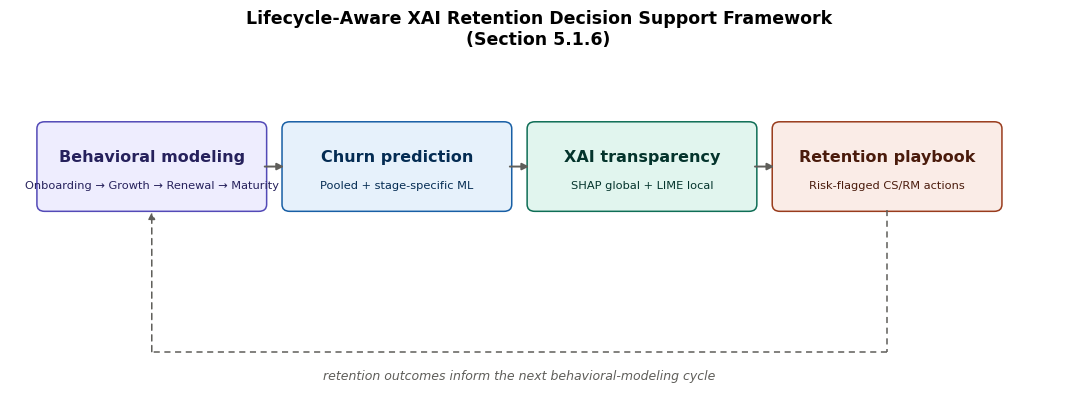

Saved: conceptual_framework_diagram.png


In [34]:
# --- Section 5.1.6: the conceptual framework diagram, as a real notebook cell (not a
# separate file to lose track of). Ties the four integrated stages together with a
# feedback loop -- retention outcomes informing the next behavioral-modeling cycle. ---
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.path import Path

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.set_xlim(0, 11)
ax.set_ylim(-1.7, 2.2)
ax.axis('off')

stages = [
    (0.3, 'Behavioral modeling', 'Onboarding \u2192 Growth \u2192 Renewal \u2192 Maturity', '#EEEDFE', '#534AB7', '#26215C'),
    (2.85, 'Churn prediction', 'Pooled + stage-specific ML', '#E6F1FB', '#185FA5', '#042C53'),
    (5.4, 'XAI transparency', 'SHAP global + LIME local', '#E1F5EE', '#0F6E56', '#04342C'),
    (7.95, 'Retention playbook', 'Risk-flagged CS/RM actions', '#FAECE7', '#993C1D', '#4A1B0C'),
]
box_w, box_h, y0 = 2.35, 1.0, 0.5

for x, title, subtitle, face, edge, textcolor in stages:
    box = FancyBboxPatch((x, y0), box_w, box_h, boxstyle="round,pad=0.02,rounding_size=0.08",
                          facecolor=face, edgecolor=edge, linewidth=1.1, zorder=2)
    ax.add_patch(box)
    ax.text(x + box_w / 2, y0 + box_h * 0.62, title, ha='center', va='center',
            fontsize=11.5, fontweight='bold', color=textcolor, zorder=3)
    ax.text(x + box_w / 2, y0 + box_h * 0.28, subtitle, ha='center', va='center',
            fontsize=8.2, color=textcolor, zorder=3)

# forward arrows between stages
for i in range(len(stages) - 1):
    x_start = stages[i][0] + box_w
    x_end = stages[i + 1][0]
    ax.annotate('', xy=(x_end, y0 + box_h / 2), xytext=(x_start, y0 + box_h / 2),
                arrowprops=dict(arrowstyle='-|>', color='#5F5E5A', lw=1.4, shrinkA=0, shrinkB=0))

# feedback loop: retention playbook -> behavioral modeling
loop_y = -1.15
last_x = stages[-1][0] + box_w / 2
first_x = stages[0][0] + box_w / 2
ax.plot([last_x, last_x], [y0, loop_y], color='#5F5E5A', lw=1.1, linestyle=(0, (4, 3)))
ax.plot([last_x, first_x], [loop_y, loop_y], color='#5F5E5A', lw=1.1, linestyle=(0, (4, 3)))
ax.annotate('', xy=(first_x, y0 - 0.03), xytext=(first_x, loop_y),
            arrowprops=dict(arrowstyle='-|>', color='#5F5E5A', lw=1.1, linestyle=(0, (4, 3)), shrinkA=0, shrinkB=0))
ax.text((first_x + last_x) / 2, loop_y - 0.28,
        'retention outcomes inform the next behavioral-modeling cycle',
        ha='center', va='center', fontsize=9, color='#5F5E5A', style='italic')

ax.set_title('Lifecycle-Aware XAI Retention Decision Support Framework\n(Section 5.1.6)',
              fontsize=12.5, fontweight='bold', pad=14)
plt.tight_layout()
plt.savefig('conceptual_framework_diagram.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved: conceptual_framework_diagram.png")


### Retention worklist: turning the playbook into actual risk flags

Section 5.1.6's framework specifies pre-defined retention measures "available for
implementation upon receiving corresponding risk flags" - the playbook above is
stage-level guidance, but nothing yet flags an individual customer or triggers an action
for them specifically. This cell closes that gap: scores every test-set customer with
their own stage's best model, tiers them by risk *within their stage* (percentile-based,
not a fixed probability cutoff - a 0.4 predicted probability means something different in
Onboarding, where the base churn rate is ~50%, than in Maturity, where it's ~8%), and
auto-assigns each customer their stage's top playbook action. The sanity check matters
more than it might look: actual churn rate should climb monotonically from Low to High
risk tier - if it doesn't, the scoring/tiering logic has a bug worth finding before this
goes anywhere near a real retention operation.

In [35]:
# --- Retention worklist: the "risk flag" trigger mechanism Section 5.1.6 asks for and
# the current playbook doesn't have. Scores each customer with their OWN stage's best
# model, tiers them by predicted risk within that stage, and auto-assigns the matching
# playbook action -- turning the stage-level playbook into something that fires for an
# individual account, not just general stage-level guidance. ---

def score_customer_risk(variant, X, tier_edges=(0.67, 0.90)):
    """Scores every customer in X (already filtered to one stage) with that stage's best
    model, and assigns a risk tier from within-stage risk-score PERCENTILES (not fixed
    probability cutoffs -- a 0.4 predicted probability means something different in
    Onboarding, where the base churn rate is ~50%, than in Maturity, where it's ~8%)."""
    gs = fitted_models[(variant, best_per_variant.loc[variant, 'Algorithm'])]
    scores = get_scores(gs.best_estimator_, X[FEATURE_COLS])
    # get_scores can return decision_function output (unbounded) for SVM; percentile-rank
    # it regardless so tiering is always well-defined on a 0-1 scale
    ranks = pd.Series(scores, index=X.index).rank(pct=True)
    tier = pd.cut(ranks, bins=[0, tier_edges[0], tier_edges[1], 1.0],
                   labels=['Low', 'Medium', 'High'], include_lowest=True)
    return pd.Series(scores, index=X.index, name='risk_score'), tier.rename('risk_tier')

worklist_rows = []
for stage in ['Onboarding', 'Growth', 'Renewal', 'Maturity']:
    mask = X_test['Lifecycle Stage'] == stage
    X_stage = X_test.loc[mask]
    risk_score, risk_tier = score_customer_risk(stage, X_stage)

    stage_playbook = playbook_df_v2[playbook_df_v2['Lifecycle Stage'] == stage].sort_values('Rank')
    top_action = stage_playbook.iloc[0] if len(stage_playbook) else None

    for idx in X_stage.index:
        worklist_rows.append({
            'CustomerID': df_raw.loc[idx, 'CustomerID'],
            'Lifecycle Stage': stage,
            'Risk Score': round(float(risk_score.loc[idx]), 4),
            'Risk Tier': str(risk_tier.loc[idx]),
            'Actual Churned (test label)': bool(y_test.loc[idx]),
            'Top Driver': top_action['Driver'] if top_action is not None else None,
            'Recommended Action': top_action['Recommended Action'] if top_action is not None else None,
            'Optimal Timing': top_action['Optimal Timing (data-driven)'] if top_action is not None else None,
        })

worklist_df = pd.DataFrame(worklist_rows)

print(f"Retention worklist: {len(worklist_df)} customers scored and tiered.\n")
print("Risk tier counts by stage:")
print(worklist_df.groupby(['Lifecycle Stage', 'Risk Tier'], observed=True).size().unstack(fill_value=0))

# Sanity check: does the "High" tier actually capture more of the customers who churned?
print("\nActual churn rate by risk tier (sanity check -- High should be highest):")
print(worklist_df.groupby('Risk Tier', observed=True)['Actual Churned (test label)'].mean().round(3))

print("\nSample of the High-risk worklist (what a CS manager would actually work from):")
high_risk_sample = worklist_df[worklist_df['Risk Tier'] == 'High'].sort_values('Risk Score', ascending=False)
print(high_risk_sample[['CustomerID', 'Lifecycle Stage', 'Risk Score', 'Recommended Action']].head(10).to_string(index=False))


Retention worklist: 1409 customers scored and tiered.

Risk tier counts by stage:
Risk Tier        High  Low  Medium
Lifecycle Stage                   
Growth             34  226      78
Maturity           35  232      80
Onboarding         40  261      90
Renewal            34  223      76

Actual churn rate by risk tier (sanity check -- High should be highest):
Risk Tier
High      0.615
Low       0.156
Medium    0.429
Name: Actual Churned (test label), dtype: float64

Sample of the High-risk worklist (what a CS manager would actually work from):
CustomerID Lifecycle Stage  Risk Score                                                    Recommended Action
5178-LMXOP      Onboarding      0.9078   Audit plan fit; offer a right-sized bundle if overpaying for usage.
7181-BQYBV      Onboarding      0.8905   Audit plan fit; offer a right-sized bundle if overpaying for usage.
1069-XAIEM      Onboarding      0.8890   Audit plan fit; offer a right-sized bundle if overpaying for usage.
1400-MMYXY

### CLTV-weighted retention priority (Section 2.2.5)

The worklist above ranks purely by churn risk. Section 2.2.5 describes prioritizing
retention effort toward customers who are *both* high-risk and high-value - this cell
makes that real by joining `CLTV` back in (excluded as a model predictor in Stage 2,
correctly, since it's a derived value metric rather than a behavioural driver - that
doesn't mean it's useless downstream) and re-ranking by a combined risk x value
priority score. The sanity check below is worth reading closely: CLTV turns out to be
essentially uncorrelated with churn risk in this dataset, which means this weighting
surfaces a genuinely different set of customers than risk-only ranking would - not a
redundant confirmation of it.

In [36]:
# --- CLTV-weighted retention priority: Section 2.2.5 describes prioritizing retention
# effort toward customers who are BOTH high-risk and high-value -- the worklist above
# only ranks by risk. This joins CLTV back in (it was excluded as a MODEL PREDICTOR in
# Stage 2, correctly, since it's a derived value metric rather than a behavioural driver
# -- but that doesn't mean it's useless downstream, only that it shouldn't be fed to the
# model) and re-ranks to make Section 2.2.5's stated prioritization logic real. ---

worklist_df['CLTV'] = worklist_df['CustomerID'].map(df_raw.set_index('CustomerID')['CLTV'])

# Priority score: normalize risk score and CLTV to comparable 0-1 scales within each
# stage, then combine. Both High-risk-only and High-value-only customers are worth
# knowing about separately, but the priority ranking is what Section 2.2.5 actually asks
# for -- customers where both are simultaneously elevated.
def normalize_within_stage(s, group):
    return s.groupby(group).transform(lambda x: (x - x.min()) / (x.max() - x.min() + 1e-9))

worklist_df['Risk Score (normalized)'] = normalize_within_stage(worklist_df['Risk Score'], worklist_df['Lifecycle Stage'])
worklist_df['CLTV (normalized)'] = normalize_within_stage(worklist_df['CLTV'], worklist_df['Lifecycle Stage'])
worklist_df['Retention Priority Score'] = (worklist_df['Risk Score (normalized)'] + worklist_df['CLTV (normalized)']) / 2

print("Retention worklist re-ranked by CLTV-weighted priority (risk x value, Section 2.2.5):\n")
priority_view = worklist_df.sort_values('Retention Priority Score', ascending=False)
print(priority_view[['CustomerID', 'Lifecycle Stage', 'Risk Tier', 'Risk Score', 'CLTV',
                      'Retention Priority Score', 'Recommended Action']].head(15).to_string(index=False))

# Sanity check: are High-risk-tier customers actually spread across the CLTV distribution,
# or does risk correlate with value in a way that would make this weighting redundant?
print("\nCLTV distribution by risk tier (sanity check -- if these overlap heavily, "
      "risk-only ranking would already capture most high-value at-risk customers):")
print(worklist_df.groupby('Risk Tier', observed=True)['CLTV'].describe()[['mean', 'std', 'min', 'max']].round(0))


Retention worklist re-ranked by CLTV-weighted priority (risk x value, Section 2.2.5):

CustomerID Lifecycle Stage Risk Tier  Risk Score  CLTV  Retention Priority Score                                                    Recommended Action
0295-PPHDO      Onboarding      High      0.8810  5962                  0.982207   Audit plan fit; offer a right-sized bundle if overpaying for usage.
5178-LMXOP      Onboarding      High      0.9078  5795                  0.976305   Audit plan fit; offer a right-sized bundle if overpaying for usage.
3338-CVVEH          Growth      High      0.8205  5674                  0.951335            Review fiber/DSL service-quality tickets for this segment.
2865-TCHJW      Onboarding      High      0.8595  5808                  0.950646   Audit plan fit; offer a right-sized bundle if overpaying for usage.
6651-AZVTJ         Renewal      High      0.8458  6088                  0.947872 Offer an incentivized upgrade from month-to-month to a term contract.
5228-EX

## Decision Support Dashboard export

This is what closes the gap between "the notebook analyzes churn" and "this study builds
a decision support system" (RQ7 / Objective 6): a standalone web dashboard a customer
success manager can open and use without touching Python, backed by this notebook's real
output. Run this cell, download `dashboard_export.json` from the Colab file panel, and
upload it to the dashboard's "Upload notebook export" button in the left rail to refresh
it with your latest run - the dashboard reads the file entirely in-browser, no server or
account needed.

In [37]:
# --- Export everything the Retention Decision Support Dashboard needs into one JSON file.
# This is what closes the RQ7/Objective 6 gap: the notebook produces the analysis, this
# cell packages it into a form a customer-success manager can actually use without
# touching Python -- re-run this cell any time the pipeline is re-run with new data, and
# re-upload the resulting file to the dashboard to refresh it. ---

import json
from datetime import datetime

def build_dashboard_export():
    # Stage-level summary: churn rate, model performance, algorithm used
    stage_summary = []
    for variant in VARIANTS:
        row = best_per_variant.loc[variant]
        churn_rate = float(y_train[X_train['Lifecycle Stage'] == variant].mean()) if variant != 'Pooled' else float(y_train.mean())
        n_customers = int((X_train['Lifecycle Stage'] == variant).sum()) if variant != 'Pooled' else int(len(X_train))
        stage_summary.append({
            'stage': variant,
            'algorithm': row['Algorithm'],
            'cv_f1': round(float(row['CV_F1_mean']), 4),
            'test_f1': round(float(row['Test_F1']), 4),
            'test_roc_auc': round(float(row['Test_ROC_AUC']), 4),
            'churn_rate': round(churn_rate, 4),
            'n_customers': n_customers,
        })

    # Driver heatmap data (feature x stage importance matrix)
    driver_matrix = {}
    for stage in ['Onboarding', 'Growth', 'Renewal', 'Maturity']:
        ranked = collapse_to_raw(shap_importance[stage]).clip(lower=0)
        driver_matrix[stage] = {k: round(float(v), 4) for k, v in ranked.head(10).items()}

    # Within-stage timing profile (Early/Mid/Late churn concentration)
    timing_profile = {}
    for stage in ['Onboarding', 'Growth', 'Renewal', 'Maturity']:
        profile = substage_churn_profile(stage)
        timing_profile[stage] = {
            'windows': {str(idx): {'churn_rate': round(float(row['Churn Rate']), 4),
                                    'n_customers': int(row['N Customers'])}
                        for idx, row in profile.iterrows()},
            'peak_window': str(profile.index[0]),
            'stage_avg_churn': round(float(y_train[X_train['Lifecycle Stage'] == stage].mean()), 4),
        }

    # Retention playbook (Stage 5 v2 -- the core decision-support content)
    playbook = playbook_df_v2.to_dict(orient='records')

    # Flagged high-risk customers (top 10 per stage, from the retention worklist) -- the
    # actual "risk flag" trigger mechanism Section 5.1.6 asks for
    flagged_customers = {}
    for stage in ['Onboarding', 'Growth', 'Renewal', 'Maturity']:
        stage_high = (worklist_df[(worklist_df['Lifecycle Stage'] == stage) & (worklist_df['Risk Tier'] == 'High')]
                      .sort_values('Risk Score', ascending=False).head(10))
        flagged_customers[stage] = stage_high[['CustomerID', 'Risk Score', 'Recommended Action']].to_dict(orient='records')

    risk_tier_summary = (worklist_df.groupby(['Lifecycle Stage', 'Risk Tier'], observed=True).size()
                          .unstack(fill_value=0).reindex(columns=['Low', 'Medium', 'High'], fill_value=0))
    risk_tiers = {stage: {tier: int(risk_tier_summary.loc[stage, tier]) for tier in ['Low', 'Medium', 'High']}
                  for stage in risk_tier_summary.index}

    export = {
        'generated_at': datetime.now().isoformat(),
        'dataset': 'Telco Customer Churn (SaaS proxy)',
        'stage_summary': stage_summary,
        'driver_matrix': driver_matrix,
        'timing_profile': timing_profile,
        'playbook': playbook,
        'flagged_customers': flagged_customers,
        'risk_tiers': risk_tiers,
        'methodology_note': ("Monthly Charges and the service-adoption columns are expected to be "
                              "collinear (a bill is calculated from these services) -- read them as one "
                              "joint 'plan tier/services' signal, not independent drivers."),
    }
    return export

dashboard_export = build_dashboard_export()
with open('dashboard_export.json', 'w') as f:
    json.dump(dashboard_export, f, indent=2)

print(f"Exported {len(dashboard_export['playbook'])} playbook rows across "
      f"{len(dashboard_export['stage_summary'])} stages to dashboard_export.json")
print("\nDownload this file from the Colab file panel and upload it to the Retention "
      "Decision Support Dashboard to refresh it with your latest run.")


Exported 12 playbook rows across 5 stages to dashboard_export.json

Download this file from the Colab file panel and upload it to the Retention Decision Support Dashboard to refresh it with your latest run.


## Notes, limitations, and next steps

**Already addressed in this version:**
- A fully-powered LIME across-algorithm comparison (Stage 4d-7) extends Part A (Stage 4d-6, 15 customers, provisional) to a much larger sample, mirroring how Part B strengthened the SHAP comparison -- with a timing-calibration cell first, since LIME's cost depends on machine speed and cannot be projected from the SHAP timings.
- An across-algorithm noise ceiling and bootstrap test (Stage 4d-6) extends Stage 4d-5's machinery to the across-algorithm comparison within a stage, addressing the same question the across-stage analysis answered but for algorithm choice instead of lifecycle stage: LIME (all 5 algorithms, existing small sample) and SHAP (Random Forest vs Logistic Regression, ~1,400 customers).
- A bootstrap test of rank shifts (Stage 4d-5) now supplies the noise reference the rank analysis lacked: per-customer SHAP, rank intervals, false-discovery-controlled tests for every rank change, the smallest detectable change, and a noise ceiling on cross-stage agreement, run both with each stage's best model and with one algorithm held fixed. LIME's sample size is now a named constant (`N_LIME_STAGE`, `N_LIME_ALGO`) to raise for final results.
- A sensitivity check (Stage 4d-4) recomputes the cross-algorithm robustness table without the MLP, whose explanations are unreliable in the two stages where its predictive performance collapsed, and tests whether any retention-playbook driver depends on it.
- A rank-shift analysis (Stage 4d-3) now measures how driver rankings move across lifecycle stages directly: a feature x stage rank matrix, adjacent-stage and pooled-to-stage rank change, Kendall's W across stages, rank stability across algorithms (including a fixed-algorithm check), and a stage-signal vs. algorithm-noise ratio per feature.
- Three visualizations now generate inline and save PNGs: ROC curves comparing pooled vs.
  stage-specific models, a driver-importance heatmap across the four lifecycle stages,
  and the Section 5.1.6 conceptual framework diagram - all self-contained in the
  notebook (no external files to track down separately when writing the thesis).
- A reusable feature-audit cell now runs automatically in Stage 2, before any modeling -
  catches the collinearity/imputation-bug pattern that previously took three separate
  manual investigations to find. Running it surfaced one more real, previously-uncaught
  finding: `Monthly Charges` (VIF ~ 962) is structurally near-redundant with `Internet
  Service` + the six add-on columns, since a Telco bill is built from those components by
  construction. This is a genuine methodology decision, not a bug to silently fix - see
  the audit cell's markdown for the trade-offs.
- **A standalone Decision Support Dashboard now exists**, addressing RQ7 / Objective 6's
  "decision support framework" requirement with an actual artifact a CS manager can use,
  not just an analysis notebook. Export your latest run with the cell above and upload it
  to refresh the dashboard.
- The Wilcoxon test now has a properly-powered repeated-CV version (25 paired folds instead
  of 5) alongside the original.
- The Kruskal-Wallis stage-difference test is now BH-corrected, and repeated independently
  across all 5 algorithms with a robustness check (features significant in every algorithm)
  -- addressing Section 4.1's point that SHAP/LIME rankings are algorithm-dependent.
- The Stage 5 retention playbook now covers all five elements Section 5.1.5 specifies
  (stage, drivers, action, **optimal timing, expected outcome**), and driver selection
  is cross-checked against the Stage 4d-2 robustness table instead of a single algorithm's
  SHAP ranking.
- The Stage 2 feature engineering now includes an explicit SaaS-proxy mapping table and
  two new SaaS-motivated features (`Expansion Revenue Ratio`, `Multi-Product Adoption`).
  This also **actually fixed** the collinearity issue found in an earlier pass (three
  exact-duplicate engineered flags, six service columns' redundant "No internet/phone
  service" categories) rather than just flagging it - Stage 4f verifies the fix. One new
  feature (`Multi-Product Adoption`) turned out to have its own collinearity problem
  specific to this dataset (zero customers lack both Internet and Phone service, making
  it an exact restatement of the other two) and was excluded from the model's predictors
  as a result - documented in Stage 2 and verified in Stage 4f.
- **Fixed a real imputation bug** found while investigating why `Avg Monthly Spend`
  behaved oddly (Stage 4g): the 11 customers with missing `Total Charges` are all
  `Tenure==0` and were being imputed with the *population median* Total Charges, which
  produced an absurd ~$1,398/month derived spend figure for brand-new customers once
  divided by `(Tenure+1)=1`. Fixed by imputing `0` (domain-correct: not billed yet).

**Still worth doing before generating thesis-final numbers:**
- **The rank-shift conclusions are provisional.** Run Stage 4d-5, raise `N_LIME_STAGE` and `N_LIME_ALGO` (for example to 100) and re-run Stage 4 onwards, then redraft Sections 4.3 and 5.4 from that single final run. Raising the LIME sample changes the Kruskal-Wallis, robustness and playbook robustness counts, so Chapter 4's LIME-based numbers must be regenerated together.
- **Grids are small by design.** Each algorithm's `param_grid` has 2-3 combinations so the
  notebook runs quickly everywhere, including low-resource machines. Widen them for the
  real thesis run (Section 5.1.3 specifies Grid Search with stratified CV; nothing about
  this pipeline changes if the grids get bigger, it just takes longer).
- **Install `xgboost`, `shap`, and `lime`** before generating thesis results - the
  fallbacks exist so this notebook is runnable everywhere, not as a substitute for the
  actual methods named in the proposal. The rank correlations and driver lists will shift
  once real SHAP/LIME are used instead of the permutation-importance / local-surrogate
  fallbacks.
- **LIME/local-surrogate sample sizes** (`n_customers=15-25`) are small for speed; increase
  for the real analysis.
- **Nested CV**: hyperparameters are currently selected and reported on overlapping folds
  (not a fully nested inner/outer CV), which can be mildly optimistic - a known
  simplification worth naming explicitly in the methodology writeup if kept as-is.
- **`Internet Service`'s VIF dropped from infinite to ~108-170 after the collinearity
  fix, but that's still high** - it now reflects real (not artifactual) correlation with
  features like `Monthly Charges` and the streaming add-ons. Worth naming this honestly
  in the methodology writeup as "reduced, not eliminated."
- **"Expected outcome" in the Stage 5 v2 playbook is a proxy, not a business metric.** It
  reports how much a driver moves *predicted churn probability* under perturbation, not
  actual retained revenue or customers. Once real intervention data exists (e.g. from a
  pilot retention campaign), replace this with a calibrated estimate - the proposal's own
  Section 5.1.5 language ("expected outcomes associated with retaining customers") implies
  a business-outcome number, which this notebook cannot produce from observational data
  alone.
